In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
project_root = Path.cwd().parent

classes_path = project_root/"data/raw/elliptic/elliptic_txs_classes.csv"
features_path = project_root/"data/raw/elliptic/elliptic_txs_features.csv"
edges_path = project_root/"data/raw/elliptic/elliptic_txs_edgelist.csv"

In [4]:
classes_df = pd.read_csv(classes_path)
classes_df.head()

,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


In [5]:
classes_df['class'].value_counts(normalize=True).mul(100).rename('Percentage of classes')

class
unknown    77.148634
2          20.620899
1           2.230467
Name: Percentage of classes, dtype: float64

In [6]:
classes_df['txId'].nunique()

203769

In [7]:
# No columns in this dataset
features_df = pd.read_csv(features_path, header=None)
features_df.head()

,0,1,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [8]:
features_df.shape

(203769, 167)

In [9]:
features_df = features_df.rename(columns={
    0: "txId",
    1: "timestep"
})
features_df.columns

Index([    'txId', 'timestep',          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              157,        158,        159,        160,        161,        162,
              163,        164,        165,        166],
      dtype='object', length=167)

In [10]:
features_df['timestep'].value_counts()

timestep
1     7880
42    7140
5     6803
10    6727
3     6621
36    6393
7     6048
22    5894
4     5693
45    5598
35    5507
41    5342
47    5121
43    5063
9     4996
44    4975
24    4592
2     4544
13    4528
32    4525
40    4481
8     4457
6     4328
11    4296
20    4291
29    4275
23    4165
15    3639
21    3537
46    3519
19    3506
17    3385
37    3306
33    3151
16    2975
48    2954
38    2891
31    2816
39    2760
26    2523
34    2486
30    2483
49    2454
25    2314
12    2047
14    2022
18    1976
28    1653
27    1089
Name: count, dtype: int64

In [11]:
features_df['txId'].nunique()

203769

In [12]:
edges_df = pd.read_csv(edges_path)
edges_df.head()

,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


In [13]:
edges_df.shape

(234355, 2)

In [14]:
print(features_df['txId'].isin(classes_df['txId']).all())

True


#### This means all transaction IDs in features_df are accounted for in classes_df

In [15]:
transactions_df = features_df.merge(
    classes_df,
    how= 'left',
    on= 'txId',
    validate='one_to_one',
    indicator='True'
)

print(transactions_df.shape)

(203769, 169)


In [16]:
transactions_df.columns

Index([    'txId', 'timestep',          2,          3,          4,          5,
                6,          7,          8,          9,
       ...
              159,        160,        161,        162,        163,        164,
              165,        166,    'class',     'True'],
      dtype='object', length=169)

### We get to know from the data source description that:

1. The time steps, running from 1 to 49, are evenly spaced with an interval of about two weeks. Each time step contains a single connected component of transactions that appeared on the blockchain within less than three hours between each other; there are no edges connecting the different time steps.

2. The first 94 features represent local information about the transaction – including the time step described above, number of inputs/outputs, transaction fee, output volume and aggregated figures such as average BTC received (spent) by the inputs/outputs and average number of incoming (outgoing) transactions associated with the inputs/outputs.

3. The remaining 72 features are aggregated features, obtained using transaction information one-hop backward/forward from the center node - giving the maximum, minimum, standard deviation and correlation coefficients of the neighbour transactions for the same information data

In [17]:
local_info_df = features_df.iloc[:,:95]
agg_info_df = pd.concat([
    features_df.iloc[:, [0]],
    features_df.iloc[:, 95:]
], axis = 1)

In [18]:
print("Local:", local_info_df.shape)
print("Aggregates:", agg_info_df.shape)

Local: (203769, 95)
Aggregates: (203769, 73)


In [19]:
display(local_info_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
txId,203769.0,1.711310e+08,1.104655e+08,1076.000000,8.433452e+07,1.624375e+08,2.454798e+08,4.032446e+08
timestep,203769.0,2.384396e+01,1.517217e+01,1.000000,9.000000e+00,2.300000e+01,3.800000e+01,4.900000e+01
2,203769.0,-8.926723e-18,1.000002e+00,-0.172983,-1.725317e-01,-1.692045e-01,-1.318553e-01,7.168197e+01
3,203769.0,0.000000e+00,1.000002e+00,-0.210553,-1.803266e-01,-1.328975e-01,-5.524241e-02,7.359505e+01
4,203769.0,3.570689e-17,1.000002e+00,-1.756361,-1.201369e+00,4.636092e-01,1.018602e+00,2.683580e+00
...,...,...,...,...,...,...,...,...
90,203769.0,8.926723e-18,1.000002e+00,-0.761984,-7.527133e-01,-4.923313e-01,4.522796e-01,6.887737e+00
91,203769.0,7.141378e-17,1.000002e+00,-0.694235,-6.925161e-01,-4.858117e-01,3.490209e-01,6.506444e+00
92,203769.0,-1.785345e-17,1.000002e+00,-0.721004,-7.122742e-01,-4.662149e-01,3.629866e-01,7.650415e+00
93,203769.0,-2.008513e-17,1.000002e+00,-1.084907,-1.084907e+00,2.530798e-02,1.135523e+00,1.135523e+00


In [20]:
display(agg_info_df.describe().T)

,count,mean,std,min,25%,50%,75%,max
txId,203769.0,1.711310e+08,1.104655e+08,1076.000000,8.433452e+07,1.624375e+08,2.454798e+08,4.032446e+08
95,203769.0,1.115840e-17,1.000002e+00,-0.171099,-1.706381e-01,-1.664264e-01,-1.182005e-01,4.893996e+01
96,203769.0,-8.926723e-18,1.000002e+00,-0.203105,-2.018902e-01,-1.931952e-01,-1.239537e-01,1.271137e+02
97,203769.0,-2.678017e-17,1.000002e+00,-0.116817,-1.168167e-01,-1.168167e-01,-1.168167e-01,1.750089e+02
98,203769.0,0.000000e+00,1.000002e+00,-0.193369,-1.920867e-01,-1.830754e-01,-1.154302e-01,4.786299e+01
...,...,...,...,...,...,...,...,...
162,203769.0,-6.695042e-18,1.000002e+00,-0.125939,-8.749016e-02,-8.749016e-02,-8.749016e-02,2.518490e+02
163,203769.0,4.463361e-18,1.000002e+00,-0.131155,-1.311553e-01,-1.311553e-01,-8.467423e-02,2.387835e+02
164,203769.0,-1.785345e-17,1.000002e+00,-0.269818,-1.405971e-01,-9.752359e-02,-9.752359e-02,1.057340e+02
165,203769.0,-1.115840e-17,1.000002e+00,-1.760926,-1.206134e-01,-1.206134e-01,1.520067e-01,1.519700e+00


,transaction_count
timestep,
1,7880
2,4544
3,6621
4,5693
5,6803
6,4328
7,6048
8,4457
9,4996


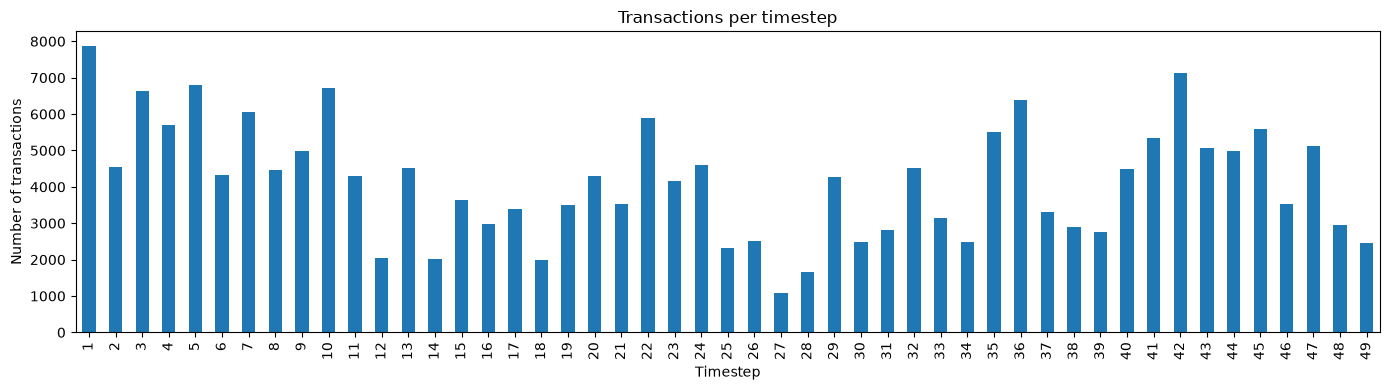

In [21]:
timestep_counts = (
    features_df.iloc[:, 1]
    .value_counts()
    .sort_index()
)

display(timestep_counts.rename("transaction_count").to_frame())

timestep_counts.plot(
    kind="bar",
    figsize=(14, 4),
    title="Transactions per timestep"
)

plt.xlabel("Timestep")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

In [22]:
time_label_df = transactions_df.loc[:, ['txId', 'timestep','class']]

In [23]:
time_label_df.head()

,txId,timestep,class
0,230425980,1,unknown
1,5530458,1,unknown
2,232022460,1,unknown
3,232438397,1,2
4,230460314,1,unknown


In [24]:
label_counts_by_time = pd.crosstab(
    time_label_df['timestep'],
    time_label_df['class']
).sort_index()

display(label_counts_by_time)

class,1,2,unknown
timestep,,,
1,17,2130,5733
2,18,1099,3427
3,11,1268,5342
4,30,1410,4253
5,8,1874,4921
6,5,480,3843
7,102,1101,4845
8,67,1098,3292
9,248,530,4218


In [25]:
features_df.head()

,txId,timestep,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


In [26]:
# Map transaction ID -> timestep
tx_to_timestep = features_df.set_index("txId")["timestep"]

source_steps = edges_df["txId1"].map(tx_to_timestep)
target_steps = edges_df["txId2"].map(tx_to_timestep)

cross_timestep_edges = (
    source_steps != target_steps
)

print("Total edges:", len(edges_df))
print("Cross-timestep edges:", cross_timestep_edges.sum())

Total edges: 234355
Cross-timestep edges: 0


In [27]:
# Exclude txId and timestep from the numerical feature summaries.
local_features = features_df.iloc[:, 2:95]
neighbor_features = features_df.iloc[:, 95:167]

print("Local feature shape:", local_features.shape)
print("Neighbour aggregate shape:", neighbor_features.shape)

Local feature shape: (203769, 93)
Neighbour aggregate shape: (203769, 72)


In [28]:
print("Missing local values:", local_features.isna().sum().sum())
print("Missing aggregate values:", neighbor_features.isna().sum().sum())

print(
    "Constant local features:",
    (local_features.nunique(dropna=False) == 1).sum()
)

print(
    "Constant aggregate features:",
    (neighbor_features.nunique(dropna=False) == 1).sum()
)

Missing local values: 0
Missing aggregate values: 0
Constant local features: 0
Constant aggregate features: 0


In [29]:
local_stats = local_features.describe().T
neighbor_stats = neighbor_features.describe().T

with pd.option_context("display.max_rows", None):
    display(local_stats.round(3))

with pd.option_context("display.max_rows", None):
    display(neighbor_stats.round(3))

,count,mean,std,min,25%,50%,75%,max
2,203769.0,-0.0,1.0,-0.173,-0.173,-0.169,-0.132,71.682
3,203769.0,0.0,1.0,-0.211,-0.180,-0.133,-0.055,73.595
4,203769.0,0.0,1.0,-1.756,-1.201,0.464,1.019,2.684
5,203769.0,0.0,1.0,-0.122,-0.122,-0.122,-0.122,49.028
6,203769.0,0.0,1.0,-0.064,-0.044,-0.044,-0.044,260.091
7,203769.0,0.0,1.0,-0.113,-0.113,-0.113,-0.113,54.565
8,203769.0,-0.0,1.0,-0.062,-0.062,-0.062,-0.062,113.441
9,203769.0,-0.0,1.0,-0.164,-0.164,-0.162,-0.136,73.355
10,203769.0,0.0,1.0,-0.169,-0.169,-0.166,-0.132,72.318
11,203769.0,-0.0,1.0,-0.050,-0.050,-0.050,-0.050,189.187


,count,mean,std,min,25%,50%,75%,max
95,203769.0,0.0,1.0,-0.171,-0.171,-0.166,-0.118,48.940
96,203769.0,-0.0,1.0,-0.203,-0.202,-0.193,-0.124,127.114
97,203769.0,-0.0,1.0,-0.117,-0.117,-0.117,-0.117,175.009
98,203769.0,0.0,1.0,-0.193,-0.192,-0.183,-0.115,47.863
99,203769.0,-0.0,1.0,-2.566,-0.015,-0.015,-0.015,2.537
100,203769.0,-0.0,1.0,-2.570,-0.019,-0.019,-0.019,2.532
101,203769.0,0.0,1.0,-9.177,-0.941,-0.038,0.931,1.641
102,203769.0,0.0,1.0,-9.343,-0.969,-0.050,0.935,1.658
103,203769.0,0.0,1.0,-0.083,-0.083,-0.083,-0.083,91.536
104,203769.0,0.0,1.0,-9.314,-0.962,-0.046,0.937,1.657


In [30]:
print(
    "Non-finite local values:",
    (~np.isfinite(local_features.to_numpy())).sum()
)

print(
    "Non-finite aggregate values:",
    (~np.isfinite(neighbor_features.to_numpy())).sum()
)

Non-finite local values: 0
Non-finite aggregate values: 0


In [31]:
local_stats = local_features.describe().T

local_summary = pd.DataFrame({
    "mean": local_stats["mean"],
    "std": local_stats["std"],
    "median": local_stats["50%"],
    "min": local_stats["min"],
    "max": local_stats["max"],
    "range": local_stats["max"] - local_stats["min"],
    "skewness": local_features.skew()
})

display(
    local_summary
    .sort_values("max", ascending=False)
    .head(15)
    .round(3)
)

,mean,std,median,min,max,range,skewness
37,0.0,1.0,-0.023,-0.023,289.204,289.227,148.301
35,-0.0,1.0,-0.025,-0.025,287.892,287.916,235.936
38,0.0,1.0,-0.026,-0.026,280.566,280.592,222.670
36,-0.0,1.0,-0.031,-0.031,269.701,269.732,200.436
15,-0.0,1.0,-0.043,-0.063,265.263,265.326,129.067
6,0.0,1.0,-0.044,-0.064,260.091,260.154,122.457
11,-0.0,1.0,-0.050,-0.050,189.187,189.237,71.876
17,0.0,1.0,-0.056,-0.057,183.257,183.315,86.930
71,0.0,1.0,-0.017,-0.017,152.189,152.206,91.431
74,0.0,1.0,-0.015,-0.015,151.035,151.050,129.565


In [32]:
neighbor_stats = neighbor_features.describe().T

neighbor_summary = pd.DataFrame({
    "mean": neighbor_stats["mean"],
    "std": neighbor_stats["std"],
    "median": neighbor_stats["50%"],
    "min": neighbor_stats["min"],
    "max": neighbor_stats["max"],
    "range": neighbor_stats["max"] - neighbor_stats["min"],
    "skewness": neighbor_features.skew()
})

display(
    neighbor_summary
    .sort_values("max", ascending=False)
    .head(15)
    .round(3)
)

,mean,std,median,min,max,range,skewness
162,-0.0,1.0,-0.087,-0.126,251.849,251.975,109.982
163,0.0,1.0,-0.131,-0.131,238.783,238.915,103.896
131,-0.0,1.0,-0.122,-0.125,224.459,224.584,110.015
97,-0.0,1.0,-0.117,-0.117,175.009,175.126,56.187
96,-0.0,1.0,-0.193,-0.203,127.114,127.317,29.372
161,0.0,1.0,0.018,-0.216,117.069,117.285,97.171
164,-0.0,1.0,-0.098,-0.270,105.734,106.004,53.914
134,-0.0,1.0,-0.191,-0.215,92.492,92.707,29.464
103,0.0,1.0,-0.083,-0.083,91.536,91.619,24.273
133,0.0,1.0,-0.176,-0.189,75.501,75.690,27.677


C:\Users\Asus\AppData\Local\Temp\ipykernel_13344\3319604576.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(values, vert=False)
C:\Users\Asus\AppData\Local\Temp\ipykernel_13344\3319604576.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[row, 1].boxplot(values, vert=False)


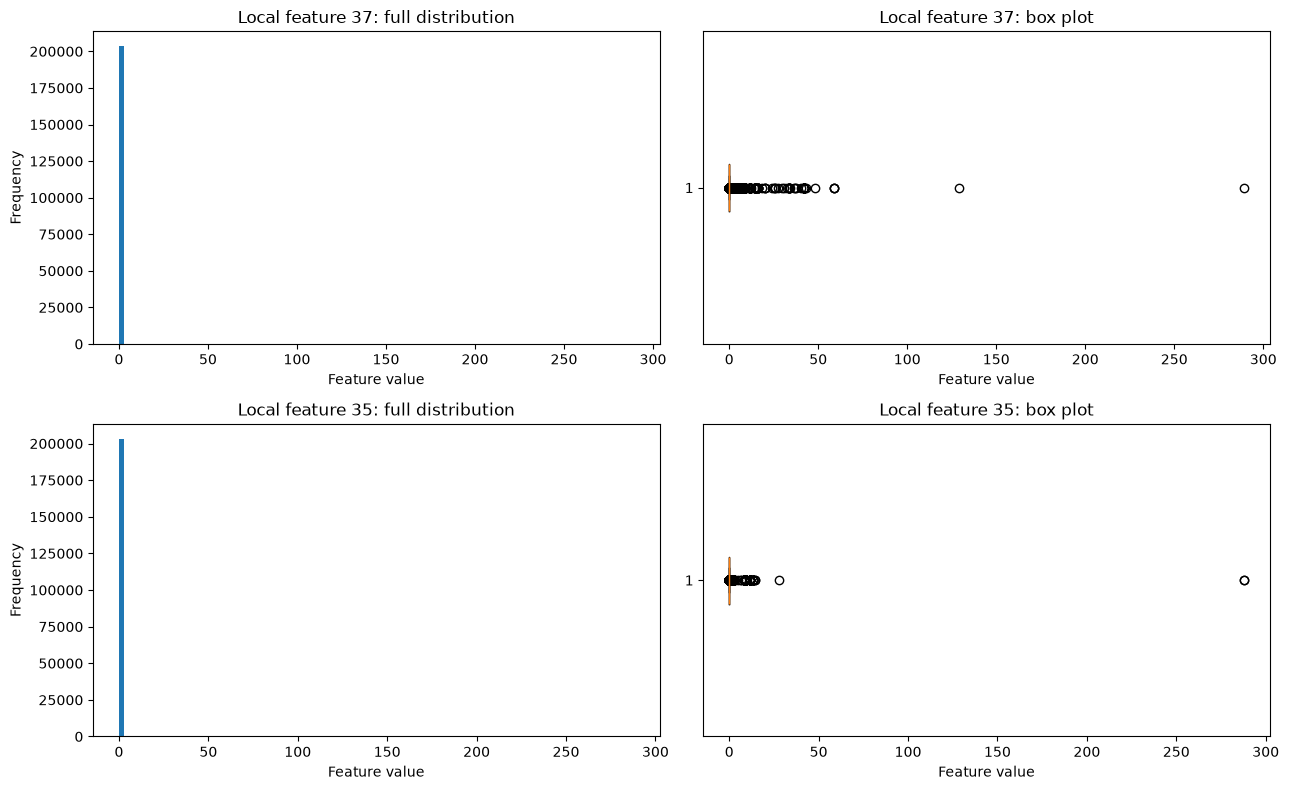

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for row, col in enumerate([37, 35]):
    values = local_features.iloc[:, col - 2]

    axes[row, 0].hist(values, bins=100)
    axes[row, 0].set_title(f"Local feature {col}: full distribution")
    axes[row, 0].set_xlabel("Feature value")
    axes[row, 0].set_ylabel("Frequency")

    axes[row, 1].boxplot(values, vert=False)
    axes[row, 1].set_title(f"Local feature {col}: box plot")
    axes[row, 1].set_xlabel("Feature value")

plt.tight_layout()
plt.show()

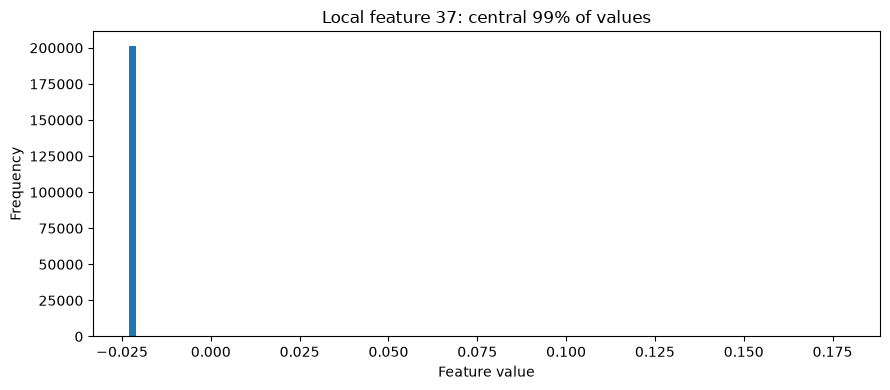

0.5th percentile: -0.0230451563960962
99.5th percentile: 0.17828896140450673
Full minimum: -0.0230451563960962
Full maximum: 289.20438805244663


In [34]:
values = local_features.iloc[:, 37 - 2]

lower, upper = values.quantile([0.005, 0.995])

plt.figure(figsize=(9, 4))
plt.hist(values, bins=100, range=(lower, upper))
plt.title("Local feature 37: central 99% of values")
plt.xlabel("Feature value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("0.5th percentile:", lower)
print("99.5th percentile:", upper)
print("Full minimum:", values.min())
print("Full maximum:", values.max())

In [35]:
values = local_features.iloc[:, 37 - 2]

print("Total transactions:", len(values))
print("Unique values:", values.nunique())
print("Minimum:", values.min())
print("Median:", values.median())
print("99th percentile:", values.quantile(0.99))
print("99.5th percentile:", values.quantile(0.995))
print("99.9th percentile:", values.quantile(0.999))
print("Maximum:", values.max())

print(
    "Transactions equal to minimum:",
    (values == values.min()).sum()
)

print(
    "Transactions above 1:",
    (values > 1).sum()
)

print(
    "Transactions above 10:",
    (values > 10).sum()
)

Total transactions: 203769
Unique values: 3908
Minimum: -0.0230451563960962
Median: -0.0230451563960962
99th percentile: -0.012674732146197343
99.5th percentile: 0.17828896140450673
99.9th percentile: 4.748400983273875
Maximum: 289.20438805244663
Transactions equal to minimum: 197319
Transactions above 1: 361
Transactions above 10: 100


In [36]:
# Join feature 37 with the labels for exploration.
feature_37_df = pd.DataFrame({
    "txId": features_df["txId"],
    "feature_37": local_features.iloc[:, 37 - 2]
}).merge(
    classes_df[["txId", "class"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

# Summarise the feature separately by label.
display(
    feature_37_df.groupby("class")["feature_37"]
    .agg(
        ["count", "median", "mean", "std", "min", "max"]
    )
    .round(4)
)

,count,median,mean,std,min,max
class,,,,,,
1,4545,-0.023,-0.023,0.0005,-0.023,-0.0071
2,42019,-0.023,0.081,1.6871,-0.023,129.0891
unknown,157205,-0.023,-0.021,0.7302,-0.023,289.2044


In [37]:
feature_37_df["above_1"] = feature_37_df["feature_37"] > 1

display(
    pd.crosstab(
        feature_37_df["class"],
        feature_37_df["above_1"],
        normalize="index"
    ).mul(100).round(3)
)

above_1,False,True
class,,
1,100.000,0.000
2,99.160,0.840
unknown,99.995,0.005


In [38]:
feature_37_df = feature_37_df.merge(
    features_df[["txId", "timestep"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

extreme_by_time = (
    feature_37_df.assign(above_1=lambda df: df["feature_37"] > 1)
    .groupby("timestep")
    .agg(
        transaction_count=("txId", "size"),
        extreme_count=("above_1", "sum"),
        max_feature_value=("feature_37", "max")
    )
)

extreme_by_time["extreme_percentage"] = (
    100 * extreme_by_time["extreme_count"]
    / extreme_by_time["transaction_count"]
)

display(
    extreme_by_time.sort_values(
        "extreme_count", ascending=False
    ).head(15).round(4)
)

,transaction_count,extreme_count,max_feature_value,extreme_percentage
timestep,,,,
45,5598,47,42.0723,0.8396
47,5121,28,42.0723,0.5468
41,5342,26,59.0595,0.4867
42,7140,17,42.0723,0.2381
46,3519,16,29.7429,0.4547
17,3385,16,7.0900,0.4727
43,5063,15,42.0723,0.2963
9,4996,14,8.6888,0.2802
40,4481,14,42.0723,0.3124


In [39]:
extreme_transactions = (
    feature_37_df.loc[
        feature_37_df["feature_37"] > 1,
        ["txId", "timestep", "class", "feature_37"]
    ]
    .sort_values("feature_37", ascending=False)
)

display(extreme_transactions.head(20))

print("Total transactions above 1:", len(extreme_transactions))

display(
    extreme_transactions["class"]
    .value_counts()
)

,txId,timestep,class,feature_37
115127,246026154,28,unknown,289.204388
126001,386157617,31,2,129.089084
162723,12691078,41,2,59.059530
161823,11102652,41,2,59.059530
162746,12694404,41,2,59.059530
164067,9550052,41,2,48.217676
162583,12673904,41,2,43.124767
186178,81789779,45,2,42.072324
157403,7951587,40,2,42.072324
167523,34717366,42,2,42.072324


Total transactions above 1: 361


class
2          353
unknown      8
Name: count, dtype: int64

## Temporal Split Decision

In [40]:
# Aggregate label counts for the proposed evaluation blocks.

split_blocks = {
    "Tuning fit (1-24)": (1, 24),
    "Tuning validation (25-29)": (25, 29),
    "Track A fit (1-30)": (1, 30),
    "Track A validation (31-34)": (31, 34),
    "Track A test (35-49)": (35, 49),
    "Track B test (35-38)": (35, 38),
    "Track B test (39-42)": (39, 42),
    "Track B test (43-46)": (43, 46),
    "Track B test (47-49)": (47, 49),
}

label_counts = pd.crosstab(
    transactions_df["timestep"],
    transactions_df["class"]
).reindex(columns=["1", "2", "unknown"], fill_value=0)

# Handle the case where the class labels are stored as integers.
if label_counts.sum().sum() == 0:
    label_counts = pd.crosstab(
        transactions_df["timestep"],
        transactions_df["class"]
    ).reindex(columns=[1, 2, "unknown"], fill_value=0)

rows = []

for block_name, (start, end) in split_blocks.items():
    block_counts = label_counts.loc[start:end].sum()

    illicit = int(block_counts.get("1", block_counts.get(1, 0)))
    licit = int(block_counts.get("2", block_counts.get(2, 0)))
    unknown = int(block_counts.get("unknown", 0))

    rows.append({
        "block": block_name,
        "timestep_range": f"{start}-{end}",
        "total_transactions": illicit + licit + unknown,
        "illicit": illicit,
        "licit": licit,
        "unknown": unknown,
        "known_label_count": illicit + licit,
        "illicit_pct_known": (
            100 * illicit / (illicit + licit)
            if illicit + licit else float("nan")
        )
    })

split_summary = pd.DataFrame(rows).set_index("block")
display(split_summary.round(2))


,timestep_range,total_transactions,illicit,licit,unknown,known_label_count,illicit_pct_known
block,,,,,,,
Tuning fit (1-24),1-24,108950,2219,21387,85344,23606,9.40
Tuning validation (25-29),25-29,11854,652,2123,9079,2775,23.50
Track A fit (1-30),1-30,123287,2954,23951,96382,26905,10.98
Track A validation (31-34),31-34,12978,508,2481,9989,2989,17.00
Track A test (35-49),35-49,67504,1083,15587,50834,16670,6.50
Track B test (35-38),35-38,18097,366,3937,13794,4303,8.51
Track B test (39-42),39-42,19723,548,5132,14043,5680,9.65
Track B test (43-46),43-46,19155,55,4839,14261,4894,1.12
Track B test (47-49),47-49,10529,114,1679,8736,1793,6.36


In [41]:

from pathlib import Path
import yaml

project_root = Path.cwd().parent

config_path = project_root / "configs" / "splits.yaml"

with config_path.open("r", encoding="utf-8") as f:
    split_config = yaml.safe_load(f)


def expand_range(bounds):
    """Convert an inclusive [start, end] range into a set of timesteps."""
    start, end = bounds
    assert start <= end, f"Invalid range: {bounds}"
    return set(range(start, end + 1))

def check_split(name, fit, validation, test):
    fit_steps = expand_range(fit)
    val_steps = expand_range(validation)
    test_steps = expand_range(test)

    # No timestep may appear in more than one partition.
    assert fit_steps.isdisjoint(val_steps), f"{name}: fit overlaps validation"
    assert fit_steps.isdisjoint(test_steps), f"{name}: fit overlaps test"
    assert val_steps.isdisjoint(test_steps), f"{name}: validation overlaps test"

    # Enforce chronological ordering.
    assert max(fit_steps) < min(val_steps), f"{name}: fit is not before validation"
    assert max(val_steps) < min(test_steps), f"{name}: validation is not before test"

    # Every timestep from 1 to 49 should be within the dataset's stated bounds.
    assert min(fit_steps) >= 1 and max(test_steps) <= 49

    print(
        f"{name}: PASS | "
        f"fit {min(fit_steps)}-{max(fit_steps)} | "
        f"validation {min(val_steps)}-{max(val_steps)} | "
        f"test {min(test_steps)}-{max(test_steps)}"
    )

# 2. Validate the tuning split.
check_split(
    "Tuning",
    [split_config["tuning"]["fit"]["start"],
     split_config["tuning"]["fit"]["end"]],
    [split_config["tuning"]["validation"]["start"],
     split_config["tuning"]["validation"]["end"]],
    [30, 30],  # Placeholder boundary check only; tuning is not a final evaluation.
)


Tuning: PASS | fit 1-24 | validation 25-29 | test 30-30


In [42]:

# Validate tuning separately.
tuning_fit = expand_range([
    split_config["tuning"]["fit"]["start"],
    split_config["tuning"]["fit"]["end"],
])
tuning_val = expand_range([
    split_config["tuning"]["validation"]["start"],
    split_config["tuning"]["validation"]["end"],
])

assert tuning_fit.isdisjoint(tuning_val)
assert max(tuning_fit) < min(tuning_val)
assert min(tuning_fit) == 1 and max(tuning_fit) == 24
assert min(tuning_val) == 25 and max(tuning_val) == 29

print("Tuning: PASS | fit 1-24 | validation 25-29")

# Validate Track A.
track_a = split_config["track_a"]
check_split(
    "Track A",
    [track_a["fit"]["start"], track_a["fit"]["end"]],
    [track_a["validation"]["start"], track_a["validation"]["end"]],
    [track_a["test"]["start"], track_a["test"]["end"]],
)

# Validate all Track B windows.
for window in split_config["track_b"]:
    check_split(
        window["name"],
        window["fit"],
        window["validation"],
        window["test"],
    )

# Confirm the Track B test windows cover timesteps 35-49 exactly once.
track_b_test_steps = [
    step
    for window in split_config["track_b"]
    for step in expand_range(window["test"])
]

assert sorted(track_b_test_steps) == list(range(35, 50))
assert len(track_b_test_steps) == len(set(track_b_test_steps))

print("Track B test coverage: PASS | timesteps 35-49 covered exactly once")


Tuning: PASS | fit 1-24 | validation 25-29
Track A: PASS | fit 1-30 | validation 31-34 | test 35-49
cutoff_34: PASS | fit 1-30 | validation 31-34 | test 35-38
cutoff_38: PASS | fit 1-34 | validation 35-38 | test 39-42
cutoff_42: PASS | fit 1-38 | validation 39-42 | test 43-46
cutoff_46: PASS | fit 1-42 | validation 43-46 | test 47-49
Track B test coverage: PASS | timesteps 35-49 covered exactly once


In [43]:
import pandas as pd

# Keep transaction metadata separate from model inputs.
transaction_metadata = features_df[["txId", "timestep"]].copy()

# Use the existing CSV column positions established during EDA.
X_local = features_df.iloc[:, 2:95].copy()
X_neighbour = features_df.iloc[:, 95:167].copy()

# Give the features descriptive, unambiguous column names.
X_local.columns = [f"local_{i}" for i in range(X_local.shape[1])]
X_neighbour.columns = [
    f"neighbour_{i}" for i in range(X_neighbour.shape[1])
]

# All = local transaction features + supplied neighbour aggregates.
X_all = pd.concat([X_local, X_neighbour], axis=1)

# Preserve transaction IDs as the index so rows can be aligned later.
X_local.index = features_df["txId"].to_numpy()
X_all.index = features_df["txId"].to_numpy()
transaction_metadata.index = features_df["txId"].to_numpy()

# Basic structural checks.
assert X_local.shape == (203769, 93)
assert X_all.shape == (203769, 165)
assert X_local.index.is_unique
assert X_all.index.is_unique
assert X_local.index.equals(X_all.index)
assert "timestep" not in X_local.columns
assert "timestep" not in X_all.columns

print("Local shape:", X_local.shape)
print("All shape:", X_all.shape)
print("Local feature example:", X_local.columns[:5].tolist())
print("Neighbour feature example:", X_neighbour.columns[:5].tolist())
print("Timestep excluded from model inputs: PASS")


Local shape: (203769, 93)
All shape: (203769, 165)
Local feature example: ['local_0', 'local_1', 'local_2', 'local_3', 'local_4']
Neighbour feature example: ['neighbour_0', 'neighbour_1', 'neighbour_2', 'neighbour_3', 'neighbour_4']
Timestep excluded from model inputs: PASS


In [44]:
#csr_matrix

from scipy.sparse import csr_matrix

A = csr_matrix([
    [0, 2, 0],
    [0, 0, 1],
    [0, 0, 0]
])

print("Original matrix:")
print(A.toarray())

print("\nStored values:")
print(A.data)

print("\nFirst stored value:")
print(A.data[0])

# Modify only the first stored value
A.data[0] = 0

print("\nMatrix after A.data[0] = 0:")
print(A.toarray())

print("\nStored values before eliminate_zeros:")
print(A.data)

# Remove explicitly stored zeros
A.eliminate_zeros()

print("\nStored values after eliminate_zeros:")
print(A.data)

Original matrix:
[[0 2 0]
 [0 0 1]
 [0 0 0]]

Stored values:
[2 1]

First stored value:
2

Matrix after A.data[0] = 0:
[[0 0 0]
 [0 0 1]
 [0 0 0]]

Stored values before eliminate_zeros:
[0 1]

Stored values after eliminate_zeros:
[1]


In [45]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix


def build_handcrafted_features(local_features, edges, timesteps):
    """
    Build label-free, directed graph features.

    Parameters
    ----------
    local_features : DataFrame
        Local features indexed by transaction ID.
    edges : DataFrame
        Directed edges with columns txId1 (source) and txId2 (target).
    timesteps : Series
        Timestep for each transaction, indexed by transaction ID.

    Returns
    -------
    DataFrame
        Degree features and one-hop/two-hop neighbour means.
    """
    node_ids = local_features.index
    n_nodes = len(node_ids)

    if not node_ids.is_unique:
        raise ValueError("Local feature index must contain unique transaction IDs.")

    if not timesteps.index.is_unique:
        raise ValueError("Timestep index must contain unique transaction IDs.")

    if not node_ids.isin(timesteps.index).all():
        raise ValueError("Some feature nodes have no timestep.")

    # Map transaction IDs to consecutive matrix row/column positions.
    node_to_idx = pd.Series(
        np.arange(n_nodes),
        index=node_ids
    )

    src = edges["txId1"].map(node_to_idx)
    dst = edges["txId2"].map(node_to_idx)

    if src.isna().any() or dst.isna().any():
        raise ValueError("An edge references a transaction absent from local_features.")

    src = src.to_numpy(dtype=np.int64)
    dst = dst.to_numpy(dtype=np.int64)

    # Explicitly enforce the no-cross-timestep rule.
    source_steps = timesteps.reindex(edges["txId1"]).to_numpy()
    target_steps = timesteps.reindex(edges["txId2"]).to_numpy()

    if pd.isna(source_steps).any() or pd.isna(target_steps).any():
        raise ValueError("An edge endpoint has no timestep.")

    if not np.array_equal(source_steps, target_steps):
        raise ValueError("Cross-timestep edges found.")

    # A[i, j] = 1 means there is a directed edge i -> j.
    A = csr_matrix(
        (np.ones(len(src), dtype=np.int32), (src, dst)),
        shape=(n_nodes, n_nodes),
        dtype=np.int32,
    )
    A.sum_duplicates()
    A.data[:] = 1
    A.eliminate_zeros()

    # Exactly-two-edge reachability. (Graph theory concept: (A^k)ij represents no. of directed walks of length k from node i to j)
    # Convert path counts to binary values so each destination is counted once.
    A2 = (A @ A).tocsr()
    A2.data[:] = 1

    # Exclude the source node itself if a two-edge cycle reaches it.
    A2.setdiag(0)
    A2.eliminate_zeros()

    # Use float32 to reduce memory consumption.
    X = local_features.to_numpy(dtype=np.float32, copy=True)

    def neighbour_mean(adjacency):
        counts = np.asarray(adjacency.sum(axis=1)).ravel()  #(ravel flattens it)
        sums = adjacency @ X

        # Zero-neighbour rows remain zero.
        means = np.zeros_like(sums, dtype=np.float32)
        has_neighbours = counts > 0
        means[has_neighbours] = (
            sums[has_neighbours] / counts[has_neighbours, None]
        )

        return means, counts

    # One-hop means.
    incoming_1, in_degree = neighbour_mean(A.T.tocsr())
    outgoing_1, out_degree = neighbour_mean(A)

    # Two-hop means, with unique destinations.
    incoming_2, in_degree_2 = neighbour_mean(A2.T.tocsr())
    outgoing_2, out_degree_2 = neighbour_mean(A2)

    # Assemble a reproducibly named feature table.
    result = pd.DataFrame(index=node_ids)

    result["hand_in_degree"] = in_degree
    result["hand_out_degree"] = out_degree

    feature_names = local_features.columns

    for prefix, values in [
        ("hand_in1_mean", incoming_1),
        ("hand_out1_mean", outgoing_1),
        ("hand_in2_mean", incoming_2),
        ("hand_out2_mean", outgoing_2),
    ]:
        block = pd.DataFrame(
            values,
            index=node_ids,
            columns=[f"{prefix}_{name}" for name in feature_names],
        )
        result = pd.concat([result, block], axis=1)

    # Diagnostic counts are useful for testing but aren't model features.
    diagnostics = pd.DataFrame(
        {
            "in_degree_2hop_unique": in_degree_2,
            "out_degree_2hop_unique": out_degree_2,
        },
        index=node_ids,
    )

    return result, diagnostics


In [46]:
toy_X = pd.DataFrame(
    {
        "f1": [10.0, 20.0, 30.0, 40.0],
        "f2": [1.0, 2.0, 3.0, 4.0],
    },
    index=pd.Index([101, 102, 103, 104], name="txId"),
)

toy_edges = pd.DataFrame(
    {
        "txId1": [101, 102, 104],
        "txId2": [102, 103, 102],
    }
)

toy_timesteps = pd.Series(
    {101: 1, 102: 1, 103: 1, 104: 1},
    name="timestep",
)

toy_hand, toy_diagnostics = build_handcrafted_features(
    toy_X, toy_edges, toy_timesteps
)

display(toy_hand)
display(toy_diagnostics)

# Node 102 receives edges from 101 and 104.
assert toy_hand.loc[102, "hand_in_degree"] == 2
assert np.isclose(toy_hand.loc[102, "hand_in1_mean_f1"], 25.0)

# Node 102 has one outgoing edge, to node 103.
assert toy_hand.loc[102, "hand_out_degree"] == 1
assert np.isclose(toy_hand.loc[102, "hand_out1_mean_f1"], 30.0)

# Node 101 reaches node 103 in exactly two steps: 101 -> 102 -> 103.
assert np.isclose(toy_hand.loc[101, "hand_out2_mean_f1"], 30.0)

# Node 103 has no outgoing neighbours; its means should be zero.
assert toy_hand.loc[103, "hand_out_degree"] == 0
assert np.allclose(
    toy_hand.loc[103, [c for c in toy_hand.columns if c.startswith("hand_out1_mean_")]].to_numpy(dtype=float),
    0.0,
)

print("Synthetic graph feature tests: PASS")


,hand_in_degree,hand_out_degree,hand_in1_mean_f1,hand_in1_mean_f2,hand_out1_mean_f1,hand_out1_mean_f2,hand_in2_mean_f1,hand_in2_mean_f2,hand_out2_mean_f1,hand_out2_mean_f2
txId,,,,,,,,,,
101,0,1,0.0,0.0,20.0,2.0,0.0,0.0,30.0,3.0
102,2,1,25.0,2.5,30.0,3.0,0.0,0.0,0.0,0.0
103,1,0,20.0,2.0,0.0,0.0,25.0,2.5,0.0,0.0
104,0,1,0.0,0.0,20.0,2.0,0.0,0.0,30.0,3.0


,in_degree_2hop_unique,out_degree_2hop_unique
txId,,
101,0,1
102,0,0
103,2,0
104,0,1


Synthetic graph feature tests: PASS


In [28]:
# Align timesteps to the same transaction IDs used by X_local.
timesteps_by_id = transaction_metadata["timestep"]

X_hand, hand_diagnostics = build_handcrafted_features(
    local_features=X_local,
    edges=edges_df,
    timesteps=timesteps_by_id,
)

X_local_hand = pd.concat([X_local, X_hand], axis=1)

assert X_hand.index.equals(X_local.index)
assert X_local_hand.shape == (203769, 467)
assert X_local_hand.columns.is_unique
assert "timestep" not in X_local_hand.columns

print("Handcrafted feature shape:", X_hand.shape)
print("Local+Hand shape:", X_local_hand.shape)
print("Feature columns unique:", X_local_hand.columns.is_unique)


Handcrafted feature shape: (203769, 374)
Local+Hand shape: (203769, 467)
Feature columns unique: True


In [48]:
# Summary of unique two-hop neighbour counts
display(hand_diagnostics.describe().T)

# How many transactions have no two-hop neighbours?
print(
    "No incoming 2-hop neighbours:",
    (hand_diagnostics["in_degree_2hop_unique"] == 0).sum()
)

print(
    "No outgoing 2-hop neighbours:",
    (hand_diagnostics["out_degree_2hop_unique"] == 0).sum()
)

,count,mean,std,min,25%,50%,75%,max
in_degree_2hop_unique,203769.0,1.189646,5.485187,0.0,0.0,1.0,1.0,297.0
out_degree_2hop_unique,203769.0,1.189646,3.101147,0.0,0.0,1.0,1.0,477.0


No incoming 2-hop neighbours: 89651
No outgoing 2-hop neighbours: 75142


In [49]:
# 1. Check for missing and infinite values.
print("Missing values:", X_hand.isna().sum().sum())

print(
    "Infinite values:",
    np.isinf(X_hand.to_numpy()).sum()
)

# 2. Check row alignment.
print("Index alignment:", X_hand.index.equals(X_local.index))

# 3. Check feature groups.
feature_groups = {
    "Degree": [
        "hand_in_degree",
        "hand_out_degree"
    ],
    "Incoming 1-hop": [
        c for c in X_hand.columns if c.startswith("hand_in1_mean_")
    ],
    "Outgoing 1-hop": [
        c for c in X_hand.columns if c.startswith("hand_out1_mean_")
    ],
    "Incoming 2-hop": [
        c for c in X_hand.columns if c.startswith("hand_in2_mean_")
    ],
    "Outgoing 2-hop": [
        c for c in X_hand.columns if c.startswith("hand_out2_mean_")
    ],
}

for group, columns in feature_groups.items():
    print(f"{group}: {len(columns)} columns")

# 4. Check degree distributions.
display(
    X_hand[["hand_in_degree", "hand_out_degree"]]
    .describe()
)

assert X_hand.isna().sum().sum() == 0
assert np.isfinite(X_hand.to_numpy()).all()
assert X_hand.index.equals(X_local.index)
assert all(len(columns) == 93 for group, columns in feature_groups.items()
           if group != "Degree")

print("Handcrafted feature sanity checks: PASS")

Missing values: 0
Infinite values: 0
Index alignment: True
Degree: 2 columns
Incoming 1-hop: 93 columns
Outgoing 1-hop: 93 columns
Incoming 2-hop: 93 columns
Outgoing 2-hop: 93 columns


,hand_in_degree,hand_out_degree
count,203769.000000,203769.000000
mean,1.150101,1.150101
std,3.911132,1.894740
min,0.000000,0.000000
25%,0.000000,1.000000
50%,1.000000,1.000000
75%,1.000000,1.000000
max,284.000000,472.000000


Handcrafted feature sanity checks: PASS


### Label Homophily

In [50]:
import pandas as pd
import numpy as np

# Map transaction IDs to their known labels.
label_map = transactions_df.set_index("txId")["class"].astype(str).str.strip()

source_labels = edges_df["txId1"].map(label_map)
target_labels = edges_df["txId2"].map(label_map)

known_labels = {"1", "2"}

eligible_mask = (
    source_labels.isin(known_labels)
    & target_labels.isin(known_labels)
)

eligible_source = source_labels[eligible_mask]
eligible_target = target_labels[eligible_mask]

# Count directed edges by their endpoint classes.
edge_types = pd.DataFrame({
    "source_label": eligible_source,
    "target_label": eligible_target
})

edge_counts = {
    "Illicit-Illicit": (
        (edge_types["source_label"] == "1")
        & (edge_types["target_label"] == "1")
    ).sum(),

    "Licit-Licit": (
        (edge_types["source_label"] == "2")
        & (edge_types["target_label"] == "2")
    ).sum(),

    "Illicit-Licit": (
        (edge_types["source_label"] == "1")
        & (edge_types["target_label"] == "2")
    ).sum(),

    "Licit-Illicit": (
        (edge_types["source_label"] == "2")
        & (edge_types["target_label"] == "1")
    ).sum()
}

total_eligible_edges = len(edge_types)

same_class_edges = (
    edge_counts["Illicit-Illicit"]
    + edge_counts["Licit-Licit"]
)

mixed_class_edges = (
    edge_counts["Illicit-Licit"]
    + edge_counts["Licit-Illicit"]
)

homophily = same_class_edges / total_eligible_edges

print("Total directed edges:", len(edges_df))
print("Eligible labelled edges:", total_eligible_edges)
print("Edges excluded due to unknown endpoints:", len(edges_df) - total_eligible_edges)

print("\nEdge type counts and proportions:")

edge_summary = pd.DataFrame({
    "edge_count": edge_counts,
    "percentage": {
        edge_type: count / total_eligible_edges * 100
        for edge_type, count in edge_counts.items()
    }
})

display(edge_summary)

print(f"\nSame-class edges: {same_class_edges}")
print(f"Mixed-class edges: {mixed_class_edges}")
print(f"Overall label homophily: {homophily:.4f} ({homophily * 100:.2f}%)")


Total directed edges: 234355
Eligible labelled edges: 36624
Edges excluded due to unknown endpoints: 197731

Edge type counts and proportions:


,edge_count,percentage
Illicit-Illicit,998,2.724989
Licit-Licit,33930,92.644168
Illicit-Licit,915,2.498362
Licit-Illicit,781,2.132481



Same-class edges: 34928
Mixed-class edges: 1696
Overall label homophily: 0.9537 (95.37%)


In [51]:
Root = Path.cwd()
print(Root)

c:\Users\Asus\Projects\graph-financial-crime\notebooks


In [52]:
labels = classes_df.set_index("txId")["class"]
labels.index.name = X_local.index.name

In [53]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fincrime.evaluation.splits import load_split_config
from fincrime.baselines.data import prepare_tabular_data

split_config = load_split_config(PROJECT_ROOT/"configs/splits.yaml")

local_data = prepare_tabular_data(
    features=X_local,
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    split_name="tuning",
)

print("Training data")
print("X_train:", local_data["X_train"].shape)
print("y_train:", local_data["y_train"].shape)

print("\nValidation data")
print("X_validation:", local_data["X_validation"].shape)
print("y_validation:", local_data["y_validation"].shape)

print("\nTraining class distribution")
print(local_data["y_train"].value_counts().sort_index())

print("\nValidation class distribution")
print(local_data["y_validation"].value_counts().sort_index())

Training data
X_train: (23606, 93)
y_train: (23606,)

Validation data
X_validation: (2775, 93)
y_validation: (2775,)

Training class distribution
class
0    21387
1     2219
Name: count, dtype: int64

Validation class distribution
class
0    2123
1     652
Name: count, dtype: int64


In [54]:
print("Training timestep range:")
print(
    transaction_metadata.loc[
        local_data["train_ids"], "timestep"
    ].agg(["min", "max"])
)

print("\nValidation timestep range:")
print(
    transaction_metadata.loc[
        local_data["validation_ids"], "timestep"
    ].agg(["min", "max"])
)

print(
    "\nOverlapping transaction IDs:",
    len(
        set(local_data["train_ids"])
        & set(local_data["validation_ids"])
    ),
)

Training timestep range:
min     1
max    24
Name: timestep, dtype: int64

Validation timestep range:
min    25
max    29
Name: timestep, dtype: int64

Overlapping transaction IDs: 0


### Model Experiments

In [55]:
from fincrime.baselines.data import prepare_tabular_data

timesteps = transaction_metadata["timestep"]

tuning_data = prepare_tabular_data(
    features=X_local,
    labels=labels,
    timesteps=timesteps,
    split_config=split_config,
    split_name="tuning",
)

X_train = tuning_data["X_train"]
y_train = tuning_data["y_train"]

X_validation = tuning_data["X_validation"]
y_validation = tuning_data["y_validation"]

print("Training:", X_train.shape)
print("Validation:", X_validation.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_validation.value_counts())

Training: (23606, 93)
Validation: (2775, 93)

Training class distribution:
class
0    21387
1     2219
Name: count, dtype: int64

Validation class distribution:
class
0    2123
1     652
Name: count, dtype: int64


In [56]:
import pandas as pd

from fincrime.baselines.training import train_and_evaluate

model_names = [
    "logistic_regression",
    "random_forest",
    "xgboost",
]

baseline_results = []

for model_name in model_names:

    print(f"\nTraining {model_name}...")

    result = train_and_evaluate(
        model_name=model_name,
        X_train=X_train,
        y_train=y_train,
        X_validation=X_validation,
        y_validation=y_validation,
        random_state=42,
    )

    baseline_results.append({
        "model": model_name,
        "average_precision": result["average_precision"],
        "roc_auc": result["roc_auc"],
        "validation_prevalence": result["validation_prevalence"],
    })

baseline_results_df = pd.DataFrame(baseline_results)

baseline_results_df.sort_values(
    by="average_precision",
    ascending=False,
).reset_index(drop=True)


Training logistic_regression...

Training random_forest...

Training xgboost...


,model,average_precision,roc_auc,validation_prevalence
0,xgboost,0.991397,0.996699,0.234955
1,random_forest,0.989618,0.995901,0.234955
2,logistic_regression,0.647084,0.900529,0.234955


In [57]:
from fincrime.baselines.data import prepare_tabular_data

feature_sets = {
    "local": X_local,
    "all": X_all,
    "local_hand": X_local_hand,
}

tuning_datasets = {}

for feature_name, features in feature_sets.items():

    tuning_datasets[feature_name] = prepare_tabular_data(
        features=features,
        labels=labels,
        timesteps=timesteps,
        split_config=split_config,
        split_name="tuning",
    )

    print(
        feature_name,
        tuning_datasets[feature_name]["X_train"].shape,
        tuning_datasets[feature_name]["X_validation"].shape,
    )

local (23606, 93) (2775, 93)
all (23606, 165) (2775, 165)
local_hand (23606, 467) (2775, 467)


In [58]:
feature_sets = {
    "Local": X_local,
    "All": X_all,
    "Local+Hand": X_local_hand,
}

timesteps = transaction_metadata["timestep"]

In [59]:
from fincrime.baselines.tuning_runner import run_xgboost_tuning

tuning_results = run_xgboost_tuning(
    feature_sets=feature_sets,
    labels=labels,
    timesteps=timesteps,
    split_config=split_config,
    config_path=PROJECT_ROOT / "configs" / "xgboost.yaml",
    experiment_name="elliptic-xgboost-tuning",
    tracking_uri="http://127.0.0.1:5000",
)

c:\Users\Asus\Projects\graph-financial-crime\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/02 19:58:21 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-xgboost-tuning' does not exist. Creating a new experiment.



Feature set: Local

Running Local | trial_01_baseline_shallow
  Validation AP: 0.987725
  Validation ROC-AUC: 0.995215
🏃 View run Local__trial_01_baseline_shallow at: http://127.0.0.1:5000/#/experiments/2/runs/c9f3ea7353e746c999db6b9e824c6eac
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

Running Local | trial_02_baseline_medium
  Validation AP: 0.990694
  Validation ROC-AUC: 0.996385
🏃 View run Local__trial_02_baseline_medium at: http://127.0.0.1:5000/#/experiments/2/runs/31d895b7bf5d4f269f05c40546fe8512
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

Running Local | trial_03_baseline_deep
  Validation AP: 0.991510
  Validation ROC-AUC: 0.996832
🏃 View run Local__trial_03_baseline_deep at: http://127.0.0.1:5000/#/experiments/2/runs/dcd89dc0742847bc838790c5e8dc0397
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2

Running Local | trial_04_weighted_shallow
  Validation AP: 0.988608
  Validation ROC-AUC: 0.995879
🏃 View run Local__trial_04_weighted_

In [60]:
for feature_set, results in tuning_results.items():
    best = results["best_trial"]

    print(f"\nFeature set: {feature_set}")
    print(f"Best trial: {best['trial_name']}")
    print(f"Validation AP: {best['average_precision']:.6f}")
    print(f"Validation ROC-AUC: {best['roc_auc']:.6f}")
    print(f"MLflow run ID: {best['run_id']}")


Feature set: Local
Best trial: trial_03_baseline_deep
Validation AP: 0.991510
Validation ROC-AUC: 0.996832
MLflow run ID: dcd89dc0742847bc838790c5e8dc0397

Feature set: All
Best trial: trial_03_baseline_deep
Validation AP: 0.990161
Validation ROC-AUC: 0.996735
MLflow run ID: b887370a084b4de29d8584d3d6a53221

Feature set: Local+Hand
Best trial: trial_02_baseline_medium
Validation AP: 0.992933
Validation ROC-AUC: 0.997105
MLflow run ID: 3e1f1940949748c08bb3ef7a44c2e466


In [63]:
best_local_model = tuning_results["Local"]["best_model"]
best_all_model = tuning_results["All"]["best_model"]
best_local_hand_model = tuning_results["Local+Hand"]["best_model"]

In [64]:
import pandas as pd
import mlflow
from mlflow import MlflowClient
from datetime import datetime, timezone

client = MlflowClient(tracking_uri="http://127.0.0.1:5000")

experiment = client.get_experiment_by_name("elliptic-xgboost-tuning")

if experiment is None:
    raise ValueError("MLflow experiment not found.")

runs = client.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="tags.model = 'xgboost'",
    max_results=1000,
)

print(f"Retrieved {len(runs)} runs.")

if len(runs) != 18:
    raise ValueError(
        f"Expected 18 XGBoost tuning runs, but found {len(runs)}."
    )

rows = []

for run in runs:
    row = {
        "run_id": run.info.run_id,
        "run_name": run.info.run_name,
        "status": run.info.status,
        "start_time_utc": datetime.fromtimestamp(
            run.info.start_time / 1000,
            tz=timezone.utc,
        ).isoformat(),
    }

    # Include all logged parameters.
    row.update({
        f"param_{key}": value
        for key, value in run.data.params.items()
    })

    # Include all logged metrics.
    row.update({
        f"metric_{key}": value
        for key, value in run.data.metrics.items()
    })

    rows.append(row)

tuning_summary = pd.DataFrame(rows)

tuning_summary = tuning_summary.sort_values(
    by=["param_feature_set", "metric_validation_average_precision"],
    ascending=[True, False],
).reset_index(drop=True)

# Save the complete comparison table.
reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

summary_path = reports_dir / "xgboost_tuning_summary.csv"
tuning_summary.to_csv(summary_path, index=False)

print(f"Saved summary to: {summary_path}")

# Display the most useful comparison columns.
display_columns = [
    "param_feature_set",
    "param_trial_name",
    "param_scale_pos_weight",
    "param_model__max_depth",
    "param_model__min_child_weight",
    "param_model__reg_lambda",
    "metric_validation_average_precision",
    "metric_validation_roc_auc",
    "metric_n_train",
    "metric_n_validation",
]

display(tuning_summary[display_columns])

Retrieved 18 runs.
Saved summary to: c:\Users\Asus\Projects\graph-financial-crime\reports\xgboost_tuning_summary.csv


,param_feature_set,param_trial_name,param_scale_pos_weight,param_model__max_depth,param_model__min_child_weight,param_model__reg_lambda,metric_validation_average_precision,metric_validation_roc_auc,metric_n_train,metric_n_validation
0,All,trial_03_baseline_deep,1.0,7,1,1.0,0.990161,0.996735,23606.0,2775.0
1,All,trial_06_weighted_regularised,9.638125281658406,5,5,5.0,0.990112,0.996685,23606.0,2775.0
2,All,trial_02_baseline_medium,1.0,5,1,1.0,0.989933,0.996526,23606.0,2775.0
3,All,trial_05_weighted_medium,9.638125281658406,5,1,1.0,0.989605,0.996620,23606.0,2775.0
4,All,trial_01_baseline_shallow,1.0,3,1,1.0,0.987165,0.995662,23606.0,2775.0
5,All,trial_04_weighted_shallow,9.638125281658406,3,1,1.0,0.984822,0.995245,23606.0,2775.0
6,Local,trial_03_baseline_deep,1.0,7,1,1.0,0.991510,0.996832,23606.0,2775.0
7,Local,trial_05_weighted_medium,9.638125281658406,5,1,1.0,0.990888,0.996407,23606.0,2775.0
8,Local,trial_02_baseline_medium,1.0,5,1,1.0,0.990694,0.996385,23606.0,2775.0
9,Local,trial_06_weighted_regularised,9.638125281658406,5,5,5.0,0.989882,0.996029,23606.0,2775.0


In [65]:
best_trials_summary = (
    tuning_summary
    .sort_values(
        "metric_validation_average_precision",
        ascending=False,
    )
    .groupby("param_feature_set", as_index=False)
    .first()
)

display(
    best_trials_summary[
        [
            "param_feature_set",
            "param_trial_name",
            "metric_validation_average_precision",
            "metric_validation_roc_auc",
            "param_scale_pos_weight",
            "param_model__max_depth",
            "param_model__min_child_weight",
            "param_model__reg_lambda",
        ]
    ]
)

,param_feature_set,param_trial_name,metric_validation_average_precision,metric_validation_roc_auc,param_scale_pos_weight,param_model__max_depth,param_model__min_child_weight,param_model__reg_lambda
0,All,trial_03_baseline_deep,0.990161,0.996735,1.0,7,1,1.0
1,Local,trial_03_baseline_deep,0.991510,0.996832,1.0,7,1,1.0
2,Local+Hand,trial_02_baseline_medium,0.992933,0.997105,1.0,5,1,1.0


In [66]:
import json

selected_configs = {}

for feature_set, group in tuning_summary.groupby("param_feature_set"):

    best = group.loc[
        group["metric_validation_average_precision"].idxmax()
    ]

    selected_configs[feature_set] = {
        "trial_name": best["param_trial_name"],
        "validation_average_precision": float(
            best["metric_validation_average_precision"]
        ),
        "validation_roc_auc": float(
            best["metric_validation_roc_auc"]
        ),
        "scale_pos_weight": float(best["param_scale_pos_weight"]),
        "model_params": {
            "n_estimators": int(best["param_model__n_estimators"]),
            "max_depth": int(best["param_model__max_depth"]),
            "learning_rate": float(best["param_model__learning_rate"]),
            "min_child_weight": int(
                best["param_model__min_child_weight"]
            ),
            "subsample": float(best["param_model__subsample"]),
            "colsample_bytree": float(
                best["param_model__colsample_bytree"]
            ),
            "reg_lambda": float(best["param_model__reg_lambda"]),
        },
        "mlflow_run_id": best["run_id"],
    }

selected_config_path = reports_dir / "xgboost_selected_configs.json"

with selected_config_path.open("w", encoding="utf-8") as file:
    json.dump(selected_configs, file, indent=4)

print(f"Saved selected configurations to: {selected_config_path}")

Saved selected configurations to: c:\Users\Asus\Projects\graph-financial-crime\reports\xgboost_selected_configs.json


In [67]:
from fincrime.baselines.evaluation_runner import (
    run_track_a_tabular_baselines,
)

tabular_baseline_results = run_track_a_tabular_baselines(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=timesteps,
    split_config=split_config,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    experiment_name="elliptic-track-a-tabular-baselines",
)

2026/11/02 21:27:54 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-track-a-tabular-baselines' does not exist. Creating a new experiment.



Track A | Feature set: Local

Running Track_A__Local__logistic_regression
  Validation AP: 0.573005
  Validation ROC-AUC: 0.879854
  MLflow run ID: 335d5da0a50841e4b929e71980442cb4
🏃 View run Track_A__Local__logistic_regression at: http://127.0.0.1:5000/#/experiments/3/runs/335d5da0a50841e4b929e71980442cb4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__Local__random_forest
  Validation AP: 0.991203
  Validation ROC-AUC: 0.996428
  MLflow run ID: ced1d02f211f4b8f90ca6d9848f1baf9
🏃 View run Track_A__Local__random_forest at: http://127.0.0.1:5000/#/experiments/3/runs/ced1d02f211f4b8f90ca6d9848f1baf9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Track A | Feature set: All

Running Track_A__All__logistic_regression
  Validation AP: 0.642301
  Validation ROC-AUC: 0.916099
  MLflow run ID: ec96ba16a78a4096a8c4f32e03a2757c
🏃 View run Track_A__All__logistic_regression at: http://127.0.0.1:5000/#/experiments/3/runs/ec96ba16a78a4096a8c4f32e03a2757c
🧪

In [68]:
for (feature_set, model_name), result in tabular_baseline_results.items():
    print(
        f"{feature_set:12} | "
        f"{model_name:20} | "
        f"AP: {result['average_precision']:.6f} | "
        f"ROC-AUC: {result['roc_auc']:.6f}"
    )

Local        | logistic_regression  | AP: 0.573005 | ROC-AUC: 0.879854
Local        | random_forest        | AP: 0.991203 | ROC-AUC: 0.996428
All          | logistic_regression  | AP: 0.642301 | ROC-AUC: 0.916099
All          | random_forest        | AP: 0.992195 | ROC-AUC: 0.997210


In [69]:
from fincrime.baselines.track_a_runner import run_track_a_xgboost

track_a_xgb_results = run_track_a_xgboost(
    feature_sets={
        "Local": X_local,
        "All": X_all,
        "Local+Hand": X_local_hand,
    },
    labels=labels,
    timesteps=timesteps,
    split_config=split_config,
    selected_config_path=(
        PROJECT_ROOT / "reports" / "xgboost_selected_configs.json"
    ),
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    experiment_name="elliptic-track-a-xgboost",
)

2026/11/02 21:37:37 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-track-a-xgboost' does not exist. Creating a new experiment.



Track A | XGBoost | Local
Selected tuning trial: trial_03_baseline_deep
Validation AP: 0.990180
Validation ROC-AUC: 0.997636
MLflow run ID: f1138adf49584bd8ba7833280d5c2dec
🏃 View run Track_A__XGBoost__Local at: http://127.0.0.1:5000/#/experiments/4/runs/f1138adf49584bd8ba7833280d5c2dec
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4

Track A | XGBoost | All
Selected tuning trial: trial_03_baseline_deep
Validation AP: 0.989252
Validation ROC-AUC: 0.997834
MLflow run ID: e3894bf1c0ad459eb0b6526e2863564f
🏃 View run Track_A__XGBoost__All at: http://127.0.0.1:5000/#/experiments/4/runs/e3894bf1c0ad459eb0b6526e2863564f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4

Track A | XGBoost | Local+Hand
Selected tuning trial: trial_02_baseline_medium
Validation AP: 0.993425
Validation ROC-AUC: 0.998526
MLflow run ID: 6c583cc003e5408cb4e2be1e4cf92608
🏃 View run Track_A__XGBoost__Local+Hand at: http://127.0.0.1:5000/#/experiments/4/runs/6c583cc003e5408cb4e2be1e4cf92608
🧪 Vie

In [70]:
for feature_set, result in track_a_xgb_results.items():
    print(
        f"{feature_set:12} | "
        f"AP: {result['average_precision']:.6f} | "
        f"ROC-AUC: {result['roc_auc']:.6f} | "
        f"Trial: {result['source_tuning_trial']}"
    )

Local        | AP: 0.990180 | ROC-AUC: 0.997636 | Trial: trial_03_baseline_deep
All          | AP: 0.989252 | ROC-AUC: 0.997834 | Trial: trial_03_baseline_deep
Local+Hand   | AP: 0.993425 | ROC-AUC: 0.998526 | Trial: trial_02_baseline_medium


In [71]:
from fincrime.baselines.data import prepare_tabular_data

validation_data = prepare_tabular_data(
    features=X_local,
    labels=labels,
    timesteps=timesteps,
    split_config=split_config,
    split_name="track_a",
)

y_validation = validation_data["y_validation"]

In [72]:
model_results = []

# Three XGBoost models.
for feature_set, result in track_a_xgb_results.items():
    model_results.append({
        "model_name": "xgboost",
        "feature_set": feature_set,
        "probabilities": result["validation_probabilities"],
    })

# Two Logistic Regression and two Random Forest models.
for (feature_set, model_name), result in tabular_baseline_results.items():
    model_results.append({
        "model_name": model_name,
        "feature_set": feature_set,
        "probabilities": result["validation_probabilities"],
    })

assert len(model_results) == 7

In [73]:
import pandas as pd

from fincrime.evaluation.thresholds import (
    evaluate_validation_thresholds,
)

threshold_results = []
budget_results = []

for item in model_results:

    result = evaluate_validation_thresholds(
        y_true=y_validation,
        y_scores=item["probabilities"],
        model_name=item["model_name"],
        feature_set=item["feature_set"],
    )

    threshold_results.append(
        result["probability_thresholds"]
    )

    budget_results.append(
        result["review_budgets"]
    )

threshold_summary = pd.concat(
    threshold_results,
    ignore_index=True,
)

budget_summary = pd.concat(
    budget_results,
    ignore_index=True,
)

In [74]:
reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

threshold_summary.to_csv(
    reports_dir / "track_a_probability_thresholds.csv",
    index=False,
)

budget_summary.to_csv(
    reports_dir / "track_a_review_budgets.csv",
    index=False,
)

print("Saved both threshold evaluation reports.")

Saved both threshold evaluation reports.


In [75]:
threshold_columns = [
    "model",
    "feature_set",
    "probability_threshold",
    "n_flagged",
    "true_positives",
    "false_positives",
    "precision",
    "recall",
    "f1",
]

display(
    threshold_summary[threshold_columns].sort_values(
        ["model", "feature_set", "probability_threshold"]
    )
)

,model,feature_set,probability_threshold,n_flagged,true_positives,false_positives,precision,recall,f1
40,logistic_regression,All,0.10,1322,491,831,0.371407,0.966535,0.536612
41,logistic_regression,All,0.20,1110,467,643,0.420721,0.919291,0.577256
42,logistic_regression,All,0.30,955,446,509,0.467016,0.877953,0.609706
43,logistic_regression,All,0.50,709,380,329,0.535966,0.748031,0.624486
44,logistic_regression,All,0.70,538,345,193,0.641264,0.679134,0.659656
45,logistic_regression,All,0.90,237,190,47,0.801688,0.374016,0.510067
46,logistic_regression,All,0.95,65,39,26,0.600000,0.076772,0.136126
47,logistic_regression,All,0.99,21,7,14,0.333333,0.013780,0.026465
24,logistic_regression,Local,0.10,1229,430,799,0.349878,0.846457,0.495107
25,logistic_regression,Local,0.20,926,392,534,0.423326,0.771654,0.546722


In [76]:
budget_columns = [
    "model",
    "feature_set",
    "review_budget",
    "n_to_review",
    "cutoff_probability",
    "true_positives",
    "false_positives",
    "precision",
    "recall",
    "f1",
]

display(
    budget_summary[budget_columns].sort_values(
        ["review_budget", "model", "feature_set"]
    )
)

,model,feature_set,review_budget,n_to_review,cutoff_probability,true_positives,false_positives,precision,recall,f1
20,logistic_regression,All,0.01,30,0.972799,12,18,0.400000,0.023622,0.044610
12,logistic_regression,Local,0.01,30,0.783730,12,18,0.400000,0.023622,0.044610
24,random_forest,All,0.01,30,1.000000,30,0,1.000000,0.059055,0.111524
16,random_forest,Local,0.01,30,1.000000,30,0,1.000000,0.059055,0.111524
4,xgboost,All,0.01,30,0.999647,30,0,1.000000,0.059055,0.111524
0,xgboost,Local,0.01,30,0.999691,30,0,1.000000,0.059055,0.111524
8,xgboost,Local+Hand,0.01,30,0.998381,30,0,1.000000,0.059055,0.111524
21,logistic_regression,All,0.02,60,0.953401,35,25,0.583333,0.068898,0.123239
13,logistic_regression,Local,0.02,60,0.720773,34,26,0.566667,0.066929,0.119718
25,random_forest,All,0.02,60,1.000000,60,0,1.000000,0.118110,0.211268


In [81]:
import importlib
import fincrime.baselines.track_a_runner as track_a_module

importlib.reload(track_a_module)

run_track_a_xgboost = track_a_module.run_track_a_xgboost
RANDOM_SEEDS = (123, 2024, 7, 21)

track_a_xgb_multiseed_results = run_track_a_xgboost(
    feature_sets={
        "Local": X_local,
        "All": X_all,
        "Local+Hand": X_local_hand,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    selected_config_path=PROJECT_ROOT / "reports" / "xgboost_selected_configs.json",
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=RANDOM_SEEDS,
)

track_a_rf_multiseed_results = run_track_a_tabular_baselines(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=RANDOM_SEEDS,
    model_names=("random_forest",),
)


Track A | XGBoost | Local
Selected tuning trial: trial_03_baseline_deep
Seed 123 | Validation AP: 0.990616 | ROC-AUC: 0.997768
MLflow run ID: d405d94e2de843cfad0130fe9b056a25
🏃 View run Track_A__XGBoost__Local__seed_123 at: http://127.0.0.1:5000/#/experiments/4/runs/d405d94e2de843cfad0130fe9b056a25
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 2024 | Validation AP: 0.990251 | ROC-AUC: 0.997627
MLflow run ID: 85fd0bf05762412482d70930d268a4d8
🏃 View run Track_A__XGBoost__Local__seed_2024 at: http://127.0.0.1:5000/#/experiments/4/runs/85fd0bf05762412482d70930d268a4d8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 7 | Validation AP: 0.990231 | ROC-AUC: 0.997666
MLflow run ID: e316fd88ecb047ee8e4eea8b381b5ec3
🏃 View run Track_A__XGBoost__Local__seed_7 at: http://127.0.0.1:5000/#/experiments/4/runs/e316fd88ecb047ee8e4eea8b381b5ec3
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 21 | Validation AP: 0.990927 | ROC-AUC: 0.997905
MLflow run 

TypeError: run_track_a_tabular_baselines() got an unexpected keyword argument 'random_seeds'

In [82]:
import importlib
import fincrime.baselines.evaluation_runner as evaluation_module

importlib.reload(evaluation_module)

run_track_a_tabular_baselines = (
    evaluation_module.run_track_a_tabular_baselines
)

track_a_rf_multiseed_results = run_track_a_tabular_baselines(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=RANDOM_SEEDS,
    model_names=("random_forest",),
)


Track A | Feature set: Local

Running Track_A__Local__random_forest__seed_123
  Validation AP: 0.991735
  Validation ROC-AUC: 0.997397
  MLflow run ID: 19825ac4bb1548c3858f908ab4550c6e
🏃 View run Track_A__Local__random_forest__seed_123 at: http://127.0.0.1:5000/#/experiments/3/runs/19825ac4bb1548c3858f908ab4550c6e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__Local__random_forest__seed_2024
  Validation AP: 0.991137
  Validation ROC-AUC: 0.997106
  MLflow run ID: b349e9decaf747379fdcd9ca1ddefe6c
🏃 View run Track_A__Local__random_forest__seed_2024 at: http://127.0.0.1:5000/#/experiments/3/runs/b349e9decaf747379fdcd9ca1ddefe6c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__Local__random_forest__seed_7
  Validation AP: 0.991803
  Validation ROC-AUC: 0.997448
  MLflow run ID: 103ad84d60654f998b0ee0e21968ffd7
🏃 View run Track_A__Local__random_forest__seed_7 at: http://127.0.0.1:5000/#/experiments/3/runs/103ad84d60654f998b0ee0e2

In [ ]:
from fincrime.gnn.data import (
    build_gnn_graph_structure,
    attach_node_features,
)

graph_structure = build_gnn_graph_structure(
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    edges_df=edges_df,
    split_config=split_config,
    protocol="tuning",
)

data_local = attach_node_features(
    graph_structure,
    X_local,
)

data_all = attach_node_features(
    graph_structure,
    X_all,
)

c:\Users\Asus\Projects\graph-financial-crime\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\Asus\Projects\graph-financial-crime\src\fincrime\gnn\data.py:142: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  x=torch.from_numpy(feature_array),


In [85]:
import torch

print("Number of nodes:", graph_structure["num_nodes"])
print("Number of edges:", graph_structure["num_edges"])

print("Local feature shape:", data_local.x.shape)
print("All feature shape:", data_all.x.shape)

print("Edge index shape:", data_local.edge_index.shape)

print("Training nodes:", data_local.train_mask.sum().item())
print("Validation nodes:", data_local.val_mask.sum().item())
print("Unknown nodes:", (data_local.y == -1).sum().item())

print(
    "Same graph structure:",
    torch.equal(data_local.edge_index, data_all.edge_index),
)

Number of nodes: 120804
Number of edges: 140223
Local feature shape: torch.Size([120804, 93])
All feature shape: torch.Size([120804, 165])
Edge index shape: torch.Size([2, 140223])
Training nodes: 23606
Validation nodes: 2775
Unknown nodes: 94423
Same graph structure: True


In [86]:
from fincrime.gnn.models import build_gnn_model

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for model_name in ["gcn", "graphsage"]:
    model = build_gnn_model(
        model_name=model_name,
        in_channels=data_local.x.shape[1],
        hidden_channels=32,
        dropout=0.3,
    ).to(device)

    x = data_local.x.to(device)
    edge_index = data_local.edge_index.to(device)

    model.eval()

    with torch.no_grad():
        logits = model(x, edge_index)

    print(
        f"{model_name}: "
        f"device={device}, "
        f"logits_shape={tuple(logits.shape)}, "
        f"parameters={sum(p.numel() for p in model.parameters()):,}"
    )

gcn: device=cuda, logits_shape=(120804, 2), parameters=3,074
graphsage: device=cuda, logits_shape=(120804, 2), parameters=6,114


In [87]:
from fincrime.gnn.training import train_gnn_model

gcn_smoke_result = train_gnn_model(
    data=data_local,
    model_name="gcn",
    hidden_channels=32,
    dropout=0.3,
    learning_rate=0.001,
    max_epochs=3,
    patience=3,
    seed=42,
)

print("Best epoch:", gcn_smoke_result["best_epoch"])
print("Best validation AP:", gcn_smoke_result["best_val_ap"])
print("Class weights:", gcn_smoke_result["class_weights"])
print("Device:", gcn_smoke_result["device"])
print(
    "Validation predictions:",
    gcn_smoke_result["validation_probabilities"].shape,
)

Epoch 001 | Loss: 1.95910 | Validation AP: 0.16728
Best epoch: 3
Best validation AP: 0.16939497523082792
Class weights: tensor([0.5519, 5.3191])
Device: cuda
Validation predictions: (2775,)


In [88]:
for record in gcn_smoke_result["history"]:
    print(record)

{'epoch': 1, 'train_loss': 1.9591021537780762, 'validation_ap': 0.16727794816505395}
{'epoch': 2, 'train_loss': 1.9359315633773804, 'validation_ap': 0.16829623198149737}
{'epoch': 3, 'train_loss': 1.7605427503585815, 'validation_ap': 0.16939497523082792}


In [89]:
train_counts = torch.bincount(
    data_local.y[data_local.train_mask],
    minlength=2,
)

validation_counts = torch.bincount(
    data_local.y[data_local.val_mask],
    minlength=2,
)

print("Training class counts:", train_counts)
print("Validation class counts:", validation_counts)

print(
    "Validation positive prevalence:",
    (validation_counts[1] / validation_counts.sum()).item(),
)

Training class counts: tensor([21387,  2219])
Validation class counts: tensor([2123,  652])
Validation positive prevalence: 0.23495495319366455


In [ ]:
from pathlib import Path

import mlflow
import torch

from fincrime.gnn.data import (
    build_gnn_graph_structure,
    attach_node_features,
)
from fincrime.gnn.training import train_gnn_model
from fincrime.gnn.tuning import load_gnn_tuning_config

config_path = PROJECT_ROOT / "configs" / "gcn.yaml"

# Load the GCN configuration and select the first trial.
gnn_config = load_gnn_tuning_config(
    config_path,
    expected_model="gcn",
)

model_name = gnn_config["model"]["name"]
training_config = gnn_config["training"]
trial = next(
    item for item in gnn_config["tuning"]["trials"]
    if item["name"] == "hidden32_dropout03"
)

print("Model:", model_name)
print("Trial:", trial)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "CUDA is not available."

# Build the tuning graph once.
graph_structure = build_gnn_graph_structure(
    labels=labels,
    timesteps=timesteps,
    edges_df=edges_df,
    split_config=split_config,
    protocol="tuning",
)

# Attach Local features.
data_local = attach_node_features(
    graph_structure,
    feature_sets["Local"],
)

print("Node features:", data_local.x.shape)
print("Edge index:", data_local.edge_index.shape)
print("Training nodes:", data_local.train_mask.sum().item())
print("Validation nodes:", data_local.val_mask.sum().item())

# Run the selected trial.
result = train_gnn_model(
    data=data_local,
    model_name=model_name,
    hidden_channels=trial["hidden_channels"],
    dropout=trial["dropout"],
    learning_rate=training_config["learning_rate"],
    weight_decay=training_config["weight_decay"],
    max_epochs=training_config["max_epochs"],
    patience=training_config["patience"],
    min_delta=training_config["min_delta"],
    seed=42,
)

print("\nTraining completed.")
print("Best epoch:", result["best_epoch"])
print("Best validation AP:", result["best_val_ap"])
print("Device:", result["device"])
print("Seed:", result["seed"])
print("Class weights:", result["class_weights"])
print("Validation predictions:", result["validation_probabilities"].shape)
print("Validation labels:", result["validation_labels"].shape)
print("Epochs recorded:", len(result["history"]))

Model: gcn
Trial: {'name': 'hidden32_dropout03', 'hidden_channels': 32, 'dropout': 0.3}
CUDA available: True
Node features: torch.Size([120804, 93])
Edge index: torch.Size([2, 140223])
Training nodes: 23606
Validation nodes: 2775
Epoch 001 | Loss: 1.95910 | Validation AP: 0.16728
Epoch 010 | Loss: 1.12042 | Validation AP: 0.21649
Epoch 020 | Loss: 0.72522 | Validation AP: 0.32090
Epoch 030 | Loss: 0.59154 | Validation AP: 0.37202
Epoch 040 | Loss: 0.53157 | Validation AP: 0.43409
Epoch 050 | Loss: 0.47988 | Validation AP: 0.49897
Epoch 060 | Loss: 0.45183 | Validation AP: 0.54932
Epoch 070 | Loss: 0.44046 | Validation AP: 0.58843
Epoch 080 | Loss: 0.42267 | Validation AP: 0.61505
Epoch 090 | Loss: 0.40634 | Validation AP: 0.63898
Epoch 100 | Loss: 0.40527 | Validation AP: 0.65678
Epoch 110 | Loss: 0.39141 | Validation AP: 0.67019
Epoch 120 | Loss: 0.39039 | Validation AP: 0.68101
Epoch 130 | Loss: 0.38396 | Validation AP: 0.69135
Epoch 140 | Loss: 0.38222 | Validation AP: 0.69892
Epoch

KeyError: 'training_runtime_seconds'

In [93]:
print("\nTraining completed.")
print("Best epoch:", result["best_epoch"])
print("Best validation AP:", result["best_val_ap"])
print("Device:", result["device"])
print("Seed:", result["seed"])
print("Class weights:", result["class_weights"])
print("Validation predictions:", result["validation_probabilities"].shape)
print("Validation labels:", result["validation_labels"].shape)
print("Epochs recorded:", len(result["history"]))


Training completed.
Best epoch: 200
Best validation AP: 0.7392173269466772
Device: cuda
Seed: 42
Class weights: tensor([0.5519, 5.3191])
Validation predictions: (2775,)
Validation labels: (2775,)
Epochs recorded: 200


In [94]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("elliptic-gnn-smoke-test")

with mlflow.start_run(run_name="gcn_local_hidden32_dropout03"):

    mlflow.set_tags({
        "model": "gcn",
        "feature_set": "Local",
        "run_type": "smoke_test",
        "device": result["device"],
    })

    mlflow.log_params({
        "hidden_channels": trial["hidden_channels"],
        "dropout": trial["dropout"],
        "learning_rate": training_config["learning_rate"],
        "weight_decay": training_config["weight_decay"],
        "max_epochs": training_config["max_epochs"],
        "patience": training_config["patience"],
        "seed": result["seed"],
    })

    mlflow.log_metrics({
        "best_val_ap": result["best_val_ap"],
        "best_epoch": result["best_epoch"],
    })

    mlflow.log_artifact(str(config_path), artifact_path="config")

    print("MLflow run ID:", mlflow.active_run().info.run_id)

2026/11/04 02:45:40 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-gnn-smoke-test' does not exist. Creating a new experiment.


MLflow run ID: 6f3e7bd4a6cf4c71ba68953b719bc88b
🏃 View run gcn_local_hidden32_dropout03 at: http://127.0.0.1:5000/#/experiments/5/runs/6f3e7bd4a6cf4c71ba68953b719bc88b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/5


In [95]:
import importlib

import fincrime.gnn.training as gnn_training
import fincrime.gnn.tuning as gnn_tuning
import fincrime.gnn.tuning_runner as gnn_tuning_runner

importlib.reload(gnn_training)
importlib.reload(gnn_tuning)
importlib.reload(gnn_tuning_runner)

run_gnn_tuning = gnn_tuning_runner.run_gnn_tuning

In [ ]:
config_paths = {
    "gcn": PROJECT_ROOT / "configs" / "gcn.yaml",
    "graphsage": PROJECT_ROOT / "configs" / "graphsage.yaml",
}

gnn_tuning_results = run_gnn_tuning(
    feature_sets={
        "Local": feature_sets["Local"],
        "All": feature_sets["All"],
    },
    labels=labels,
    timesteps=timesteps,
    edges_df=edges_df,
    split_config=split_config,
    config_paths=config_paths,
    experiment_name="elliptic-gnn-tuning",
    tracking_uri="http://127.0.0.1:5000",
    summary_path=PROJECT_ROOT / "reports" / "gnn_tuning_summary.csv",
)

2026/11/04 02:50:46 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-gnn-tuning' does not exist. Creating a new experiment.



Building the shared tuning graph structure...

Model: GCN | Feature set: Local

Running gcn | Local | hidden32_dropout03
Epoch 001 | Loss: 1.95910 | Validation AP: 0.16728
Epoch 010 | Loss: 1.12042 | Validation AP: 0.21649
Epoch 020 | Loss: 0.72522 | Validation AP: 0.32090
Epoch 030 | Loss: 0.59154 | Validation AP: 0.37202
Epoch 040 | Loss: 0.53157 | Validation AP: 0.43409
Epoch 050 | Loss: 0.47988 | Validation AP: 0.49897
Epoch 060 | Loss: 0.45183 | Validation AP: 0.54932
Epoch 070 | Loss: 0.44046 | Validation AP: 0.58843
Epoch 080 | Loss: 0.42267 | Validation AP: 0.61505
Epoch 090 | Loss: 0.40634 | Validation AP: 0.63898
Epoch 100 | Loss: 0.40527 | Validation AP: 0.65678
Epoch 110 | Loss: 0.39141 | Validation AP: 0.67019
Epoch 120 | Loss: 0.39039 | Validation AP: 0.68101
Epoch 130 | Loss: 0.38396 | Validation AP: 0.69135
Epoch 140 | Loss: 0.38222 | Validation AP: 0.69892
Epoch 150 | Loss: 0.37595 | Validation AP: 0.70881
Epoch 160 | Loss: 0.36906 | Validation AP: 0.71483
Epoch 170 |

In [97]:
config_paths = {
    "gcn": PROJECT_ROOT / "configs" / "gcn.yaml",
    "graphsage": PROJECT_ROOT / "configs" / "graphsage.yaml",
}

gnn_tuning_results = run_gnn_tuning(
    feature_sets={
        "Local": feature_sets["Local"],
        "All": feature_sets["All"],
    },
    labels=labels,
    timesteps=timesteps,
    edges_df=edges_df,
    split_config=split_config,
    config_paths=config_paths,
    experiment_name="elliptic-gnn-tuning-400ep",
    tracking_uri="http://127.0.0.1:5000",
    summary_path=PROJECT_ROOT / "reports" / "gnn_tuning_summary_2.csv",
)

2026/11/04 03:01:33 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-gnn-tuning-400ep' does not exist. Creating a new experiment.



Building the shared tuning graph structure...

Model: GCN | Feature set: Local

Running gcn | Local | hidden32_dropout03
Epoch 001 | Loss: 1.95910 | Validation AP: 0.16728
Epoch 010 | Loss: 1.12042 | Validation AP: 0.21649
Epoch 020 | Loss: 0.72522 | Validation AP: 0.32090
Epoch 030 | Loss: 0.59154 | Validation AP: 0.37202
Epoch 040 | Loss: 0.53157 | Validation AP: 0.43409
Epoch 050 | Loss: 0.47988 | Validation AP: 0.49897
Epoch 060 | Loss: 0.45183 | Validation AP: 0.54932
Epoch 070 | Loss: 0.44046 | Validation AP: 0.58843
Epoch 080 | Loss: 0.42267 | Validation AP: 0.61506
Epoch 090 | Loss: 0.40634 | Validation AP: 0.63898
Epoch 100 | Loss: 0.40527 | Validation AP: 0.65678
Epoch 110 | Loss: 0.39141 | Validation AP: 0.67019
Epoch 120 | Loss: 0.39039 | Validation AP: 0.68101
Epoch 130 | Loss: 0.38396 | Validation AP: 0.69135
Epoch 140 | Loss: 0.38222 | Validation AP: 0.69892
Epoch 150 | Loss: 0.37595 | Validation AP: 0.70881
Epoch 160 | Loss: 0.36906 | Validation AP: 0.71484
Epoch 170 |

In [98]:
from fincrime.gnn.track_a_runner import run_track_a_gnn

In [99]:
gnn_track_a_results = run_track_a_gnn(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    edges_df=edges_df,
    split_config=split_config,
    tuning_results=gnn_tuning_results,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
)

2026/11/04 20:32:08 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-track-a-gnn' does not exist. Creating a new experiment.



Building the Track A graph structure...

Track A | GRAPHSAGE | Local | directed
Epoch 001 | Loss: 0.76709 | Validation AP: 0.16577
Epoch 010 | Loss: 0.52730 | Validation AP: 0.32507
Epoch 020 | Loss: 0.42697 | Validation AP: 0.44627
Epoch 030 | Loss: 0.37141 | Validation AP: 0.50226
Epoch 040 | Loss: 0.33982 | Validation AP: 0.53755
Epoch 050 | Loss: 0.31344 | Validation AP: 0.58716
Epoch 060 | Loss: 0.29254 | Validation AP: 0.62762
Epoch 070 | Loss: 0.27706 | Validation AP: 0.67062
Epoch 080 | Loss: 0.25942 | Validation AP: 0.71344
Epoch 090 | Loss: 0.25205 | Validation AP: 0.74637
Epoch 100 | Loss: 0.24090 | Validation AP: 0.77996
Epoch 110 | Loss: 0.22776 | Validation AP: 0.79989
Epoch 120 | Loss: 0.22007 | Validation AP: 0.81670
Epoch 130 | Loss: 0.21902 | Validation AP: 0.83096
Epoch 140 | Loss: 0.21251 | Validation AP: 0.83882
Epoch 150 | Loss: 0.20750 | Validation AP: 0.84565
Epoch 160 | Loss: 0.19970 | Validation AP: 0.85002
Epoch 170 | Loss: 0.19847 | Validation AP: 0.85457
E

In [100]:
import importlib
import fincrime.baselines.evaluation_runner as evaluation_module

importlib.reload(evaluation_module)

run_track_a_tabular_baselines = (
    evaluation_module.run_track_a_tabular_baselines
)

track_a_rf_seed42_results = run_track_a_tabular_baselines(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=(42,),
    model_names=("random_forest",),
)

ValueError: Seed 42 already exists in MLflow. Do not rerun it.

In [101]:
import importlib
import inspect
import fincrime.baselines.track_a_runner as xgb_module

importlib.reload(xgb_module)

print(inspect.signature(xgb_module.run_track_a_xgboost))

(feature_sets: collections.abc.Mapping[str, typing.Any], labels, timesteps, split_config: dict, selected_config_path: str | pathlib.Path, split_config_path: str | pathlib.Path, experiment_name: str = 'elliptic-track-a-xgboost', tracking_uri: str = 'http://127.0.0.1:5000', random_seeds: tuple[int, ...] = (42, 123, 2024, 7, 21)) -> dict


In [102]:
print(inspect.signature(xgb_module.run_track_a_xgboost))

(feature_sets: collections.abc.Mapping[str, typing.Any], labels, timesteps, split_config: dict, selected_config_path: str | pathlib.Path, split_config_path: str | pathlib.Path, experiment_name: str = 'elliptic-track-a-xgboost', tracking_uri: str = 'http://127.0.0.1:5000', random_seeds: tuple[int, ...] = (42, 123, 2024, 7, 21)) -> dict


In [104]:
import importlib
import fincrime.baselines.track_a_runner as xgb_module

importlib.reload(xgb_module)

run_track_a_xgboost = xgb_module.run_track_a_xgboost

track_a_xgb_multiseed_results = run_track_a_xgboost(
    feature_sets={
        "Local": X_local,
        "All": X_all,
        "Local+Hand": X_local_hand,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    selected_config_path=PROJECT_ROOT / "reports" / "xgboost_selected_configs.json",
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=(42, 123, 2024, 7, 21)
)


Track A | XGBoost | Local
Selected tuning trial: trial_03_baseline_deep
Seed 42 | Validation AP: 0.990180 | ROC-AUC: 0.997636
MLflow run ID: 3e477d2d3897498aa83ff2181a1dd12a
🏃 View run Track_A__XGBoost__Local__seed_42 at: http://127.0.0.1:5000/#/experiments/4/runs/3e477d2d3897498aa83ff2181a1dd12a
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 123 | Validation AP: 0.990616 | ROC-AUC: 0.997768
MLflow run ID: b450db056b6f474489b1be8d4bc6d5a1
🏃 View run Track_A__XGBoost__Local__seed_123 at: http://127.0.0.1:5000/#/experiments/4/runs/b450db056b6f474489b1be8d4bc6d5a1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 2024 | Validation AP: 0.990251 | ROC-AUC: 0.997627
MLflow run ID: 281794d1170b4ad3a80b865b29c1cbad
🏃 View run Track_A__XGBoost__Local__seed_2024 at: http://127.0.0.1:5000/#/experiments/4/runs/281794d1170b4ad3a80b865b29c1cbad
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 7 | Validation AP: 0.990231 | ROC-AUC: 0.997666
MLflow run

In [105]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient(
    tracking_uri="http://127.0.0.1:5000"
)

rf_experiment = client.get_experiment_by_name(
    "elliptic-track-a-tabular-baselines"
)

print("Experiment ID:", rf_experiment.experiment_id)

runs = client.search_runs(
    experiment_ids=[rf_experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED'",
    max_results=100,
)

rf_seed42_runs = []

for run in runs:
    params = run.data.params

    if (
        params.get("model_name") == "random_forest"
        and params.get("seed") == "42"
    ):
        rf_seed42_runs.append({
            "run_id": run.info.run_id,
            "feature_set": params.get("feature_set"),
            "seed": params.get("seed"),
            **run.data.metrics,
        })

print(rf_seed42_runs)

Experiment ID: 3
[]


In [106]:
runs = client.search_runs(
    experiment_ids=[rf_experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED'",
    max_results=100,
)

print("Number of finished runs:", len(runs))

for run in runs:
    print("\nRun ID:", run.info.run_id)
    print("Parameters:", run.data.params)
    print("Metrics:", run.data.metrics)

Number of finished runs: 12

Run ID: 3e66bd3c00e04fe5b474aabdd935d3a0
Parameters: {'random_state': '21', 'imbalance_strategy': 'none', 'n_features': '165', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34'}
Metrics: {'validation_average_precision': 0.9913839064845016, 'validation_roc_auc': 0.9973527152818109, 'n_train': 26905.0, 'n_validation': 2989.0, 'validation_prevalence': 0.16995650719304115}

Run ID: 4714e8d872a748b096b2cbdc96ba1560
Parameters: {'random_state': '7', 'imbalance_strategy': 'none', 'n_features': '165', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34'}
Metrics: {'validation_average_precision': 0.9910265743061208, 'validation_roc_auc': 0.9969809925512636, 'n_train': 26905.0, 'n_validation': 2989.0, 'validation_prevalence': 0.16995650719304115}

Run ID: 33e2373e6d9340db80b5366c90b76d67
Parameters: {'random_state': '2024', 'imbalan

In [107]:
import pandas as pd

rf_records = []

for run in runs:
    params = run.data.params
    metrics = run.data.metrics

    if (
        params.get("random_state") in {"42", "123", "2024", "7", "21"}
        and params.get("n_features") in {"93", "165"}
        and metrics.get("validation_average_precision", 0) > 0.9
    ):
        rf_records.append({
            "run_id": run.info.run_id,
            "feature_set": (
                "Local" if params["n_features"] == "93" else "All"
            ),
            "seed": int(params["random_state"]),
            "validation_ap": metrics["validation_average_precision"],
            "validation_roc_auc": metrics["validation_roc_auc"],
        })

rf_results_df = pd.DataFrame(rf_records)

rf_results_df = rf_results_df.sort_values(
    ["feature_set", "seed"]
).reset_index(drop=True)

display(rf_results_df)

rf_summary = (
    rf_results_df
    .groupby("feature_set")
    .agg(
        mean_ap=("validation_ap", "mean"),
        std_ap=("validation_ap", "std"),
        mean_roc_auc=("validation_roc_auc", "mean"),
        std_roc_auc=("validation_roc_auc", "std"),
        n_runs=("seed", "count"),
    )
    .reset_index()
)

display(rf_summary)

,run_id,feature_set,seed,validation_ap,validation_roc_auc
0,4714e8d872a748b096b2cbdc96ba1560,All,7,0.991027,0.996981
1,3e66bd3c00e04fe5b474aabdd935d3a0,All,21,0.991384,0.997353
2,82191f21552840dea9f43c7e5f9bda4d,All,42,0.992195,0.997210
3,528313c3ff0d43ecbdf0e3418b42db28,All,123,0.990544,0.996633
4,33e2373e6d9340db80b5366c90b76d67,All,2024,0.990626,0.996663
5,103ad84d60654f998b0ee0e21968ffd7,Local,7,0.991803,0.997448
6,2a264c588ac0411fb1a3f447a2011ea4,Local,21,0.991477,0.997363
7,ced1d02f211f4b8f90ca6d9848f1baf9,Local,42,0.991203,0.996428
8,19825ac4bb1548c3858f908ab4550c6e,Local,123,0.991735,0.997397
9,b349e9decaf747379fdcd9ca1ddefe6c,Local,2024,0.991137,0.997106


,feature_set,mean_ap,std_ap,mean_roc_auc,std_roc_auc,n_runs
0,All,0.991155,0.000671,0.996968,0.000321,5
1,Local,0.991471,0.000301,0.997148,0.000424,5


In [108]:
from fincrime.evaluation.splits import build_split_masks

split_masks = build_split_masks(
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    protocol="track_a",
)

known_label_mask = labels.isin(["1", "2"])
track_a_validation_mask = (
    split_masks["validation"] & known_label_mask
)

y_track_a_validation = (
    labels.loc[track_a_validation_mask]
    .map({"1": 1, "2": 0})
)

print("Track A validation")
print("Total labelled transactions:", len(y_track_a_validation))
print("Illicit:", (y_track_a_validation == 1).sum())
print("Licit:", (y_track_a_validation == 0).sum())
print("Prevalence:", y_track_a_validation.mean())

print("\nValidation timesteps:")
print(
    transaction_metadata.loc[
        track_a_validation_mask, "timestep"
    ].value_counts().sort_index()
)

Track A validation
Total labelled transactions: 2989
Illicit: 508
Licit: 2481
Prevalence: 0.16995650719304115

Validation timesteps:
timestep
31     710
32    1323
33     441
34     515
Name: count, dtype: int64


In [109]:
xgb_experiment = client.get_experiment_by_name(
    "elliptic-track-a-xgboost"
)

print("Experiment:", xgb_experiment)

if xgb_experiment is not None:
    xgb_runs = client.search_runs(
        experiment_ids=[xgb_experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        max_results=100,
    )

    print("Finished runs:", len(xgb_runs))

    for run in xgb_runs[:3]:
        print("\nRun ID:", run.info.run_id)
        print("Parameters:", run.data.params)
        print("Metrics:", run.data.metrics)

Experiment: <Experiment: artifact_location='mlflow-artifacts:/4', creation_time=1793635657630, effective_trace_archival_retention=None, experiment_id='4', last_update_time=1793635657630, lifecycle_stage='active', name='elliptic-track-a-xgboost', tags={}, trace_location=None, workspace='default'>
Finished runs: 30

Run ID: 337c6562d8b041fdbd12be1726ca32e6
Parameters: {'source_tuning_run_id': '3e1f1940949748c08bb3ef7a44c2e466', 'random_state': '21', 'scale_pos_weight': '1.0', 'n_features': '467', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34', 'model__n_estimators': '300', 'model__max_depth': '5', 'model__learning_rate': '0.05', 'model__min_child_weight': '1', 'model__subsample': '0.8', 'model__colsample_bytree': '0.8', 'model__reg_lambda': '1.0'}
Metrics: {'validation_average_precision': 0.9931233204961935, 'validation_roc_auc': 0.998436146207238, 'n_train': 26905.0, 'n_validation': 2989.0, 'validation_prevalence':

In [110]:
import pandas as pd

xgb_records = []

feature_names = {
    "93": "Local",
    "165": "All",
    "467": "Local+Hand",
}

for run in xgb_runs:
    params = run.data.params
    metrics = run.data.metrics

    if (
        params.get("fit_timestep_start") == "1"
        and params.get("fit_timestep_end") == "30"
        and params.get("validation_timestep_start") == "31"
        and params.get("validation_timestep_end") == "34"
        and params.get("random_state") in {"42", "123", "2024", "7", "21"}
        and params.get("n_features") in feature_names
        and metrics.get("n_validation") == 2989.0
    ):
        xgb_records.append({
            "run_id": run.info.run_id,
            "feature_set": feature_names[params["n_features"]],
            "seed": int(params["random_state"]),
            "validation_ap": metrics["validation_average_precision"],
            "validation_roc_auc": metrics["validation_roc_auc"],
            "source_tuning_run_id": params.get("source_tuning_run_id"),
        })

xgb_results_df = pd.DataFrame(xgb_records)

print("Matching runs:", len(xgb_results_df))

print("\nRun counts by feature set:")
display(
    xgb_results_df.groupby("feature_set")
    .agg(
        n_runs=("run_id", "count"),
        unique_seeds=("seed", "nunique"),
    )
)

print("\nDuplicate feature-set/seed combinations:")
duplicates = xgb_results_df[
    xgb_results_df.duplicated(
        subset=["feature_set", "seed"],
        keep=False,
    )
].sort_values(["feature_set", "seed"])

display(duplicates)

print("\nAll matching runs:")
display(
    xgb_results_df.sort_values(["feature_set", "seed"])
    .reset_index(drop=True)
)

Matching runs: 30

Run counts by feature set:


,n_runs,unique_seeds
feature_set,,
All,10,5
Local,10,5
Local+Hand,10,5



Duplicate feature-set/seed combinations:


,run_id,feature_set,seed,validation_ap,validation_roc_auc,source_tuning_run_id
6,e6b0e8706b1c4338b38a8d68347fb129,All,7,0.989931,0.997878,b887370a084b4de29d8584d3d6a53221
20,dce4b8cf29de4c7e97fcb9866bbd4132,All,7,0.989931,0.997878,b887370a084b4de29d8584d3d6a53221
5,e922a3a9f1c04f9b96b3bc627943c3dd,All,21,0.990596,0.998133,b887370a084b4de29d8584d3d6a53221
19,8a7d4c8976ae4204bba93c188473b2ec,All,21,0.990596,0.998133,b887370a084b4de29d8584d3d6a53221
9,e7ba11079cb54bcaa12b1f4bccc2b155,All,42,0.989252,0.997834,b887370a084b4de29d8584d3d6a53221
28,e3894bf1c0ad459eb0b6526e2863564f,All,42,0.989252,0.997834,b887370a084b4de29d8584d3d6a53221
8,2a15a65813e74de9b26d43421496a738,All,123,0.988772,0.997776,b887370a084b4de29d8584d3d6a53221
22,a65150569e064aa89bc93115f3c6f8b7,All,123,0.988772,0.997776,b887370a084b4de29d8584d3d6a53221
7,05ec503ae88d48c9977562e53e5fa3cd,All,2024,0.989317,0.997870,b887370a084b4de29d8584d3d6a53221
21,af88b7a795c34a6fa534b9cb58308491,All,2024,0.989317,0.997870,b887370a084b4de29d8584d3d6a53221



All matching runs:


,run_id,feature_set,seed,validation_ap,validation_roc_auc,source_tuning_run_id
0,e6b0e8706b1c4338b38a8d68347fb129,All,7,0.989931,0.997878,b887370a084b4de29d8584d3d6a53221
1,dce4b8cf29de4c7e97fcb9866bbd4132,All,7,0.989931,0.997878,b887370a084b4de29d8584d3d6a53221
2,e922a3a9f1c04f9b96b3bc627943c3dd,All,21,0.990596,0.998133,b887370a084b4de29d8584d3d6a53221
3,8a7d4c8976ae4204bba93c188473b2ec,All,21,0.990596,0.998133,b887370a084b4de29d8584d3d6a53221
4,e7ba11079cb54bcaa12b1f4bccc2b155,All,42,0.989252,0.997834,b887370a084b4de29d8584d3d6a53221
5,e3894bf1c0ad459eb0b6526e2863564f,All,42,0.989252,0.997834,b887370a084b4de29d8584d3d6a53221
6,2a15a65813e74de9b26d43421496a738,All,123,0.988772,0.997776,b887370a084b4de29d8584d3d6a53221
7,a65150569e064aa89bc93115f3c6f8b7,All,123,0.988772,0.997776,b887370a084b4de29d8584d3d6a53221
8,05ec503ae88d48c9977562e53e5fa3cd,All,2024,0.989317,0.997870,b887370a084b4de29d8584d3d6a53221
9,af88b7a795c34a6fa534b9cb58308491,All,2024,0.989317,0.997870,b887370a084b4de29d8584d3d6a53221


In [111]:
xgb_unique_df = (
    xgb_results_df
    .sort_values("run_id")
    .drop_duplicates(
        subset=["feature_set", "seed"],
        keep="first",
    )
    .sort_values(["feature_set", "seed"])
    .reset_index(drop=True)
)

print("Unique runs:", len(xgb_unique_df))
print(
    xgb_unique_df.groupby("feature_set")
    .agg(
        runs=("seed", "count"),
        unique_seeds=("seed", "nunique"),
    )
)

xgb_summary = (
    xgb_unique_df
    .groupby("feature_set")
    .agg(
        mean_ap=("validation_ap", "mean"),
        std_ap=("validation_ap", "std"),
        mean_roc_auc=("validation_roc_auc", "mean"),
        std_roc_auc=("validation_roc_auc", "std"),
        n_runs=("seed", "count"),
    )
    .reset_index()
)

display(xgb_summary)

Unique runs: 15
             runs  unique_seeds
feature_set                    
All             5             5
Local           5             5
Local+Hand      5             5


,feature_set,mean_ap,std_ap,mean_roc_auc,std_roc_auc,n_runs
0,All,0.989573,0.000704,0.997898,0.000137,5
1,Local,0.990441,0.000322,0.997720,0.000118,5
2,Local+Hand,0.993551,0.000571,0.998552,0.000114,5


In [112]:
for experiment in client.search_experiments():
    if "gnn" in experiment.name.lower():
        print(
            "Experiment ID:", experiment.experiment_id,
            "| Name:", experiment.name
        )

Experiment ID: 8 | Name: elliptic-track-a-gnn
Experiment ID: 7 | Name: elliptic-gnn-tuning-400ep
Experiment ID: 6 | Name: elliptic-gnn-tuning
Experiment ID: 5 | Name: elliptic-gnn-smoke-test


In [113]:
gnn_experiment = client.get_experiment_by_name(
    "elliptic-track-a-gnn"
)

if gnn_experiment is not None:
    gnn_runs = client.search_runs(
        experiment_ids=[gnn_experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        max_results=200,
    )

    print("Experiment ID:", gnn_experiment.experiment_id)
    print("Finished runs:", len(gnn_runs))

    for run in gnn_runs[:5]:
        print("\nRun ID:", run.info.run_id)
        print("Parameters:", run.data.params)
        print("Metrics:", run.data.metrics)
else:
    print("Experiment not found. Check the experiment names above.")

Experiment ID: 8
Finished runs: 20

Run ID: 9eec7966383d4cb98c3d4371092e71c9
Parameters: {'source_tuning_run_id': '6ea72726387c420eb14d0015b9af586a', 'random_seed': '21', 'hidden_channels': '64', 'dropout': '0.4', 'learning_rate': '0.001', 'weight_decay': '0.0', 'max_epochs': '400', 'patience': '20', 'min_delta': '0.0', 'n_features': '93', 'n_nodes': '203769', 'n_edges': '468710', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34'}
Metrics: {'validation_average_precision': 0.9040434119783165, 'validation_roc_auc': 0.9712055717944568, 'best_epoch': 238.0, 'training_runtime_seconds': 13.06841790000908, 'validation_threshold': 0.8864218592643738, 'validation_precision': 0.8446969696969697, 'validation_recall': 0.8779527559055118, 'validation_f1': 0.8610038610033611, 'validation_true_positives': 446.0, 'validation_false_positives': 82.0, 'validation_true_negatives': 2399.0, 'validation_false_negatives': 62.0, 'validation_

In [114]:
gnn_records = []

for run in gnn_runs:
    p = run.data.params
    m = run.data.metrics

    gnn_records.append({
        "run_id": run.info.run_id,
        "source_tuning_run_id": p.get("source_tuning_run_id"),
        "seed": p.get("random_seed"),
        "n_features": p.get("n_features"),
        "n_edges": p.get("n_edges"),
        "hidden_channels": p.get("hidden_channels"),
        "dropout": p.get("dropout"),
        "validation_ap": m.get("validation_average_precision"),
        "validation_roc_auc": m.get("validation_roc_auc"),
        "best_epoch": m.get("best_epoch"),
        "runtime_seconds": m.get("training_runtime_seconds"),
        "peak_gpu_memory_mb": m.get("peak_gpu_memory_mb"),
    })

gnn_results_df = pd.DataFrame(gnn_records)

print("Configuration counts:")
display(
    gnn_results_df.groupby(
        ["source_tuning_run_id", "n_features", "n_edges"],
        dropna=False,
    ).agg(
        runs=("run_id", "count"),
        unique_seeds=("seed", "nunique"),
    ).reset_index()
)

print("All 20 runs:")
display(
    gnn_results_df.sort_values(
        ["source_tuning_run_id", "n_features", "n_edges", "seed"]
    ).reset_index(drop=True)
)

Configuration counts:


,source_tuning_run_id,n_features,n_edges,runs,unique_seeds
0,6afe63403eff45eeb947fdab5edc32da,165,234355,5,5
1,6ea72726387c420eb14d0015b9af586a,93,234355,5,5
2,6ea72726387c420eb14d0015b9af586a,93,468710,5,5
3,7c30f0498ed44d1db7254bf9ad3ba5c0,93,234355,5,5


All 20 runs:


,run_id,source_tuning_run_id,seed,n_features,n_edges,hidden_channels,dropout,validation_ap,validation_roc_auc,best_epoch,runtime_seconds,peak_gpu_memory_mb
0,bc8bf53254ef49b6a27b0f7fea04e3e9,6afe63403eff45eeb947fdab5edc32da,123,165,234355,64,0.3,0.851611,0.968139,172.0,13.151566,607.512695
1,dbe74fe25f1048089051709500ddb63d,6afe63403eff45eeb947fdab5edc32da,2024,165,234355,64,0.3,0.878076,0.971457,150.0,11.730207,607.512695
2,c71243dd00274e7ca97caa51f3d81fe2,6afe63403eff45eeb947fdab5edc32da,21,165,234355,64,0.3,0.830841,0.960295,151.0,11.825123,607.512695
3,4454db342d0042fba57c73c935d4ad65,6afe63403eff45eeb947fdab5edc32da,42,165,234355,64,0.3,0.846696,0.967154,137.0,10.749164,607.512695
4,4a3429b1946d4259b284fe2fd5087d2c,6afe63403eff45eeb947fdab5edc32da,7,165,234355,64,0.3,0.827953,0.959729,124.0,9.948214,607.512695
5,9d629e9b1f7c4032a007158d69d4fd7a,6ea72726387c420eb14d0015b9af586a,123,93,234355,64,0.4,0.863635,0.969934,253.0,11.915976,488.501953
6,58413a787c8e4cd3b42203167efe9a2d,6ea72726387c420eb14d0015b9af586a,2024,93,234355,64,0.4,0.874620,0.972613,262.0,12.288426,488.501953
7,63c93db8b22241189b9a6221a3c25baa,6ea72726387c420eb14d0015b9af586a,21,93,234355,64,0.4,0.860464,0.968395,171.0,8.598527,488.501953
8,1bc2f3007bd24f549fa35eef45e26b18,6ea72726387c420eb14d0015b9af586a,42,93,234355,64,0.4,0.871598,0.972705,247.0,11.746133,488.501953
9,7b0f2598b1d94449aa6155ae422b3fe8,6ea72726387c420eb14d0015b9af586a,7,93,234355,64,0.4,0.867020,0.970539,168.0,8.280441,488.501953


In [115]:
for experiment in client.search_experiments():
    if "gnn" in experiment.name.lower():
        print(experiment.experiment_id, experiment.name)

8 elliptic-track-a-gnn
7 elliptic-gnn-tuning-400ep
6 elliptic-gnn-tuning
5 elliptic-gnn-smoke-test


In [116]:
gnn_tuning_experiment = client.get_experiment_by_name(
    "elliptic-gnn-tuning-400ep"
)

if gnn_tuning_experiment is not None:
    tuning_runs = client.search_runs(
        experiment_ids=[gnn_tuning_experiment.experiment_id],
        filter_string="attributes.status = 'FINISHED'",
        max_results=100,
    )

    tuning_records = []

    for run in tuning_runs:
        p = run.data.params
        tuning_records.append({
            "run_id": run.info.run_id,
            "model_name": p.get("model_name"),
            "feature_set": p.get("feature_set"),
            "trial_name": p.get("trial_name"),
        })

    display(pd.DataFrame(tuning_records))

,run_id,model_name,feature_set,trial_name
0,972c7c70555d49fbb4ce90a4a31a8281,graphsage,All,hidden64_dropout05
1,89d52d3d2a2545628106329607080cc3,graphsage,All,hidden64_dropout04
2,6afe63403eff45eeb947fdab5edc32da,graphsage,All,hidden64_dropout03
3,153746f544444311a8ba9a484df833a3,graphsage,All,hidden32_dropout05
4,a0ddae9d0f17416d9a9b332443eeb5fa,graphsage,All,hidden32_dropout04
5,4adae21283ef4552abe3771717e8ca16,graphsage,All,hidden32_dropout03
6,1d6d66b3c3f94f008cbc8e0bb1f77439,graphsage,Local,hidden64_dropout05
7,6ea72726387c420eb14d0015b9af586a,graphsage,Local,hidden64_dropout04
8,e1ab0c7bbbde41cb9dca6c5b0e21c462,graphsage,Local,hidden64_dropout03
9,f11b2a9b178a430392b9cfb70c537ef4,graphsage,Local,hidden32_dropout05


In [118]:
gnn_configuration_map = {
    "6ea72726387c420eb14d0015b9af586a": {
        "architecture": "GraphSAGE",
        "feature_set": "Local",
    },
    "6afe63403eff45eeb947fdab5edc32da": {
        "architecture": "GraphSAGE",
        "feature_set": "All",
    },
    "7c30f0498ed44d1db7254bf9ad3ba5c0": {
        "architecture": "GCN",
        "feature_set": "Local",
    },
}

gnn_summary_df = gnn_results_df.copy()

gnn_summary_df["architecture"] = (
    gnn_summary_df["source_tuning_run_id"]
    .map(lambda x: gnn_configuration_map[x]["architecture"])
)

gnn_summary_df["feature_set"] = (
    gnn_summary_df["source_tuning_run_id"]
    .map(lambda x: gnn_configuration_map[x]["feature_set"])
)

gnn_summary_df["n_edges"] = pd.to_numeric(
    gnn_summary_df["n_edges"]
)

gnn_summary_df["edge_configuration"] = (
    gnn_summary_df["n_edges"]
    .map({
        234355: "directed",
        468710: "symmetrised",
    })
)

assert len(gnn_summary_df) == 20
assert gnn_summary_df["edge_configuration"].notna().all()

gnn_summary = (
    gnn_summary_df
    .groupby(
        ["architecture", "feature_set", "edge_configuration"],
        as_index=False,
    )
    .agg(
        mean_ap=("validation_ap", "mean"),
        std_ap=("validation_ap", "std"),
        mean_roc_auc=("validation_roc_auc", "mean"),
        std_roc_auc=("validation_roc_auc", "std"),
        mean_best_epoch=("best_epoch", "mean"),
        mean_runtime_seconds=("runtime_seconds", "mean"),
        mean_peak_gpu_memory_mb=("peak_gpu_memory_mb", "mean"),
        n_runs=("seed", "count"),
        unique_seeds=("seed", "nunique"),
    )
)

assert len(gnn_summary) == 4
assert (gnn_summary["n_runs"] == 5).all()
assert (gnn_summary["unique_seeds"] == 5).all()

display(gnn_summary.round(6))

gnn_summary.to_csv(
    PROJECT_ROOT / "reports" / "track_a_gnn_summary.csv",
    index=False,
)

print("Saved rows:", len(gnn_summary))
print("Saved to:", PROJECT_ROOT / "reports" / "track_a_gnn_summary.csv")

,architecture,feature_set,edge_configuration,mean_ap,std_ap,mean_roc_auc,std_roc_auc,mean_best_epoch,mean_runtime_seconds,mean_peak_gpu_memory_mb,n_runs,unique_seeds
0,GCN,Local,directed,0.688970,0.015560,0.921544,0.003572,268.4,9.653734,468.387695,5,5
1,GraphSAGE,All,directed,0.847035,0.020069,0.965355,0.005135,146.8,11.480855,607.512695,5,5
2,GraphSAGE,Local,directed,0.867467,0.005748,0.970837,0.001838,220.2,10.565900,488.501953,5,5
3,GraphSAGE,Local,symmetrised,0.910786,0.007485,0.972920,0.001325,264.6,14.263687,549.044922,5,5


Saved rows: 4
Saved to: c:\Users\Asus\Projects\graph-financial-crime\reports\track_a_gnn_summary.csv


In [119]:
sample_xgb_run_id = xgb_unique_df.iloc[0]["run_id"]

artifacts = client.list_artifacts(sample_xgb_run_id)

for artifact in artifacts:
    print(
        artifact.path,
        "| is_dir:", artifact.is_dir,
        "| size:", artifact.file_size,
    )

config | is_dir: True | size: None


In [120]:
def inspect_artifacts(run_id, path=""):
    artifacts = client.list_artifacts(run_id, path)

    for artifact in artifacts:
        print(
            artifact.path,
            "| directory:", artifact.is_dir,
            "| size:", artifact.file_size,
        )

        if artifact.is_dir:
            inspect_artifacts(run_id, artifact.path)


inspect_artifacts(sample_xgb_run_id)

config | directory: True | size: None
config/splits.yaml | directory: False | size: 952
config/xgboost_selected_configs.json | directory: False | size: 1670


In [121]:
candidate_names = [
    "track_a_xgb_results",
    "tabular_baseline_results",
    "xgb_results",
    "rf_results",
    "validation_predictions",
    "y_track_a_validation",
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]

        print(f"\n{name}: {type(obj)}")

        if isinstance(obj, dict):
            print("Keys:", list(obj.keys()))

        elif isinstance(obj, pd.DataFrame):
            print("Shape:", obj.shape)
            print("Columns:", obj.columns.tolist())

        elif isinstance(obj, (list, tuple)):
            print("Length:", len(obj))


track_a_xgb_results: <class 'dict'>
Keys: ['Local', 'All', 'Local+Hand']

tabular_baseline_results: <class 'dict'>
Keys: [('Local', 'logistic_regression'), ('Local', 'random_forest'), ('All', 'logistic_regression'), ('All', 'random_forest')]

y_track_a_validation: <class 'pandas.Series'>


In [122]:
for feature_set, result in track_a_xgb_results.items():
    print(f"\nFeature set: {feature_set}")
    print("Type:", type(result))

    if isinstance(result, dict):
        for key, value in result.items():
            print(
                f"  {key}: type={type(value)}, "
                f"shape={getattr(value, 'shape', None)}"
            )
    else:
        print("Shape:", getattr(result, "shape", None))


Feature set: Local
Type: <class 'dict'>
  model: type=<class 'xgboost.sklearn.XGBClassifier'>, shape=None
  validation_probabilities: type=<class 'numpy.ndarray'>, shape=(2989,)
  average_precision: type=<class 'float'>, shape=None
  roc_auc: type=<class 'float'>, shape=None
  n_train: type=<class 'int'>, shape=None
  n_validation: type=<class 'int'>, shape=None
  validation_prevalence: type=<class 'float'>, shape=None
  source_tuning_trial: type=<class 'str'>, shape=None
  run_id: type=<class 'str'>, shape=None

Feature set: All
Type: <class 'dict'>
  model: type=<class 'xgboost.sklearn.XGBClassifier'>, shape=None
  validation_probabilities: type=<class 'numpy.ndarray'>, shape=(2989,)
  average_precision: type=<class 'float'>, shape=None
  roc_auc: type=<class 'float'>, shape=None
  n_train: type=<class 'int'>, shape=None
  n_validation: type=<class 'int'>, shape=None
  validation_prevalence: type=<class 'float'>, shape=None
  source_tuning_trial: type=<class 'str'>, shape=None
  run

In [123]:
for key, result in tabular_baseline_results.items():
    print(f"\nResult key: {key}")
    print("Type:", type(result))

    if isinstance(result, dict):
        for subkey, value in result.items():
            print(
                f"  {subkey}: type={type(value)}, "
                f"shape={getattr(value, 'shape', None)}"
            )
    else:
        print("Shape:", getattr(result, "shape", None))


Result key: ('Local', 'logistic_regression')
Type: <class 'dict'>
  model: type=<class 'sklearn.pipeline.Pipeline'>, shape=None
  validation_probabilities: type=<class 'numpy.ndarray'>, shape=(2989,)
  average_precision: type=<class 'float'>, shape=None
  roc_auc: type=<class 'float'>, shape=None
  run_id: type=<class 'str'>, shape=None

Result key: ('Local', 'random_forest')
Type: <class 'dict'>
  model: type=<class 'sklearn.ensemble._forest.RandomForestClassifier'>, shape=None
  validation_probabilities: type=<class 'numpy.ndarray'>, shape=(2989,)
  average_precision: type=<class 'float'>, shape=None
  roc_auc: type=<class 'float'>, shape=None
  run_id: type=<class 'str'>, shape=None

Result key: ('All', 'logistic_regression')
Type: <class 'dict'>
  model: type=<class 'sklearn.pipeline.Pipeline'>, shape=None
  validation_probabilities: type=<class 'numpy.ndarray'>, shape=(2989,)
  average_precision: type=<class 'float'>, shape=None
  roc_auc: type=<class 'float'>, shape=None
  run_i

In [124]:
print("Validation labels:", len(y_track_a_validation))
print("Illicit:", (y_track_a_validation == 1).sum())
print("Licit:", (y_track_a_validation == 0).sum())

Validation labels: 2989
Illicit: 508
Licit: 2481


In [125]:
import numpy as np
import pandas as pd
from math import ceil

def calculate_review_metrics(y_true, y_scores, model_name, feature_set):
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    if len(y_true) != len(y_scores):
        raise ValueError("Labels and prediction scores have different lengths.")

    if not np.isfinite(y_scores).all():
        raise ValueError("Prediction scores contain non-finite values.")

    if not np.isin(y_true, [0, 1]).all():
        raise ValueError("Labels must be binary.")

    records = []

    for budget in [0.01, 0.05, 0.10]:
        k = ceil(len(y_true) * budget)

        top_indices = np.argsort(
            -y_scores,
            kind="stable",
        )[:k]

        selected_labels = y_true[top_indices]

        tp = int(selected_labels.sum())
        fp = k - tp
        precision = tp / k
        recall = tp / int(y_true.sum())

        records.append({
            "model": model_name,
            "feature_set": feature_set,
            "review_budget": budget,
            "review_count": k,
            "true_positives": tp,
            "false_positives": fp,
            "precision_at_budget": precision,
            "recall_at_budget": recall,
        })

    return records


tabular_budget_records = []

for feature_set, result in track_a_xgb_results.items():
    tabular_budget_records.extend(
        calculate_review_metrics(
            y_track_a_validation,
            result["validation_probabilities"],
            "XGBoost",
            feature_set,
        )
    )

for (feature_set, model_name), result in tabular_baseline_results.items():
    tabular_budget_records.extend(
        calculate_review_metrics(
            y_track_a_validation,
            result["validation_probabilities"],
            model_name.replace("_", " ").title(),
            feature_set,
        )
    )

tabular_budget_df = pd.DataFrame(tabular_budget_records)

tabular_budget_df = tabular_budget_df.sort_values(
    ["review_budget", "model", "feature_set"]
).reset_index(drop=True)

assert len(tabular_budget_df) == 21
assert tabular_budget_df["review_count"].isin([30, 150, 299]).all()

display(tabular_budget_df.round(4))

,model,feature_set,review_budget,review_count,true_positives,false_positives,precision_at_budget,recall_at_budget
0,Logistic Regression,All,0.01,30,12,18,0.4000,0.0236
1,Logistic Regression,Local,0.01,30,12,18,0.4000,0.0236
2,Random Forest,All,0.01,30,30,0,1.0000,0.0591
3,Random Forest,Local,0.01,30,30,0,1.0000,0.0591
4,XGBoost,All,0.01,30,30,0,1.0000,0.0591
5,XGBoost,Local,0.01,30,30,0,1.0000,0.0591
6,XGBoost,Local+Hand,0.01,30,30,0,1.0000,0.0591
7,Logistic Regression,All,0.05,150,112,38,0.7467,0.2205
8,Logistic Regression,Local,0.05,150,83,67,0.5533,0.1634
9,Random Forest,All,0.05,150,150,0,1.0000,0.2953


In [126]:
output_path = (
    PROJECT_ROOT / "reports" / "track_a_tabular_review_budgets.csv"
)

tabular_budget_df.to_csv(output_path, index=False)

print("Rows saved:", len(tabular_budget_df))
print("File:", output_path)

Rows saved: 21
File: c:\Users\Asus\Projects\graph-financial-crime\reports\track_a_tabular_review_budgets.csv


In [127]:
gnn_budget_records = []

gnn_configuration_map = {
    "6ea72726387c420eb14d0015b9af586a": {
        "architecture": "GraphSAGE",
        "feature_set": "Local",
    },
    "6afe63403eff45eeb947fdab5edc32da": {
        "architecture": "GraphSAGE",
        "feature_set": "All",
    },
    "7c30f0498ed44d1db7254bf9ad3ba5c0": {
        "architecture": "GCN",
        "feature_set": "Local",
    },
}

for run in gnn_runs:
    p = run.data.params
    m = run.data.metrics

    config = gnn_configuration_map[p["source_tuning_run_id"]]

    edge_configuration = (
        "directed"
        if int(p["n_edges"]) == 234355
        else "symmetrised"
    )

    for budget in [1, 5, 10]:
        gnn_budget_records.append({
            "architecture": config["architecture"],
            "feature_set": config["feature_set"],
            "edge_configuration": edge_configuration,
            "seed": int(p["random_seed"]),
            "review_budget": budget / 100,
            "precision_at_budget": m[f"validation_precision_at_{budget}pct"],
            "recall_at_budget": m[f"validation_recall_at_{budget}pct"],
        })

gnn_budget_df = pd.DataFrame(gnn_budget_records)

gnn_budget_summary = (
    gnn_budget_df
    .groupby(
        ["architecture", "feature_set", "edge_configuration", "review_budget"],
        as_index=False,
    )
    .agg(
        mean_precision=("precision_at_budget", "mean"),
        std_precision=("precision_at_budget", "std"),
        mean_recall=("recall_at_budget", "mean"),
        std_recall=("recall_at_budget", "std"),
        n_runs=("seed", "count"),
        unique_seeds=("seed", "nunique"),
    )
)

assert len(gnn_budget_summary) == 12
assert (gnn_budget_summary["n_runs"] == 5).all()
assert (gnn_budget_summary["unique_seeds"] == 5).all()

display(gnn_budget_summary.round(4))

,architecture,feature_set,edge_configuration,review_budget,mean_precision,std_precision,mean_recall,std_recall,n_runs,unique_seeds
0,GCN,Local,directed,0.01,0.7667,0.0745,0.0453,0.0044,5,5
1,GCN,Local,directed,0.05,0.7573,0.0265,0.2236,0.0078,5,5
2,GCN,Local,directed,0.10,0.7739,0.0319,0.4555,0.0188,5,5
3,GraphSAGE,All,directed,0.01,0.9067,0.0435,0.0535,0.0026,5,5
4,GraphSAGE,All,directed,0.05,0.8973,0.0293,0.2650,0.0086,5,5
5,GraphSAGE,All,directed,0.10,0.8930,0.0113,0.5256,0.0067,5,5
6,GraphSAGE,Local,directed,0.01,0.9667,0.0236,0.0571,0.0014,5,5
7,GraphSAGE,Local,directed,0.05,0.8907,0.0060,0.2630,0.0018,5,5
8,GraphSAGE,Local,directed,0.10,0.8836,0.0076,0.5201,0.0045,5,5
9,GraphSAGE,Local,symmetrised,0.01,1.0000,0.0000,0.0591,0.0000,5,5


In [128]:
gnn_budget_summary.to_csv(
    PROJECT_ROOT / "reports" / "track_a_gnn_review_budgets.csv",
    index=False,
)

print("Saved rows:", len(gnn_budget_summary))

Saved rows: 12


In [129]:
tabular_review_summary = (
    tabular_budget_df
    .groupby(
        ["model", "feature_set", "review_budget"],
        as_index=False,
    )
    .agg(
        precision=("precision_at_budget", "mean"),
        recall=("recall_at_budget", "mean"),
        true_positives=("true_positives", "mean"),
        false_positives=("false_positives", "mean"),
        n_runs=("model", "count"),
    )
)

tabular_review_summary["architecture"] = (
    tabular_review_summary["model"]
)

tabular_review_summary["edge_configuration"] = "not_applicable"
tabular_review_summary["std_precision"] = np.nan
tabular_review_summary["std_recall"] = np.nan

tabular_review_summary = tabular_review_summary.rename(
    columns={
        "precision": "mean_precision",
        "recall": "mean_recall",
    }
)

tabular_review_summary = tabular_review_summary[
    [
        "architecture",
        "feature_set",
        "edge_configuration",
        "review_budget",
        "mean_precision",
        "std_precision",
        "mean_recall",
        "std_recall",
        "n_runs",
    ]
]

gnn_review_summary = gnn_budget_summary.rename(
    columns={
        "mean_precision": "mean_precision",
        "mean_recall": "mean_recall",
    }
)[
    [
        "architecture",
        "feature_set",
        "edge_configuration",
        "review_budget",
        "mean_precision",
        "std_precision",
        "mean_recall",
        "std_recall",
        "n_runs",
    ]
]

combined_review_summary = pd.concat(
    [tabular_review_summary, gnn_review_summary],
    ignore_index=True,
)

assert len(combined_review_summary) == 33
assert combined_review_summary["mean_precision"].notna().all()
assert combined_review_summary["mean_recall"].notna().all()

combined_review_summary = combined_review_summary.sort_values(
    ["review_budget", "architecture", "feature_set"]
).reset_index(drop=True)

display(combined_review_summary.round(4))

output_path = (
    PROJECT_ROOT / "reports" / "track_a_combined_review_budgets.csv"
)

combined_review_summary.to_csv(output_path, index=False)

print("Saved rows:", len(combined_review_summary))
print("Saved to:", output_path)

,architecture,feature_set,edge_configuration,review_budget,mean_precision,std_precision,mean_recall,std_recall,n_runs
0,GCN,Local,directed,0.01,0.7667,0.0745,0.0453,0.0044,5
1,GraphSAGE,All,directed,0.01,0.9067,0.0435,0.0535,0.0026,5
2,GraphSAGE,Local,directed,0.01,0.9667,0.0236,0.0571,0.0014,5
3,GraphSAGE,Local,symmetrised,0.01,1.0000,0.0000,0.0591,0.0000,5
4,Logistic Regression,All,not_applicable,0.01,0.4000,NaN,0.0236,NaN,1
5,Logistic Regression,Local,not_applicable,0.01,0.4000,NaN,0.0236,NaN,1
6,Random Forest,All,not_applicable,0.01,1.0000,NaN,0.0591,NaN,1
7,Random Forest,Local,not_applicable,0.01,1.0000,NaN,0.0591,NaN,1
8,XGBoost,All,not_applicable,0.01,1.0000,NaN,0.0591,NaN,1
9,XGBoost,Local,not_applicable,0.01,1.0000,NaN,0.0591,NaN,1


Saved rows: 33
Saved to: c:\Users\Asus\Projects\graph-financial-crime\reports\track_a_combined_review_budgets.csv


In [130]:
import mlflow
from mlflow.tracking import MlflowClient

client = MlflowClient(tracking_uri="http://127.0.0.1:5000")

experiment_names = [
    "elliptic-track-a-xgboost",
    "elliptic-track-a-gnn",
    "elliptic-track-a-tabular-baselines",
]

print("MLFLOW EXPERIMENTS")
print("=" * 70)

for experiment_name in experiment_names:
    experiment = client.get_experiment_by_name(experiment_name)

    if experiment is None:
        print(f"\n{experiment_name}: NOT FOUND")
        continue

    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=1000,
    )

    print(f"\nExperiment: {experiment_name}")
    print(f"Experiment ID: {experiment.experiment_id}")
    print(f"Total runs: {len(runs)}")

    for run in runs[:3]:
        print(
            f"  Run: {run.info.run_name} | "
            f"Status: {run.info.status} | "
            f"Run ID: {run.info.run_id}"
        )

        artifacts = client.list_artifacts(run.info.run_id)
        print(
            "  Artifacts:",
            [artifact.path for artifact in artifacts]
        )


print("\n\nNOTEBOOK OBJECTS")
print("=" * 70)

candidate_names = [
    "track_a_xgb_results",
    "tabular_baseline_results",
    "all_results",
    "gnn_track_a_results",
    "track_a_gnn_results",
]

for name in candidate_names:
    if name not in globals():
        print(f"\n{name}: NOT FOUND")
        continue

    obj = globals()[name]

    print(f"\n{name}: {type(obj).__name__}")

    if isinstance(obj, dict):
        print(f"Number of entries: {len(obj)}")

        for key, value in list(obj.items())[:5]:
            print(f"  Key: {key}")

            if isinstance(value, dict):
                print(f"  Available fields: {list(value.keys())}")

                if "model" in value:
                    print(
                        "  Model object:",
                        type(value["model"]).__name__
                    )

                if "validation_probabilities" in value:
                    print(
                        "  Validation predictions:",
                        value["validation_probabilities"].shape
                    )


MLFLOW EXPERIMENTS

Experiment: elliptic-track-a-xgboost
Experiment ID: 4
Total runs: 30
  Run: Track_A__XGBoost__Local+Hand__seed_21 | Status: FINISHED | Run ID: 337c6562d8b041fdbd12be1726ca32e6
  Artifacts: ['config']
  Run: Track_A__XGBoost__Local+Hand__seed_7 | Status: FINISHED | Run ID: 28685d861699453aacb78d265a932c3e
  Artifacts: ['config']
  Run: Track_A__XGBoost__Local+Hand__seed_2024 | Status: FINISHED | Run ID: b0977abccecd48bf8da3fa03c43544b1
  Artifacts: ['config']

Experiment: elliptic-track-a-gnn
Experiment ID: 8
Total runs: 20
  Run: Track_A__graphsage__Local__undirected__seed_21 | Status: FINISHED | Run ID: 9eec7966383d4cb98c3d4371092e71c9
  Artifacts: ['config']
  Run: Track_A__graphsage__Local__undirected__seed_7 | Status: FINISHED | Run ID: 2805cba52894450da90ccea8ea58e98b
  Artifacts: ['config']
  Run: Track_A__graphsage__Local__undirected__seed_2024 | Status: FINISHED | Run ID: 8455f189385f451c8b39076860278bc0
  Artifacts: ['config']

Experiment: elliptic-track-a-

In [131]:
gnn_results = gnn_track_a_results["results"]

first_key = next(iter(gnn_results))
first_result = gnn_results[first_key]

print("First GNN result:", first_key)
print("Available fields:", list(first_result.keys()))
print("Model retained:", "model" in first_result)

print("\nXGBoost result keys:", list(track_a_xgb_results.keys()))
print("Tabular baseline keys:", list(tabular_baseline_results.keys()))

First GNN result: ('graphsage', 'Local', 'directed', 42)
Available fields: ['model', 'feature_set', 'graph_protocol', 'seed', 'run_id', 'source_tuning_run_id', 'best_epoch', 'training_runtime_seconds', 'peak_gpu_memory_mb', 'validation_average_precision', 'validation_roc_auc', 'validation_precision_at_1pct', 'validation_recall_at_1pct', 'validation_precision_at_5pct', 'validation_recall_at_5pct', 'validation_precision_at_10pct', 'validation_recall_at_10pct', 'validation_threshold', 'validation_precision', 'validation_recall', 'validation_f1', 'validation_true_positives', 'validation_false_positives', 'validation_true_negatives', 'validation_false_negatives', 'validation_probabilities', 'validation_labels']
Model retained: True

XGBoost result keys: ['Local', 'All', 'Local+Hand']
Tabular baseline keys: [('Local', 'logistic_regression'), ('Local', 'random_forest'), ('All', 'logistic_regression'), ('All', 'random_forest')]


In [133]:
import importlib
import fincrime.gnn.track_a_runner as gnn_runner

importlib.reload(gnn_runner)

<module 'fincrime.gnn.track_a_runner' from 'c:\\Users\\Asus\\Projects\\graph-financial-crime\\src\\fincrime\\gnn\\track_a_runner.py'>

In [134]:
gnn_track_a_test_results = gnn_runner.run_track_a_gnn(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=timesteps,
    edges_df=edges_df,
    split_config=split_config,
    tuning_results=gnn_tuning_results,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
)


Building the Track A graph structure...

Track A | GRAPHSAGE | Local | directed
Epoch 001 | Loss: 0.76709 | Validation AP: 0.16577
Epoch 010 | Loss: 0.52730 | Validation AP: 0.32507
Epoch 020 | Loss: 0.42697 | Validation AP: 0.44627
Epoch 030 | Loss: 0.37141 | Validation AP: 0.50226
Epoch 040 | Loss: 0.33982 | Validation AP: 0.53755
Epoch 050 | Loss: 0.31344 | Validation AP: 0.58716
Epoch 060 | Loss: 0.29254 | Validation AP: 0.62762
Epoch 070 | Loss: 0.27706 | Validation AP: 0.67062
Epoch 080 | Loss: 0.25942 | Validation AP: 0.71344
Epoch 090 | Loss: 0.25205 | Validation AP: 0.74637
Epoch 100 | Loss: 0.24090 | Validation AP: 0.77996
Epoch 110 | Loss: 0.22776 | Validation AP: 0.79989
Epoch 120 | Loss: 0.22007 | Validation AP: 0.81670
Epoch 130 | Loss: 0.21902 | Validation AP: 0.83093
Epoch 140 | Loss: 0.21251 | Validation AP: 0.83880
Epoch 150 | Loss: 0.20750 | Validation AP: 0.84563
Epoch 160 | Loss: 0.19970 | Validation AP: 0.85003
Epoch 170 | Loss: 0.19847 | Validation AP: 0.85460
E

AcceleratorError: CUDA error: an illegal instruction was encountered
Search for `cudaErrorIllegalInstruction' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1


In [135]:

import torch
import torch_geometric
import gc

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    try:
        x = torch.randn(1000, 1000, device="cuda")
        y = x @ x
        torch.cuda.synchronize()

        print("CUDA tensor operation: PASSED")
        print("Allocated GPU memory (MB):",
              round(torch.cuda.memory_allocated() / 1024**2, 2))

        del x, y
        torch.cuda.empty_cache()

    except Exception as exc:
        print("CUDA diagnostic FAILED:")
        print(repr(exc))


PyTorch: 2.14.1+cu126
PyG: 2.8.1
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA diagnostic FAILED:
AcceleratorError("CUDA error: an illegal instruction was encountered\nSearch for `cudaErrorIllegalInstruction' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.\nCUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.\nFor debugging consider passing CUDA_LAUNCH_BLOCKING=1\n")


In [1]:
import torch
import torch_geometric

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    x = torch.randn(1000, 1000, device="cuda")
    y = x @ x

    torch.cuda.synchronize()

    print("CUDA matrix multiplication: PASSED")
    print("Allocated memory (MB):",
          round(torch.cuda.memory_allocated() / 1024**2, 2))


c:\Users\Asus\Projects\graph-financial-crime\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Asus\Projects\graph-financial-crime\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


PyTorch: 2.14.1+cu126
PyG: 2.8.1
CUDA available: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU
CUDA matrix multiplication: PASSED
Allocated memory (MB): 15.75


In [2]:

from pathlib import Path
import sys
import gc
import json
import warnings

import numpy as np
import pandas as pd
import yaml
import torch
import torch_geometric
import mlflow

# Resolve project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if not (PROJECT_ROOT / "src" / "fincrime").exists():
    raise FileNotFoundError(
        f"Could not identify project root: {PROJECT_ROOT}"
    )

SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# Project modules
from fincrime.features.handcrafted_features import *
from fincrime.graph.graph_builder import build_edge_index
from fincrime.gnn.data import (
    build_gnn_graph_structure,
    attach_node_features,
)
from fincrime.gnn import track_a_runner as gnn_runner

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)


Project root: c:\Users\Asus\Projects\graph-financial-crime
Device: cuda
PyTorch: 2.14.1+cu126
PyG: 2.8.1


In [3]:

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "elliptic"

features_path = DATA_DIR / "elliptic_txs_features.csv"
classes_path = DATA_DIR / "elliptic_txs_classes.csv"
edges_path = DATA_DIR / "elliptic_txs_edgelist.csv"

for path in [features_path, classes_path, edges_path]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset file not found: {path}")

features_df = pd.read_csv(features_path, header=None)
classes_df = pd.read_csv(classes_path)
edges_df = pd.read_csv(edges_path)

print("Features:", features_df.shape)
print("Classes:", classes_df.shape)
print("Edges:", edges_df.shape)

display(features_df.head())
display(classes_df.head())
display(edges_df.head())


Features: (203769, 167)
Classes: (203769, 2)
Edges: (234355, 2)


,0,1,2,3,4,5,6,7,8,9,...,157,158,159,160,161,162,163,164,165,166
0,230425980,1,-0.171469,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162097,...,-0.562153,-0.600999,1.461330,1.461369,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
1,5530458,1,-0.171484,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162112,...,0.947382,0.673103,-0.979074,-0.978556,0.018279,-0.087490,-0.131155,-0.097524,-0.120613,-0.119792
2,232022460,1,-0.172107,-0.184668,-1.201369,-0.121970,-0.043875,-0.113002,-0.061584,-0.162749,...,0.670883,0.439728,-0.979074,-0.978556,-0.098889,-0.106715,-0.131155,-0.183671,-0.120613,-0.119792
3,232438397,1,0.163054,1.963790,-0.646376,12.409294,-0.063725,9.782742,12.414558,-0.163645,...,-0.577099,-0.613614,0.241128,0.241406,1.072793,0.085530,-0.131155,0.677799,-0.120613,-0.119792
4,230460314,1,1.011523,-0.081127,-1.201369,1.153668,0.333276,1.312656,-0.061584,-0.163523,...,-0.511871,-0.400422,0.517257,0.579382,0.018279,0.277775,0.326394,1.293750,0.178136,0.179117


,txId,class
0,230425980,unknown
1,5530458,unknown
2,232022460,unknown
3,232438397,2
4,230460314,unknown


,txId1,txId2
0,230425980,5530458
1,232022460,232438397
2,230460314,230459870
3,230333930,230595899
4,232013274,232029206


In [4]:

# Raw feature file layout
assert features_df.shape[1] == 167, (
    f"Expected 167 columns, found {features_df.shape[1]}. "
    "Inspect the raw file before proceeding."
)

node_ids = features_df.iloc[:, 0].astype(np.int64)

transaction_metadata = pd.DataFrame({
    "timestep": features_df.iloc[:, 1].astype(np.int64).to_numpy()
}, index=node_ids)

transaction_metadata.index.name = "txId"

timesteps = transaction_metadata["timestep"]

# Local features: 93 columns
X_local = features_df.iloc[:, 2:95].copy()
X_local.columns = [f"local_{i}" for i in range(X_local.shape[1])]
X_local.index = node_ids
X_local.index.name = "txId"

# Supplied neighbour aggregates: 72 columns
X_neighbour = features_df.iloc[:, 95:167].copy()
X_neighbour.columns = [
    f"neighbour_{i}" for i in range(X_neighbour.shape[1])
]
X_neighbour.index = node_ids
X_neighbour.index.name = "txId"

# Combined feature set: 165 columns
X_all = pd.concat([X_local, X_neighbour], axis=1)

# Labels
classes_df["txId"] = classes_df["txId"].astype(np.int64)
classes_df["class"] = classes_df["class"].astype(str)

labels = (
    classes_df
    .set_index("txId")["class"]
    .reindex(node_ids)
)

labels.index.name = "txId"

# Integrity checks
assert X_local.index.equals(X_all.index)
assert labels.index.equals(X_local.index)
assert timesteps.index.equals(X_local.index)

assert X_local.shape[1] == 93
assert X_neighbour.shape[1] == 72
assert X_all.shape[1] == 165

print("X_local:", X_local.shape)
print("X_neighbour:", X_neighbour.shape)
print("X_all:", X_all.shape)

print("\nLabel distribution:")
display(labels.value_counts(dropna=False))

print("\nTimestep range:", timesteps.min(), "-", timesteps.max())


X_local: (203769, 93)
X_neighbour: (203769, 72)
X_all: (203769, 165)

Label distribution:


class
unknown    157205
2           42019
1            4545
Name: count, dtype: int64


Timestep range: 1 - 49


In [5]:

split_config_path = PROJECT_ROOT / "configs" / "splits.yaml"

with open(split_config_path, "r", encoding="utf-8") as f:
    split_config = yaml.safe_load(f)

print("Split configuration loaded.")
display(split_config)


Split configuration loaded.


{'dataset': {'name': 'elliptic', 'min_timestep': 1, 'max_timestep': 49},
 'labels': {'illicit': '1',
  'licit': '2',
  'unknown': 'unknown',
  'unknown_in_supervised_loss': False,
  'unknown_in_labelled_evaluation': False},
 'features': {'exclude_timestep_from_primary_model_inputs': True,
  'local_feature_count': 93,
  'supplied_neighbour_aggregate_feature_count': 72,
  'all_feature_count': 165},
 'tuning': {'fit': {'start': 1, 'end': 24},
  'validation': {'start': 25, 'end': 29}},
 'track_a': {'fit': {'start': 1, 'end': 30},
  'validation': {'start': 31, 'end': 34},
  'test': {'start': 35, 'end': 49}},
 'track_b': [{'name': 'cutoff_34',
   'fit': [1, 30],
   'validation': [31, 34],
   'test': [35, 38]},
  {'name': 'cutoff_38',
   'fit': [1, 34],
   'validation': [35, 38],
   'test': [39, 42]},
  {'name': 'cutoff_42',
   'fit': [1, 38],
   'validation': [39, 42],
   'test': [43, 46]},
  {'name': 'cutoff_46',
   'fit': [1, 42],
   'validation': [43, 46],
   'test': [47, 49]}]}

In [6]:

expected_edge_columns = {"txId1", "txId2"}

if not expected_edge_columns.issubset(edges_df.columns):
    raise ValueError(
        f"Unexpected edge columns: {edges_df.columns.tolist()}"
    )

edges_df["txId1"] = edges_df["txId1"].astype(np.int64)
edges_df["txId2"] = edges_df["txId2"].astype(np.int64)

node_id_set = set(node_ids)

missing_sources = (~edges_df["txId1"].isin(node_id_set)).sum()
missing_targets = (~edges_df["txId2"].isin(node_id_set)).sum()

assert missing_sources == 0
assert missing_targets == 0

print("Nodes:", len(node_ids))
print("Edges:", len(edges_df))
print("Missing source nodes:", missing_sources)
print("Missing target nodes:", missing_targets)


Nodes: 203769
Edges: 234355
Missing source nodes: 0
Missing target nodes: 0


In [7]:

MLFLOW_TRACKING_URI = "http://127.0.0.1:5000"

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

client = mlflow.tracking.MlflowClient(
    tracking_uri=MLFLOW_TRACKING_URI
)

experiment = client.get_experiment_by_name(
    "elliptic-gnn-tuning-400ep"
)

if experiment is None:
    raise RuntimeError(
        "Could not find elliptic-gnn-tuning-400ep in MLflow."
    )

print("MLflow connected.")
print("Experiment ID:", experiment.experiment_id)
print("Experiment:", experiment.name)


MLflow connected.
Experiment ID: 7
Experiment: elliptic-gnn-tuning-400ep


In [8]:

tuning_runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="pandas",
)

print("Tuning runs retrieved:", len(tuning_runs))

display(
    tuning_runs[
        [
            c for c in [
                "tags.mlflow.runName",
                "params.model",
                "params.feature_set",
                "params.trial_name",
                "metrics.validation_average_precision",
                "run_id",
            ]
            if c in tuning_runs.columns
        ]
    ].head(10)
)


Tuning runs retrieved: 24


,tags.mlflow.runName,params.feature_set,params.trial_name,metrics.validation_average_precision,run_id
0,graphsage_all__hidden64_dropout05,All,hidden64_dropout05,0.920227,972c7c70555d49fbb4ce90a4a31a8281
1,graphsage_all__hidden64_dropout04,All,hidden64_dropout04,0.926685,89d52d3d2a2545628106329607080cc3
2,graphsage_all__hidden64_dropout03,All,hidden64_dropout03,0.930104,6afe63403eff45eeb947fdab5edc32da
3,graphsage_all__hidden32_dropout05,All,hidden32_dropout05,0.893919,153746f544444311a8ba9a484df833a3
4,graphsage_all__hidden32_dropout04,All,hidden32_dropout04,0.904914,a0ddae9d0f17416d9a9b332443eeb5fa
5,graphsage_all__hidden32_dropout03,All,hidden32_dropout03,0.921137,4adae21283ef4552abe3771717e8ca16
6,graphsage_local__hidden64_dropout05,Local,hidden64_dropout05,0.938742,1d6d66b3c3f94f008cbc8e0bb1f77439
7,graphsage_local__hidden64_dropout04,Local,hidden64_dropout04,0.951126,6ea72726387c420eb14d0015b9af586a
8,graphsage_local__hidden64_dropout03,Local,hidden64_dropout03,0.950161,e1ab0c7bbbde41cb9dca6c5b0e21c462
9,graphsage_local__hidden32_dropout05,Local,hidden32_dropout05,0.921524,f11b2a9b178a430392b9cfb70c537ef4


In [9]:

# Inspect all available MLflow parameter names
print("Available MLflow columns:")
print([
    col for col in tuning_runs.columns
    if col.startswith("params.")
])

# Identify the best trial for each model / feature-set combination
required_columns = [
    "params.feature_set",
    "params.trial_name",
    "metrics.validation_average_precision",
    "run_id",
]

missing = [c for c in required_columns if c not in tuning_runs.columns]

if missing:
    raise KeyError(f"Missing expected MLflow columns: {missing}")

# Model name is encoded in the run name
tuning_runs["model_name"] = (
    tuning_runs["tags.mlflow.runName"]
    .str.split("_")
    .str[0]
    .str.lower()
)

best_trials = (
    tuning_runs
    .sort_values(
        "metrics.validation_average_precision",
        ascending=False,
    )
    .groupby(["model_name", "params.feature_set"], as_index=False)
    .first()
)

display(
    best_trials[
        [
            "model_name",
            "params.feature_set",
            "params.trial_name",
            "metrics.validation_average_precision",
            "run_id",
        ]
    ]
)

print("\nParameter values for selected trials:")

for _, row in best_trials.iterrows():
    print("\n", row["model_name"], "|", row["params.feature_set"])
    print("Trial:", row["params.trial_name"])
    print("Run ID:", row["run_id"])

    for col in tuning_runs.columns:
        if col.startswith("params."):
            print(f"  {col}: {row[col]}")


Available MLflow columns:
['params.patience', 'params.positive_training_count', 'params.weight_decay', 'params.device_requested', 'params.optimizer', 'params.seed', 'params.learning_rate', 'params.min_delta', 'params.model_name', 'params.hidden_channels', 'params.n_edges', 'params.negative_training_count', 'params.max_epochs', 'params.n_nodes', 'params.trial_name', 'params.dropout', 'params.class_weighting', 'params.device', 'params.n_features', 'params.feature_set']


,model_name,params.feature_set,params.trial_name,metrics.validation_average_precision,run_id
0,gcn,All,hidden64_dropout03,0.810496,22f20360d45242708cadd698ca0c3228
1,gcn,Local,hidden64_dropout05,0.857851,7c30f0498ed44d1db7254bf9ad3ba5c0
2,graphsage,All,hidden64_dropout03,0.930104,6afe63403eff45eeb947fdab5edc32da
3,graphsage,Local,hidden64_dropout04,0.951126,6ea72726387c420eb14d0015b9af586a



Parameter values for selected trials:

 gcn | All
Trial: hidden64_dropout03
Run ID: 22f20360d45242708cadd698ca0c3228
  params.patience: 20
  params.positive_training_count: 2219
  params.weight_decay: 0.0
  params.device_requested: cuda
  params.optimizer: adam
  params.seed: 42
  params.learning_rate: 0.001
  params.min_delta: 0.0
  params.model_name: gcn
  params.hidden_channels: 64
  params.n_edges: 140223
  params.negative_training_count: 21387
  params.max_epochs: 400
  params.n_nodes: 120804
  params.trial_name: hidden64_dropout03
  params.dropout: 0.3
  params.class_weighting: balanced
  params.device: cuda
  params.n_features: 165
  params.feature_set: All

 gcn | Local
Trial: hidden64_dropout05
Run ID: 7c30f0498ed44d1db7254bf9ad3ba5c0
  params.patience: 20
  params.positive_training_count: 2219
  params.weight_decay: 0.0
  params.device_requested: cuda
  params.optimizer: adam
  params.seed: 42
  params.learning_rate: 0.001
  params.min_delta: 0.0
  params.model_name: gcn
  p

In [11]:

track_a_tuning_results = {
    "primary_model": "graphsage",
    "secondary_model": "gcn",
    "results": {
        ("graphsage", "Local"): {
            "best_trial": {
                "trial_name": "hidden64_dropout04",
                "run_id": "6ea72726387c420eb14d0015b9af586a",
                "resolved_parameters": {
                    "hidden_channels": 64,
                    "dropout": 0.4,
                    "learning_rate": 0.001,
                    "weight_decay": 0.0,
                    "max_epochs": 400,
                    "patience": 20,
                    "min_delta": 0.0,
                },
            },
        },
        ("graphsage", "All"): {
            "best_trial": {
                "trial_name": "hidden64_dropout03",
                "run_id": "6afe63403eff45eeb947fdab5edc32da",
                "resolved_parameters": {
                    "hidden_channels": 64,
                    "dropout": 0.3,
                    "learning_rate": 0.001,
                    "weight_decay": 0.0,
                    "max_epochs": 400,
                    "patience": 20,
                    "min_delta": 0.0,
                },
            },
        },
        ("gcn", "Local"): {
            "best_trial": {
                "trial_name": "hidden64_dropout05",
                "run_id": "7c30f0498ed44d1db7254bf9ad3ba5c0",
                "resolved_parameters": {
                    "hidden_channels": 64,
                    "dropout": 0.5,
                    "learning_rate": 0.001,
                    "weight_decay": 0.0,
                    "max_epochs": 400,
                    "patience": 20,
                    "min_delta": 0.0,
                },
            },
        },
        ("gcn", "All"): {
            "best_trial": {
                "trial_name": "hidden64_dropout03",
                "run_id": "22f20360d45242708cadd698ca0c3228",
                "resolved_parameters": {
                    "hidden_channels": 64,
                    "dropout": 0.3,
                    "learning_rate": 0.001,
                    "weight_decay": 0.0,
                    "max_epochs": 400,
                    "patience": 20,
                    "min_delta": 0.0,
                },
            },
        },
    },
}

print("Selected Track A configurations loaded.")


Selected Track A configurations loaded.


In [13]:
from fincrime.gnn.track_a_runner import run_track_a_gnn

feature_sets = {
    "Local": X_local,
    "All": X_all,
}

gnn_track_a_test_results = run_track_a_gnn(
    feature_sets=feature_sets,
    labels=labels,
    timesteps=timesteps,
    edges_df=edges_df,
    split_config=split_config,
    tuning_results=track_a_tuning_results,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    experiment_name="elliptic-track-a-gnn",
    tracking_uri="http://127.0.0.1:5000",
    random_seeds=(42, 123, 2024, 7, 21),
    summary_path=PROJECT_ROOT / "reports" / "track_a_gnn_summary.csv",
)


Building the Track A graph structure...


c:\Users\Asus\Projects\graph-financial-crime\src\fincrime\gnn\data.py:142: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  x=torch.from_numpy(feature_array),



Track A | GRAPHSAGE | Local | directed
Epoch 001 | Loss: 0.76709 | Validation AP: 0.16577
Epoch 010 | Loss: 0.52730 | Validation AP: 0.32507
Epoch 020 | Loss: 0.42697 | Validation AP: 0.44627
Epoch 030 | Loss: 0.37141 | Validation AP: 0.50226
Epoch 040 | Loss: 0.33982 | Validation AP: 0.53755
Epoch 050 | Loss: 0.31344 | Validation AP: 0.58716
Epoch 060 | Loss: 0.29254 | Validation AP: 0.62762
Epoch 070 | Loss: 0.27706 | Validation AP: 0.67062
Epoch 080 | Loss: 0.25942 | Validation AP: 0.71344
Epoch 090 | Loss: 0.25205 | Validation AP: 0.74637
Epoch 100 | Loss: 0.24090 | Validation AP: 0.77996
Epoch 110 | Loss: 0.22776 | Validation AP: 0.79989
Epoch 120 | Loss: 0.22007 | Validation AP: 0.81670
Epoch 130 | Loss: 0.21902 | Validation AP: 0.83096
Epoch 140 | Loss: 0.21251 | Validation AP: 0.83881
Epoch 150 | Loss: 0.20750 | Validation AP: 0.84565
Epoch 160 | Loss: 0.19970 | Validation AP: 0.85002
Epoch 170 | Loss: 0.19847 | Validation AP: 0.85457
Epoch 180 | Loss: 0.19718 | Validation AP:

In [15]:
from mlflow.tracking import MlflowClient
import pandas as pd

client = MlflowClient()

runs = client.search_runs(
    experiment_ids=["3"],
    max_results=1000,
    order_by=["start_time ASC"]
)

print(f"Total runs in experiment 3: {len(runs)}")

for i, run in enumerate(runs[:5]):
    print(f"\n--- Run {i + 1} ---")
    print("Run ID:", run.info.run_id)
    print("Status:", run.info.status)
    print("Tags:", run.data.tags)
    print("Parameters:", run.data.params)
    print("Metrics:", run.data.metrics)

Total runs in experiment 3: 12

--- Run 1 ---
Run ID: 335d5da0a50841e4b929e71980442cb4
Status: FINISHED
Tags: {'mlflow.user': 'Asus', 'mlflow.source.name': 'data_exploration.ipynb', 'mlflow.source.type': 'NOTEBOOK', 'mlflow.runName': 'Track_A__Local__logistic_regression', 'track': 'A', 'model': 'logistic_regression', 'feature_set': 'Local', 'split': 'track_a', 'evaluation_stage': 'validation'}
Parameters: {'random_state': '42', 'imbalance_strategy': 'none', 'n_features': '93', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34'}
Metrics: {'validation_average_precision': 0.5730053339591915, 'validation_roc_auc': 0.8798538181518121, 'n_train': 26905.0, 'n_validation': 2989.0, 'validation_prevalence': 0.16995650719304115}

--- Run 2 ---
Run ID: ced1d02f211f4b8f90ca6d9848f1baf9
Status: FINISHED
Tags: {'mlflow.user': 'Asus', 'mlflow.source.name': 'data_exploration.ipynb', 'mlflow.source.type': 'NOTEBOOK', 'mlflow.runName': 

In [16]:
import pandas as pd
from mlflow.tracking import MlflowClient

client = MlflowClient()

runs = client.search_runs(
    experiment_ids=["3"],
    max_results=1000,
    order_by=["start_time ASC"]
)

records = []

for run in runs:
    tags = run.data.tags
    params = run.data.params
    metrics = run.data.metrics

    if tags.get("track") != "A":
        continue

    records.append({
        "run_id": run.info.run_id,
        "model": tags.get("model"),
        "feature_set": tags.get("feature_set"),
        "seed": int(tags.get("random_seed", params.get("random_state", 42))),
        "validation_ap": metrics.get("validation_average_precision"),
        "validation_roc_auc": metrics.get("validation_roc_auc"),
        "status": run.info.status,
    })

rf_runs_df = pd.DataFrame(records)

display(
    rf_runs_df.sort_values(["model", "feature_set", "seed"])
    .reset_index(drop=True)
)

print("\nRun counts:")
display(rf_runs_df.groupby(["model", "feature_set"]).size().rename("runs"))

,run_id,model,feature_set,seed,validation_ap,validation_roc_auc,status
0,ec96ba16a78a4096a8c4f32e03a2757c,logistic_regression,All,42,0.642301,0.916099,FINISHED
1,335d5da0a50841e4b929e71980442cb4,logistic_regression,Local,42,0.573005,0.879854,FINISHED
2,4714e8d872a748b096b2cbdc96ba1560,random_forest,All,7,0.991027,0.996981,FINISHED
3,3e66bd3c00e04fe5b474aabdd935d3a0,random_forest,All,21,0.991384,0.997353,FINISHED
4,82191f21552840dea9f43c7e5f9bda4d,random_forest,All,42,0.992195,0.997210,FINISHED
5,528313c3ff0d43ecbdf0e3418b42db28,random_forest,All,123,0.990544,0.996633,FINISHED
6,33e2373e6d9340db80b5366c90b76d67,random_forest,All,2024,0.990626,0.996663,FINISHED
7,103ad84d60654f998b0ee0e21968ffd7,random_forest,Local,7,0.991803,0.997448,FINISHED
8,2a264c588ac0411fb1a3f447a2011ea4,random_forest,Local,21,0.991477,0.997363,FINISHED
9,ced1d02f211f4b8f90ca6d9848f1baf9,random_forest,Local,42,0.991203,0.996428,FINISHED



Run counts:


model                feature_set
logistic_regression  All            1
                     Local          1
random_forest        All            5
                     Local          5
Name: runs, dtype: int64

In [18]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

for experiment_id in ["3", "4"]:
    experiment = client.get_experiment(experiment_id)

    print(f"\n{'=' * 65}")
    print(f"EXPERIMENT: {experiment.name} (ID: {experiment_id})")
    print("=" * 65)

    runs = client.search_runs(
        experiment_ids=[experiment_id],
        max_results=1000,
        order_by=["start_time DESC"]
    )

    for run in runs:
        tags = run.data.tags
        metrics = run.data.metrics

        if tags.get("track") != "A":
            continue

        print(
            f"\n{tags.get('model')} | {tags.get('feature_set')} | "
            f"seed={tags.get('random_seed', run.data.params.get('random_state', 'NA'))}"
        )
        print("Run:", run.info.run_id)
        print("Metrics:", {
            k: round(v, 6) for k, v in metrics.items()
            if "test" in k.lower() or "validation" in k.lower()
        })

        artifacts = client.list_artifacts(run.info.run_id)
        print("Artifacts:", [a.path for a in artifacts])


EXPERIMENT: elliptic-track-a-tabular-baselines (ID: 3)

random_forest | All | seed=21
Run: 3e66bd3c00e04fe5b474aabdd935d3a0
Metrics: {'validation_average_precision': 0.991384, 'validation_roc_auc': 0.997353, 'n_validation': 2989.0, 'validation_prevalence': 0.169957}
Artifacts: ['config']

random_forest | All | seed=7
Run: 4714e8d872a748b096b2cbdc96ba1560
Metrics: {'validation_average_precision': 0.991027, 'validation_roc_auc': 0.996981, 'n_validation': 2989.0, 'validation_prevalence': 0.169957}
Artifacts: ['config']

random_forest | All | seed=2024
Run: 33e2373e6d9340db80b5366c90b76d67
Metrics: {'validation_average_precision': 0.990626, 'validation_roc_auc': 0.996663, 'n_validation': 2989.0, 'validation_prevalence': 0.169957}
Artifacts: ['config']

random_forest | All | seed=123
Run: 528313c3ff0d43ecbdf0e3418b42db28
Metrics: {'validation_average_precision': 0.990544, 'validation_roc_auc': 0.996633, 'n_validation': 2989.0, 'validation_prevalence': 0.169957}
Artifacts: ['config']

rando

In [25]:
from fincrime.baselines.evaluation_runner import (
    run_track_a_tabular_baselines,
)

from fincrime.baselines.track_a_runner import (
    run_track_a_xgboost,
)

In [26]:
import importlib
import fincrime.baselines.evaluation_runner as tabular_runner

importlib.reload(tabular_runner)

run_track_a_tabular_baselines = (
    tabular_runner.run_track_a_tabular_baselines
)

In [29]:
tabular_track_a_test_results = run_track_a_tabular_baselines(
    feature_sets={
        "Local": X_local,
        "All": X_all,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=(42, 123, 2024, 7, 21),
    model_names=("logistic_regression", "random_forest"),
)


Running Track_A__Local__logistic_regression__test_evaluation__seed_42


2026/11/06 20:00:07 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Validation AP: 0.57301 | Test AP: 0.21794 | Test ROC-AUC: 0.84781
MLflow run: d538f320e55d4672b2cc1b5bc4afff01
🏃 View run Track_A__Local__logistic_regression__test_evaluation__seed_42 at: http://127.0.0.1:5000/#/experiments/3/runs/d538f320e55d4672b2cc1b5bc4afff01
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__Local__random_forest__test_evaluation__seed_42


2026/11/06 20:00:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Validation AP: 0.99120 | Test AP: 0.77730 | Test ROC-AUC: 0.89092
MLflow run: bcc4dda7508e4b98945dab51cccf2999
🏃 View run Track_A__Local__random_forest__test_evaluation__seed_42 at: http://127.0.0.1:5000/#/experiments/3/runs/bcc4dda7508e4b98945dab51cccf2999
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__Local__random_forest__test_evaluation__seed_123


2026/11/06 20:00:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


... (15 outputs left out)

2026/11/06 20:02:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Validation AP: 0.99103 | Test AP: 0.78363 | Test ROC-AUC: 0.92024
MLflow run: bf6403f702984f9684e370910dafe1e8
🏃 View run Track_A__All__random_forest__test_evaluation__seed_7 at: http://127.0.0.1:5000/#/experiments/3/runs/bf6403f702984f9684e370910dafe1e8
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3

Running Track_A__All__random_forest__test_evaluation__seed_21


2026/11/06 20:02:54 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Validation AP: 0.99138 | Test AP: 0.78480 | Test ROC-AUC: 0.92230
MLflow run: 075dde5b8c6c44649b6f68d9c5f12dc7
🏃 View run Track_A__All__random_forest__test_evaluation__seed_21 at: http://127.0.0.1:5000/#/experiments/3/runs/075dde5b8c6c44649b6f68d9c5f12dc7
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [32]:
from pathlib import Path

config_dir = PROJECT_ROOT / "configs"

print("JSON files in configs:\n")

for path in config_dir.rglob("*.json"):
    print(f"\nFile: {path}")
    print(f"Size: {path.stat().st_size} bytes")

    if path.stat().st_size > 0:
        print("Preview:")
        print(path.read_text(encoding="utf-8")[:1000])

JSON files in configs:



In [33]:
track_a_xgb_test_results = run_track_a_xgboost(
    feature_sets={
        "Local": X_local,
        "All": X_all,
        "Local+Hand": X_local_hand,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    split_config=split_config,
    selected_config_path=PROJECT_ROOT / "reports" / "xgboost_selected_configs.json",
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    random_seeds=(42, 123, 2024, 7, 21),
)


Track A | XGBoost | Local
Selected tuning trial: trial_03_baseline_deep
Seed 42 | Validation AP: 0.990180 | Test AP: 0.775717 | Test ROC-AUC: 0.917689
Validation-selected threshold: 0.673655
MLflow run ID: 6a5d31af832b42a5a86174259f2f761f
🏃 View run Track_A__XGBoost__Local__seed_42 at: http://127.0.0.1:5000/#/experiments/4/runs/6a5d31af832b42a5a86174259f2f761f
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 123 | Validation AP: 0.990616 | Test AP: 0.778023 | Test ROC-AUC: 0.920424
Validation-selected threshold: 0.476161
MLflow run ID: 643ca1ef7d9b451f9bbb7b03514ef2b9
🏃 View run Track_A__XGBoost__Local__seed_123 at: http://127.0.0.1:5000/#/experiments/4/runs/643ca1ef7d9b451f9bbb7b03514ef2b9
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/4
Seed 2024 | Validation AP: 0.990251 | Test AP: 0.773789 | Test ROC-AUC: 0.915947
Validation-selected threshold: 0.524406
MLflow run ID: 3f7aa1f963284d889b1cedd6c73279bf
🏃 View run Track_A__XGBoost__Local__seed_2024 at: http

In [34]:
import pandas as pd
from mlflow.tracking import MlflowClient

client = MlflowClient()

experiment_names = [
    "elliptic-track-a-tabular-baselines",
    "elliptic-track-a-xgboost",
]

experiments = {
    exp.name: exp.experiment_id
    for exp in client.search_experiments()
    if exp.name in experiment_names
}

records = []

for experiment_name, experiment_id in experiments.items():
    runs = client.search_runs(
        experiment_ids=[experiment_id],
        max_results=1000,
    )

    for run in runs:
        tags = run.data.tags
        metrics = run.data.metrics

        if tags.get("track") != "A":
            continue

        if tags.get("evaluation_stage") != "validation_and_test":
            continue

        if "test_average_precision" not in metrics:
            continue

        records.append({
            "model": tags.get("model"),
            "feature_set": tags.get("feature_set"),
            "seed": int(
                tags.get(
                    "random_seed",
                    run.data.params.get("random_state", 42),
                )
            ),
            "test_ap": metrics["test_average_precision"],
            "test_roc_auc": metrics["test_roc_auc"],
            "test_f1": metrics.get("test_f1"),
            "run_id": run.info.run_id,
        })

tabular_test_df = pd.DataFrame(records)

summary = (
    tabular_test_df
    .groupby(["model", "feature_set"])
    .agg(
        runs=("test_ap", "count"),
        mean_test_ap=("test_ap", "mean"),
        std_test_ap=("test_ap", "std"),
        mean_test_roc_auc=("test_roc_auc", "mean"),
    )
    .reset_index()
)

display(summary.round(6))

print("Total successful tabular test runs:", len(tabular_test_df))

,model,feature_set,runs,mean_test_ap,std_test_ap,mean_test_roc_auc
0,logistic_regression,All,1,0.295219,NaN,0.880833
1,logistic_regression,Local,2,0.217943,0.000000,0.847810
2,random_forest,All,5,0.783455,0.001215,0.918470
3,random_forest,Local,6,0.777247,0.000428,0.891644
4,xgboost,All,5,0.791330,0.001398,0.928584
5,xgboost,Local,5,0.775448,0.002339,0.918041
6,xgboost,Local+Hand,5,0.795679,0.001325,0.930470


Total successful tabular test runs: 29


In [38]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

for exp_id in ["3", "4"]:
    exp = client.get_experiment(exp_id)
    runs = client.search_runs(
        experiment_ids=[exp_id],
        max_results=1000,
    )

    print(f"\n{'='*70}")
    print(f"Experiment: {exp.name} (ID: {exp_id})")
    print(f"{'='*70}")

    seen = set()

    for run in runs:
        model = run.data.tags.get("model")

        if model not in {"logistic_regression", "random_forest", "xgboost"}:
            continue

        feature_set = run.data.tags.get("feature_set")
        key = (model, feature_set)

        if key in seen:
            continue

        seen.add(key)

        print(f"\nModel: {model} | Feature set: {feature_set}")
        print("Parameters:", run.data.params)


Experiment: elliptic-track-a-tabular-baselines (ID: 3)

Model: random_forest | Feature set: All
Parameters: {'random_state': '21', 'imbalance_strategy': 'none', 'n_features': '165', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34', 'test_timestep_start': '35', 'test_timestep_end': '49'}

Model: logistic_regression | Feature set: All
Parameters: {'random_state': '42', 'imbalance_strategy': 'none', 'n_features': '165', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34', 'test_timestep_start': '35', 'test_timestep_end': '49'}

Model: random_forest | Feature set: Local
Parameters: {'random_state': '21', 'imbalance_strategy': 'none', 'n_features': '93', 'fit_timestep_start': '1', 'fit_timestep_end': '30', 'validation_timestep_start': '31', 'validation_timestep_end': '34', 'test_timestep_start': '35', 'test_timestep_end': '49'}

Model: logistic_regressi

In [39]:
import mlflow
import pandas as pd
import numpy as np
from mlflow.tracking import MlflowClient

client = MlflowClient()
experiment_ids = ["8", "4", "3"]

records = []

for exp_id in experiment_ids:
    runs = client.search_runs(
        experiment_ids=[exp_id],
        max_results=1000,
    )

    for run in runs:
        metrics = run.data.metrics
        tags = run.data.tags
        params = run.data.params

        if "test_average_precision" not in metrics:
            continue

        # GNN uses random_seed; tabular models use random_state
        seed = (
            params.get("random_seed")
            or params.get("random_state")
            or params.get("seed")
            or tags.get("seed")
        )

        records.append({
            "run_id": run.info.run_id,
            "experiment_id": exp_id,
            "start_time": run.info.start_time,
            "model": tags.get("model", params.get("model")),
            "feature_set": tags.get("feature_set", params.get("feature_set")),
            "graph_protocol": tags.get(
                "graph_protocol",
                params.get("graph_protocol", "tabular")
            ),
            "seed": seed,
            "validation_ap": metrics.get("validation_average_precision"),
            "test_ap": metrics.get("test_average_precision"),
            "test_roc_auc": metrics.get("test_roc_auc"),
            "test_f1": metrics.get("test_f1"),
            "test_precision": metrics.get("test_precision"),
            "test_recall": metrics.get("test_recall"),
        })

all_test_runs_df = pd.DataFrame(records)
all_test_runs_df["seed"] = pd.to_numeric(
    all_test_runs_df["seed"], errors="coerce"
)

print("Retrieved test runs:", len(all_test_runs_df))
print("Missing seed values:", all_test_runs_df["seed"].isna().sum())

# Deduplicate by model, feature set, graph protocol and seed.
# Retain the latest run for each combination.
dedupe_keys = [
    "model",
    "feature_set",
    "graph_protocol",
    "seed",
]

deduplicated_runs = (
    all_test_runs_df
    .sort_values("start_time", ascending=False)
    .drop_duplicates(subset=dedupe_keys, keep="first")
    .copy()
)

print("\nUnique runs after deduplication:", len(deduplicated_runs))

# Show the seed coverage for each configuration
seed_summary = (
    deduplicated_runs
    .groupby(["model", "feature_set", "graph_protocol"])
    .agg(
        runs=("run_id", "count"),
        seeds=("seed", lambda x: sorted(x.dropna().astype(int).tolist()))
    )
    .reset_index()
)

print("\nRUNS PER CONFIGURATION")
display(seed_summary)

# Aggregate results
final_track_a_comparison = (
    deduplicated_runs
    .groupby(["model", "feature_set", "graph_protocol"])
    .agg(
        runs=("run_id", "count"),
        mean_validation_ap=("validation_ap", "mean"),
        mean_test_ap=("test_ap", "mean"),
        std_test_ap=("test_ap", "std"),
        mean_test_roc_auc=("test_roc_auc", "mean"),
        std_test_roc_auc=("test_roc_auc", "std"),
        mean_test_f1=("test_f1", "mean"),
        mean_test_precision=("test_precision", "mean"),
        mean_test_recall=("test_recall", "mean"),
    )
    .reset_index()
    .sort_values("mean_test_ap", ascending=False)
    .reset_index(drop=True)
)

print("\nFINAL TRACK A TEST COMPARISON")
display(final_track_a_comparison.round(6))


Retrieved test runs: 54
Missing seed values: 0

Unique runs after deduplication: 47

RUNS PER CONFIGURATION


,model,feature_set,graph_protocol,runs,seeds
0,gcn,Local,directed,5,"[7, 21, 42, 123, 2024]"
1,graphsage,All,directed,5,"[7, 21, 42, 123, 2024]"
2,graphsage,Local,directed,5,"[7, 21, 42, 123, 2024]"
3,graphsage,Local,undirected,5,"[7, 21, 42, 123, 2024]"
4,logistic_regression,All,tabular,1,[42]
5,logistic_regression,Local,tabular,1,[42]
6,random_forest,All,tabular,5,"[7, 21, 42, 123, 2024]"
7,random_forest,Local,tabular,5,"[7, 21, 42, 123, 2024]"
8,xgboost,All,tabular,5,"[7, 21, 42, 123, 2024]"
9,xgboost,Local,tabular,5,"[7, 21, 42, 123, 2024]"



FINAL TRACK A TEST COMPARISON


,model,feature_set,graph_protocol,runs,mean_validation_ap,mean_test_ap,std_test_ap,mean_test_roc_auc,std_test_roc_auc,mean_test_f1,mean_test_precision,mean_test_recall
0,xgboost,Local+Hand,tabular,5,0.993551,0.795679,0.001325,0.930470,0.001427,0.793431,0.895312,0.712650
1,xgboost,All,tabular,5,0.989573,0.791330,0.001398,0.928584,0.001390,0.751714,0.771993,0.732964
2,random_forest,All,tabular,5,0.991155,0.783455,0.001215,0.918470,0.004321,0.812167,0.926316,0.723361
3,random_forest,Local,tabular,5,0.991471,0.777238,0.000478,0.891789,0.001109,0.773437,0.844825,0.713758
4,xgboost,Local,tabular,5,0.990441,0.775448,0.002339,0.918041,0.001861,0.751180,0.827615,0.689012
5,graphsage,Local,directed,5,0.866982,0.627072,0.022531,0.883017,0.001356,0.683217,0.727504,0.645245
6,graphsage,Local,undirected,5,0.910717,0.609400,0.019798,0.884346,0.001405,0.612564,0.567847,0.666297
7,graphsage,All,directed,5,0.847117,0.596761,0.016305,0.890314,0.001311,0.502001,0.404423,0.667775
8,logistic_regression,All,tabular,1,0.642301,0.295219,NaN,0.880833,NaN,0.375330,0.253567,0.722068
9,gcn,Local,directed,5,0.689575,0.273804,0.036276,0.822395,0.006797,0.386140,0.295299,0.572299


In [40]:
import mlflow
import pandas as pd
from mlflow.tracking import MlflowClient

client = MlflowClient()

# --------------------------------------------------
# Experiment IDs from our existing MLflow setup
# --------------------------------------------------
EXPERIMENTS = {
    "xgboost": "elliptic-xgboost-tuning",
    "gnn": "elliptic-gnn-tuning-400ep",
}

# --------------------------------------------------
# Selected tuning configurations
# --------------------------------------------------
SELECTIONS = [
    {
        "model": "xgboost",
        "feature_set": "Local",
        "experiment": EXPERIMENTS["xgboost"],
    },
    {
        "model": "xgboost",
        "feature_set": "Local+Hand",
        "experiment": EXPERIMENTS["xgboost"],
    },
    {
        "model": "graphsage",
        "feature_set": "Local",
        "experiment": EXPERIMENTS["gnn"],
    },
    {
        "model": "graphsage",
        "feature_set": "All",
        "experiment": EXPERIMENTS["gnn"],
    },
]

records = []

for selection in SELECTIONS:

    experiment = client.get_experiment_by_name(
        selection["experiment"]
    )

    if experiment is None:
        raise ValueError(
            f"Experiment not found: {selection['experiment']}"
        )

    runs = client.search_runs(
        experiment_ids=[experiment.experiment_id],
        max_results=1000,
    )

    # Match model and feature set
    matching_runs = []

    for run in runs:
        tags = run.data.tags

        model = tags.get("model", "").lower()
        feature_set = tags.get("feature_set", "")

        if (
            model == selection["model"]
            and feature_set == selection["feature_set"]
            and run.info.status == "FINISHED"
        ):
            matching_runs.append(run)

    if not matching_runs:
        raise ValueError(
            f"No matching runs found for "
            f"{selection['model']} / {selection['feature_set']}"
        )

    # Select highest validation AP
    best_run = max(
        matching_runs,
        key=lambda r: r.data.metrics.get(
            "best_validation_ap",
            r.data.metrics.get("validation_average_precision", float("-inf"))
        )
    )

    record = {
        "model": selection["model"],
        "feature_set": selection["feature_set"],
        "experiment_name": selection["experiment"],
        "experiment_id": experiment.experiment_id,
        "run_id": best_run.info.run_id,
        "run_name": best_run.data.tags.get("mlflow.runName"),
        "validation_ap": best_run.data.metrics.get(
            "best_validation_ap",
            best_run.data.metrics.get("validation_average_precision")
        ),
    }

    # Include every parameter from the selected MLflow run
    record.update({
        f"param_{key}": value
        for key, value in best_run.data.params.items()
    })

    records.append(record)

    print(
        f"Selected: {selection['model']} | "
        f"{selection['feature_set']} | "
        f"Run: {best_run.info.run_id} | "
        f"Validation AP: {record['validation_ap']}"
    )

# --------------------------------------------------
# Export
# --------------------------------------------------
tuning_export = pd.DataFrame(records)

output_path = "track_b_selected_tuning_configs.csv"

tuning_export.to_csv(output_path, index=False)

print("\nExport completed:")
print(output_path)

display(tuning_export)


Selected: xgboost | Local | Run: dcd89dc0742847bc838790c5e8dc0397 | Validation AP: 0.9915100005392745
Selected: xgboost | Local+Hand | Run: 3e1f1940949748c08bb3ef7a44c2e466 | Validation AP: 0.9929327253914371
Selected: graphsage | Local | Run: 6ea72726387c420eb14d0015b9af586a | Validation AP: 0.9511258081230196
Selected: graphsage | All | Run: 6afe63403eff45eeb947fdab5edc32da | Validation AP: 0.930103851815244

Export completed:
track_b_selected_tuning_configs.csv


,model,feature_set,experiment_name,experiment_id,run_id,run_name,validation_ap,param_model_name,param_feature_set,param_trial_name,...,param_weight_decay,param_max_epochs,param_patience,param_min_delta,param_class_weighting,param_n_nodes,param_n_edges,param_device_requested,param_seed,param_device
0,xgboost,Local,elliptic-xgboost-tuning,2,dcd89dc0742847bc838790c5e8dc0397,Local__trial_03_baseline_deep,0.991510,xgboost,Local,trial_03_baseline_deep,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,xgboost,Local+Hand,elliptic-xgboost-tuning,2,3e1f1940949748c08bb3ef7a44c2e466,Local+Hand__trial_02_baseline_medium,0.992933,xgboost,Local+Hand,trial_02_baseline_medium,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,graphsage,Local,elliptic-gnn-tuning-400ep,7,6ea72726387c420eb14d0015b9af586a,graphsage_local__hidden64_dropout04,0.951126,graphsage,Local,hidden64_dropout04,...,0.0,400,20,0.0,balanced,120804,140223,cuda,42,cuda
3,graphsage,All,elliptic-gnn-tuning-400ep,7,6afe63403eff45eeb947fdab5edc32da,graphsage_all__hidden64_dropout03,0.930104,graphsage,All,hidden64_dropout03,...,0.0,400,20,0.0,balanced,120804,140223,cuda,42,cuda


In [42]:
# TRACK B

from pathlib import Path
import sys
import pandas as pd
import importlib

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from fincrime.track_b_runner import (
    load_track_b_selected_configs,
    run_track_b,
)

TUNING_EXPORT_PATH = PROJECT_ROOT/ "notebooks" / "track_b_selected_tuning_configs.csv"
if not TUNING_EXPORT_PATH.exists():
    # Also accept the export saved in the project reports folder.
    TUNING_EXPORT_PATH = PROJECT_ROOT / "reports" / "track_b_selected_tuning_configs.csv"

selected_track_b_configs = load_track_b_selected_configs(
    TUNING_EXPORT_PATH
)

track_b_results = run_track_b(
    feature_sets={
        "Local": X_local,
        "All": X_all,
        "Local+Hand": X_local_hand,
    },
    labels=labels,
    timesteps=transaction_metadata["timestep"],
    edges_df=edges_df,
    split_config=split_config,
    selected_configs=selected_track_b_configs,
    split_config_path=PROJECT_ROOT / "configs" / "splits.yaml",
    output_dir=PROJECT_ROOT / "reports" / "track_b",
    experiment_name="elliptic-track-b",
    tracking_uri="http://127.0.0.1:5000",
    random_seeds=(42, 123, 2024),
    windows=("cutoff_34", "cutoff_38", "cutoff_42", "cutoff_46"),
)

display(
    track_b_results["aggregated_results"]
    .sort_values(["cutoff", "mean_test_average_precision"], ascending=[True, False])
    .round(6)
)


2026/11/06 21:02:02 INFO mlflow.tracking.fluent: Experiment with name 'elliptic-track-b' does not exist. Creating a new experiment.


Track B: 4 windows × 4 configurations × 3 seeds = 48 runs
Already completed and reusable: 0

cutoff_34: fit 1-30, validation 31-34, test 35-38
Completed ('cutoff_34', 'xgboost', 'Local', 42) | val AP=0.99018 | test AP=0.94887 | test ROC-AUC=0.98750
🏃 View run Track_B__cutoff_34__xgboost__Local__seed_42 at: http://127.0.0.1:5000/#/experiments/9/runs/3b1a896fbe6a4398af260c040b9bf5a1
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/9
Completed ('cutoff_34', 'xgboost', 'Local', 123) | val AP=0.99062 | test AP=0.95260 | test ROC-AUC=0.98959
🏃 View run Track_B__cutoff_34__xgboost__Local__seed_123 at: http://127.0.0.1:5000/#/experiments/9/runs/9f4530c3556743a0bc33c922f5d6c91b
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/9
Completed ('cutoff_34', 'xgboost', 'Local', 2024) | val AP=0.99025 | test AP=0.94940 | test ROC-AUC=0.98760
🏃 View run Track_B__cutoff_34__xgboost__Local__seed_2024 at: http://127.0.0.1:5000/#/experiments/9/runs/a0cc1190318c4b70b1d48edc5784ac26
🧪 View e

,split_name,cutoff,model,feature_set,graph_protocol,runs,mean_validation_average_precision,mean_test_average_precision,mean_test_roc_auc,mean_test_f1,...,std_test_precision,std_test_recall,std_test_1pct_precision_at_k,std_test_1pct_recall_at_k,std_test_2pct_precision_at_k,std_test_2pct_recall_at_k,std_test_5pct_precision_at_k,std_test_5pct_recall_at_k,std_test_10pct_precision_at_k,std_test_10pct_recall_at_k
3,cutoff_34,34,xgboost,Local+Hand,tabular,3,0.993502,0.954407,0.988565,0.916247,...,0.012047,0.008347,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002679,0.003155
2,cutoff_34,34,xgboost,Local,tabular,3,0.990349,0.950289,0.988232,0.899327,...,0.027835,0.015536,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.002320,0.002732
1,cutoff_34,34,graphsage,Local,directed,3,0.869647,0.841865,0.958993,0.833611,...,0.014445,0.018192,0.045455,0.005464,0.030411,0.007229,0.011651,0.006876,0.001340,0.001577
0,cutoff_34,34,graphsage,All,directed,3,0.858459,0.805540,0.958501,0.730351,...,0.033602,0.011910,0.026243,0.003155,0.017558,0.004174,0.016038,0.009465,0.003544,0.004174
7,cutoff_38,38,xgboost,Local+Hand,tabular,3,0.959399,0.896592,0.965324,0.883185,...,0.022443,0.010999,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001761,0.001825
6,cutoff_38,38,xgboost,Local,tabular,3,0.957420,0.884252,0.962864,0.839954,...,0.014731,0.018460,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.001761,0.001825
5,cutoff_38,38,graphsage,Local,directed,3,0.874244,0.829931,0.940192,0.796478,...,0.016390,0.010376,0.010129,0.001054,0.005064,0.001054,0.010165,0.005268,0.003665,0.003799
4,cutoff_38,38,graphsage,All,directed,3,0.795132,0.726403,0.920723,0.677423,...,0.030426,0.024686,0.030387,0.003161,0.025322,0.005268,0.021224,0.010999,0.012736,0.013201
10,cutoff_42,42,xgboost,Local,tabular,3,0.892025,0.055040,0.843736,0.068740,...,0.007161,0.000000,0.011783,0.010497,0.011783,0.020995,0.004713,0.020995,0.000000,0.000000
11,cutoff_42,42,xgboost,Local+Hand,tabular,3,0.908280,0.054963,0.844679,0.066840,...,0.008371,0.020995,0.000000,0.000000,0.005891,0.010497,0.004713,0.020995,0.005136,0.045757


In [44]:

import numpy as np
import pandas as pd

# Original Elliptic CSV has no headers.
# Column 0 = transaction ID
# Column 1 = timestep
# Columns 2:95 = 93 Local features
# Columns 95:167 = 72 neighbour features

assert features_df.shape[1] == 167, (
    f"Expected 167 columns, found {features_df.shape[1]}"
)

# Extract timestep metadata
shift_timesteps = pd.to_numeric(
    features_df.iloc[:, 1],
    errors="raise"
).astype(int)

# Extract only the 93 Local features
X_shift = features_df.iloc[:, 2:95].copy()

# Assign descriptive names
X_shift.columns = [
    f"local_{i}" for i in range(93)
]

# Convert to numeric
X_shift = X_shift.apply(
    pd.to_numeric,
    errors="raise"
)

# Validate
print("Feature matrix shape:", X_shift.shape)
print("Timestep range:", shift_timesteps.min(), "-", shift_timesteps.max())
print("Missing values:", X_shift.isna().sum().sum())
print("Infinite values:", np.isinf(X_shift.to_numpy()).sum())

assert X_shift.shape == (203769, 93)
assert X_shift.notna().all().all()
assert np.isfinite(X_shift.to_numpy()).all()

print("\nFeature preparation successful.")


Feature matrix shape: (203769, 93)
Timestep range: 1 - 49
Missing values: 0
Infinite values: 0

Feature preparation successful.


In [45]:
from scipy.stats import ks_2samp

# Define comparison periods
periods = {
    "reference_39_42": (39, 42),
    "shift_43_46": (43, 46),
    "recovery_47_49": (47, 49),
}

period_data = {}

for name, (start, end) in periods.items():
    mask = shift_timesteps.between(start, end)
    period_data[name] = X_shift.loc[mask].copy()

    print(
        f"{name}: {mask.sum():,} transactions"
    )


def calculate_psi(reference, comparison, bins=10):
    """
    PSI using quantile bins derived from the reference sample.
    """
    reference = np.asarray(reference, dtype=float)
    comparison = np.asarray(comparison, dtype=float)

    # Derive bin edges from reference distribution
    edges = np.unique(
        np.quantile(
            reference,
            np.linspace(0, 1, bins + 1)
        )
    )

    # Constant or near-constant feature
    if len(edges) < 3:
        return 0.0

    # Extend boundaries to include all comparison values
    edges[0] = -np.inf
    edges[-1] = np.inf

    ref_counts, _ = np.histogram(reference, bins=edges)
    comp_counts, _ = np.histogram(comparison, bins=edges)

    # Convert counts to proportions and avoid log(0)
    epsilon = 1e-6

    ref_pct = ref_counts / len(reference)
    comp_pct = comp_counts / len(comparison)

    ref_pct = np.clip(ref_pct, epsilon, None)
    comp_pct = np.clip(comp_pct, epsilon, None)

    psi = np.sum(
        (comp_pct - ref_pct) *
        np.log(comp_pct / ref_pct)
    )

    return float(psi)


# Compare each period against the reference period
reference_df = period_data["reference_39_42"]

results = []

for feature in X_shift.columns:

    reference_values = reference_df[feature].to_numpy()

    for comparison_name in [
        "shift_43_46",
        "recovery_47_49"
    ]:
        comparison_values = (
            period_data[comparison_name][feature].to_numpy()
        )

        ks_stat = ks_2samp(
            reference_values,
            comparison_values,
            alternative="two-sided"
        ).statistic

        psi = calculate_psi(
            reference_values,
            comparison_values,
            bins=10
        )

        results.append({
            "feature": feature,
            "comparison": comparison_name,
            "ks_statistic": ks_stat,
            "psi": psi,
            "reference_mean": np.mean(reference_values),
            "comparison_mean": np.mean(comparison_values),
            "reference_std": np.std(reference_values),
            "comparison_std": np.std(comparison_values),
        })

shift_results = pd.DataFrame(results)

# Sort by PSI to identify the largest shifts
shift_results = shift_results.sort_values(
    ["comparison", "psi"],
    ascending=[True, False]
).reset_index(drop=True)

display(shift_results.head(20))


reference_39_42: 19,723 transactions
shift_43_46: 19,155 transactions
recovery_47_49: 10,529 transactions


,feature,comparison,ks_statistic,psi,reference_mean,comparison_mean,reference_std,comparison_std
0,local_1,recovery_47_49,0.425300,1.574540,0.262892,0.091242,1.787569,1.216127
1,local_2,recovery_47_49,0.111275,0.206834,0.746241,0.672819,0.707978,0.658461
2,local_16,recovery_47_49,0.049873,0.066597,-0.042664,-0.081910,0.516776,0.650939
3,local_7,recovery_47_49,0.048190,0.064329,-0.042946,-0.084660,0.494204,0.513552
4,local_8,recovery_47_49,0.048062,0.062374,-0.042584,-0.081284,0.511516,0.649866
5,local_17,recovery_47_49,0.049128,0.061853,-0.053202,-0.084587,0.427160,0.487163
6,local_0,recovery_47_49,0.048173,0.061660,-0.042525,-0.081370,0.519740,0.653933
7,local_10,recovery_47_49,0.048461,0.055839,-0.042981,-0.085917,0.496559,0.513154
8,local_51,recovery_47_49,0.053676,0.052365,-0.010126,0.021942,0.922012,1.061077
9,local_18,recovery_47_49,0.046317,0.051485,-0.054627,-0.084794,0.435546,0.468024


In [46]:
# Common descriptive PSI thresholds:
# < 0.10  : relatively small shift
# 0.10-0.25: moderate shift
# > 0.25  : substantial shift


for comparison in [
    "shift_43_46",
    "recovery_47_49"
]:
    subset = shift_results[
        shift_results["comparison"] == comparison
    ]

    print(f"\n{'=' * 55}")
    print(comparison)
    print(f"{'=' * 55}")

    print("Mean KS:", round(subset["ks_statistic"].mean(), 4))
    print("Median KS:", round(subset["ks_statistic"].median(), 4))
    print("Mean PSI:", round(subset["psi"].mean(), 4))
    print("Median PSI:", round(subset["psi"].median(), 4))

    print(
        "Features with PSI > 0.10:",
        (subset["psi"] > 0.10).sum()
    )

    print(
        "Features with PSI > 0.25:",
        (subset["psi"] > 0.25).sum()
    )

    print("\nTop 10 shifted features:")
    display(
        subset.nlargest(10, "psi")[
            [
                "feature",
                "ks_statistic",
                "psi",
                "reference_mean",
                "comparison_mean"
            ]
        ]
    )



shift_43_46
Mean KS: 0.0401
Median KS: 0.0368
Mean PSI: 0.0286
Median PSI: 0.0102
Features with PSI > 0.10: 1
Features with PSI > 0.25: 1

Top 10 shifted features:


,feature,ks_statistic,psi,reference_mean,comparison_mean
93,local_1,0.378954,1.309915,0.262892,0.349588
94,local_87,0.105827,0.092034,-0.043192,-0.044488
95,local_51,0.093882,0.089732,-0.010126,-0.066447
96,local_2,0.041570,0.049459,0.746241,0.757983
97,local_88,0.089431,0.043856,-0.136497,-0.196689
98,local_0,0.062070,0.041342,-0.042525,-0.040521
99,local_8,0.056540,0.041269,-0.042584,-0.041454
100,local_16,0.058500,0.040363,-0.042664,-0.042511
101,local_10,0.059423,0.040153,-0.042981,-0.045339
102,local_54,0.085933,0.037298,-0.035951,-0.083949



recovery_47_49
Mean KS: 0.036
Median KS: 0.0277
Mean PSI: 0.0326
Median PSI: 0.0058
Features with PSI > 0.10: 2
Features with PSI > 0.25: 1

Top 10 shifted features:


,feature,ks_statistic,psi,reference_mean,comparison_mean
0,local_1,0.425300,1.574540,0.262892,0.091242
1,local_2,0.111275,0.206834,0.746241,0.672819
2,local_16,0.049873,0.066597,-0.042664,-0.081910
3,local_7,0.048190,0.064329,-0.042946,-0.084660
4,local_8,0.048062,0.062374,-0.042584,-0.081284
5,local_17,0.049128,0.061853,-0.053202,-0.084587
6,local_0,0.048173,0.061660,-0.042525,-0.081370
7,local_10,0.048461,0.055839,-0.042981,-0.085917
8,local_51,0.053676,0.052365,-0.010126,0.021942
9,local_18,0.046317,0.051485,-0.054627,-0.084794


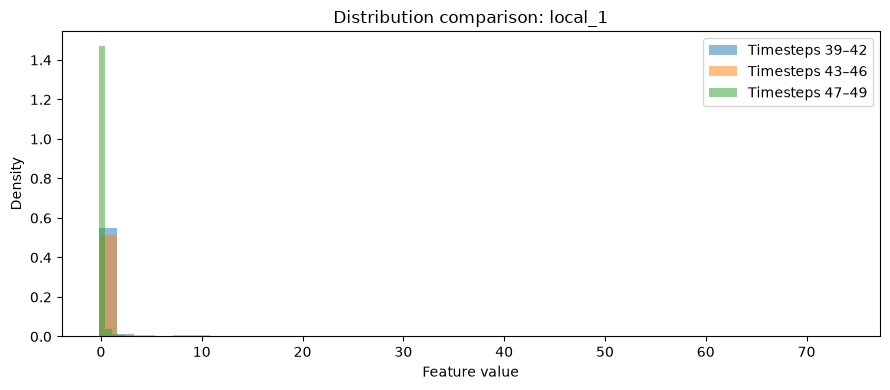

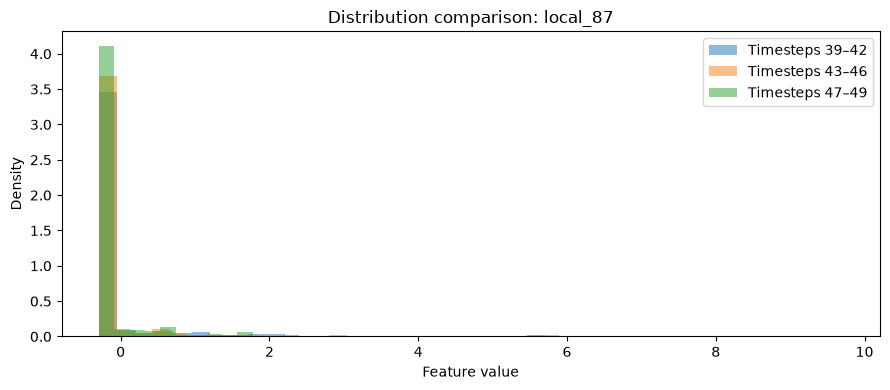

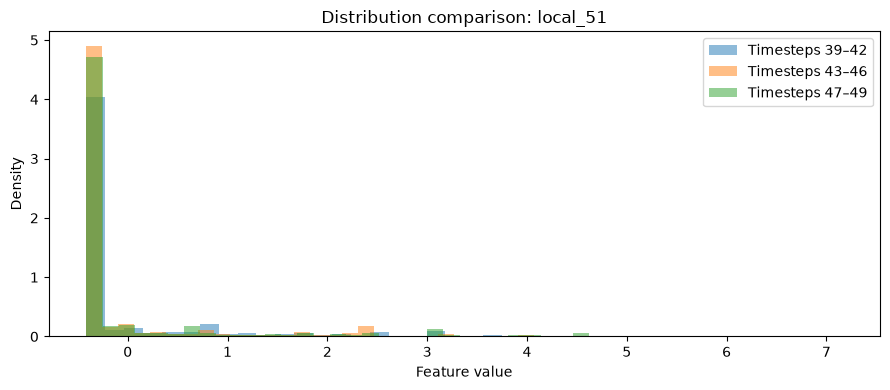

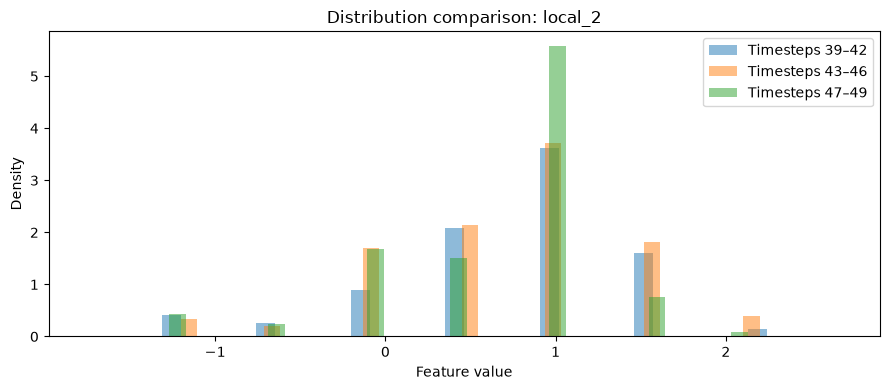

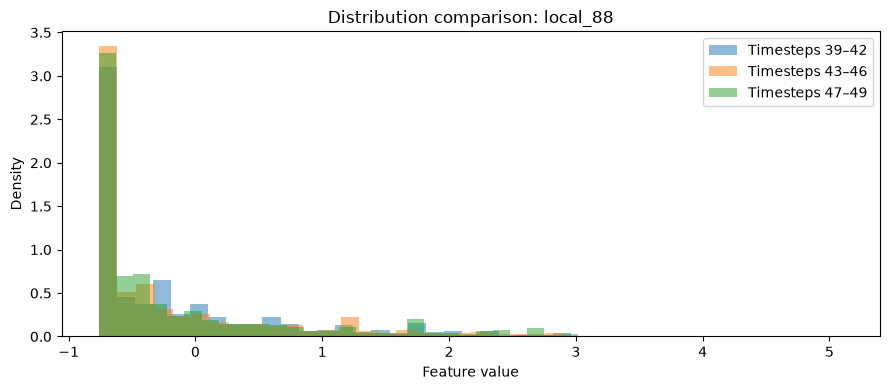

In [47]:
import matplotlib.pyplot as plt

# Top 5 features by PSI during the suspected shift
top_features = (
    shift_results[
        shift_results["comparison"] == "shift_43_46"
    ]
    .nlargest(5, "psi")["feature"]
    .tolist()
)

reference_df = period_data["reference_39_42"]
shift_df = period_data["shift_43_46"]
recovery_df = period_data["recovery_47_49"]

for feature in top_features:

    plt.figure(figsize=(9, 4))

    plt.hist(
        reference_df[feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Timesteps 39–42"
    )

    plt.hist(
        shift_df[feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Timesteps 43–46"
    )

    plt.hist(
        recovery_df[feature],
        bins=40,
        density=True,
        alpha=0.5,
        label="Timesteps 47–49"
    )

    plt.title(f"Distribution comparison: {feature}")
    plt.xlabel("Feature value")
    plt.ylabel("Density")
    plt.legend()
    plt.tight_layout()
    plt.show()


In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Build a temporary diagnostic DataFrame
local1_df = pd.DataFrame({
    "timestep": shift_timesteps.to_numpy(),
    "local_1": X_shift["local_1"].to_numpy(),
})

# Attach original labels.
# Assumes your existing labels Series is indexed by transaction ID,
# and features_df column 0 contains transaction IDs.
tx_ids = features_df.iloc[:, 0].to_numpy()

local1_df["txId"] = tx_ids

# Align labels by transaction ID
label_lookup = labels.copy()
label_lookup.index = label_lookup.index.astype(str)

local1_df["label"] = (
    local1_df["txId"].astype(str)
    .map(label_lookup)
)

# Normalise label representation
local1_df["label"] = (
    local1_df["label"]
    .astype(str)
    .str.lower()
    .replace({
        "1": "illicit",
        "2": "licit"
    })
)

# Per-timestep distribution summary
local1_summary = (
    local1_df.groupby("timestep")
    .agg(
        transaction_count=("local_1", "size"),
        mean=("local_1", "mean"),
        median=("local_1", "median"),
        std=("local_1", "std"),
        q25=("local_1", lambda x: x.quantile(0.25)),
        q75=("local_1", lambda x: x.quantile(0.75)),
        min=("local_1", "min"),
        max=("local_1", "max"),
    )
)

display(local1_summary.loc[35:49])


,transaction_count,mean,median,std,q25,q75,min,max
timestep,,,,,,,,
35,5507,0.077786,-0.092517,0.765760,-0.105252,-0.017450,-0.209968,25.674475
36,6393,0.217551,-0.055242,1.336276,-0.058452,0.140448,-0.198956,39.274987
37,3306,0.182096,-0.057550,1.765192,-0.099402,0.140448,-0.197144,46.109990
38,2891,0.173120,-0.064797,1.856048,-0.094669,0.007084,-0.184668,37.742686
39,2760,0.178647,-0.015038,1.279100,-0.035725,0.044700,-0.184668,26.746654
40,4481,0.379292,0.019174,2.387799,-0.047477,0.119223,-0.197041,45.276689
41,5342,0.227798,0.016048,1.250975,-0.017502,0.098755,-0.205621,25.674475
42,7140,0.248661,0.016948,1.853251,-0.035829,0.095305,-0.210553,70.269380
43,5063,0.976282,0.001681,2.592974,-0.120990,0.188336,-0.205621,22.555329


In [49]:
# Compare distributions by label group and temporal period
local1_df["period"] = pd.cut(
    local1_df["timestep"],
    bins=[34, 42, 46, 49],
    labels=["39-42", "43-46", "47-49"]
)

label_distribution = (
    local1_df.groupby(
        ["period", "label"],
        observed=True
    )
    .agg(
        count=("local_1", "size"),
        mean=("local_1", "mean"),
        median=("local_1", "median"),
        std=("local_1", "std"),
    )
    .reset_index()
)

display(label_distribution)


,period,label,count,mean,median,std
0,39-42,illicit,914,0.137149,0.017707,1.612931
1,39-42,licit,9069,0.512303,0.016948,2.254441
2,39-42,unknown,27837,0.119813,-0.018791,1.320717
3,43-46,illicit,55,1.468329,-0.044246,9.941452
4,43-46,licit,4839,0.723801,0.045417,2.522621
5,43-46,unknown,14261,0.218297,-0.064302,1.409218
6,47-49,illicit,114,0.145818,-0.009338,0.539899
7,47-49,licit,1679,0.683290,-0.009426,2.734617
8,47-49,unknown,8736,-0.023258,-0.093552,0.511727


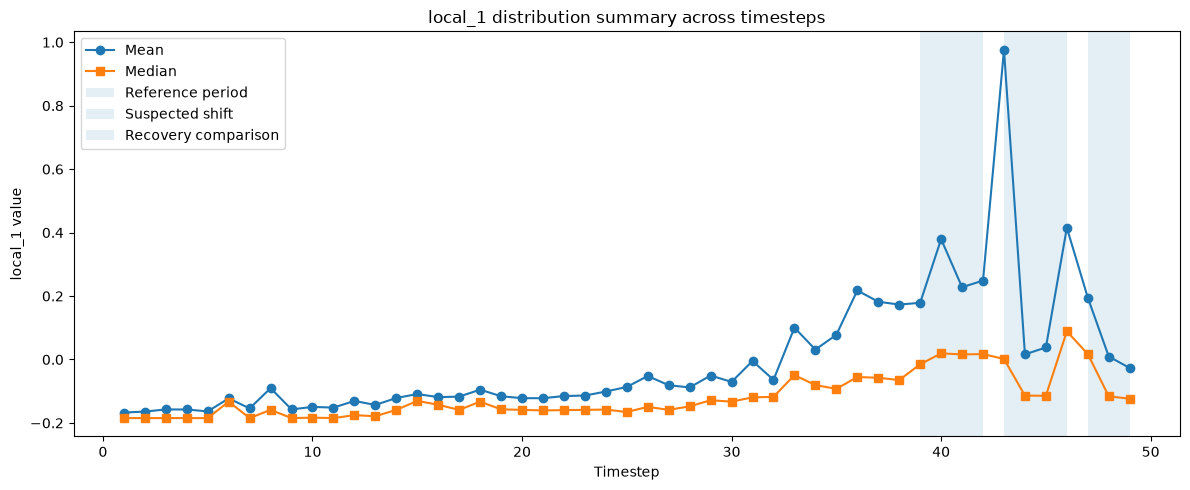

In [50]:

plt.figure(figsize=(12, 5))

plt.plot(
    local1_summary.index,
    local1_summary["mean"],
    marker="o",
    label="Mean"
)

plt.plot(
    local1_summary.index,
    local1_summary["median"],
    marker="s",
    label="Median"
)

plt.axvspan(39, 42, alpha=0.12, label="Reference period")
plt.axvspan(43, 46, alpha=0.12, label="Suspected shift")
plt.axvspan(47, 49, alpha=0.12, label="Recovery comparison")

plt.xlabel("Timestep")
plt.ylabel("local_1 value")
plt.title("local_1 distribution summary across timesteps")
plt.legend()
plt.tight_layout()
plt.show()


In [51]:
# Robust distribution diagnostics for local_1

diagnostic = local1_df.copy()

# Calculate per-timestep percentiles and tail proportions
def summarize_local1(group):
    x = group["local_1"]

    return pd.Series({
        "count": len(x),
        "mean": x.mean(),
        "median": x.median(),
        "std": x.std(),
        "p90": x.quantile(0.90),
        "p95": x.quantile(0.95),
        "p99": x.quantile(0.99),
        "p99_9": x.quantile(0.999),
        "max": x.max(),
        "pct_above_1": (x > 1).mean() * 100,
        "pct_above_5": (x > 5).mean() * 100,
        "pct_above_10": (x > 10).mean() * 100,
    })

tail_summary = (
    diagnostic.groupby("timestep")
    .apply(summarize_local1, include_groups=False)
)

display(tail_summary.loc[35:49].round(4))


,count,mean,median,std,p90,p95,p99,p99_9,max,pct_above_1,pct_above_5,pct_above_10
timestep,,,,,,,,,,,,
35,5507.0,0.0778,-0.0925,0.7658,0.3672,0.8378,2.2410,9.6764,25.6745,3.5228,0.2724,0.0908
36,6393.0,0.2176,-0.0552,1.3363,0.4657,0.8600,4.6230,23.4303,39.2750,4.4893,0.8916,0.2346
37,3306.0,0.1821,-0.0576,1.7652,0.1404,0.3649,3.5283,25.6745,46.1100,1.9661,0.8167,0.4235
38,2891.0,0.1731,-0.0648,1.8560,0.1404,0.3718,3.9578,25.0413,37.7427,2.7672,0.8302,0.5534
39,2760.0,0.1786,-0.0150,1.2791,0.2759,0.7878,2.9728,25.9319,26.7467,4.4928,0.4348,0.2536
40,4481.0,0.3793,0.0192,2.3878,0.4199,0.9847,9.7156,35.3033,45.2767,4.9543,1.6291,1.0042
41,5342.0,0.2278,0.0160,1.2510,0.3965,0.9008,3.1324,18.8344,25.6745,4.7173,0.6926,0.3370
42,7140.0,0.2487,0.0169,1.8533,0.3076,0.8214,4.0580,25.6745,70.2694,4.4118,0.8543,0.4762
43,5063.0,0.9763,0.0017,2.5930,4.7046,8.5759,9.8927,12.7856,22.5553,16.6107,9.7571,0.3753


In [53]:
# Top 20 local_1 values during timesteps 39-49

display(
    diagnostic[
        diagnostic["timestep"].between(39, 49)
    ]
    .nlargest(20, "local_1")[
        ["txId", "timestep", "label", "local_1"]
    ]
)


,txId,timestep,label,local_1
189916,75078587,46,illicit,73.595052
166994,73357055,42,unknown,70.269380
189738,196107869,46,licit,69.469535
157147,847323,40,unknown,45.276689
157188,1503261,40,unknown,45.044759
170917,72720221,42,licit,43.099784
171371,72693336,42,licit,41.884218
168958,34965172,42,unknown,40.321347
157518,1574896,40,unknown,37.186065
157128,708454,40,unknown,36.995551


In [54]:
# Per-timestep local_1 tail analysis by label

tail_by_label = (
    local1_df[
        local1_df["timestep"].between(39, 46)
    ]
    .groupby(["timestep", "label"])
    .agg(
        count=("local_1", "size"),
        mean=("local_1", "mean"),
        median=("local_1", "median"),
        p90=("local_1", lambda x: x.quantile(0.90)),
        p95=("local_1", lambda x: x.quantile(0.95)),
        p99=("local_1", lambda x: x.quantile(0.99)),
        pct_above_5=("local_1", lambda x: (x > 5).mean() * 100),
        pct_above_10=("local_1", lambda x: (x > 10).mean() * 100),
    )
    .reset_index()
)

display(
    tail_by_label.round(4)
)


,timestep,label,count,mean,median,p90,p95,p99,pct_above_5,pct_above_10
0,39,illicit,81,0.0284,0.0163,0.0694,0.0757,0.4181,0.0000,0.0000
1,39,licit,1102,0.3145,-0.0150,0.6646,1.2901,4.8178,0.9074,0.5445
2,39,unknown,1577,0.0915,-0.0078,0.1821,0.3891,1.9715,0.1268,0.0634
3,40,illicit,112,0.3586,0.1087,0.3999,0.5913,7.5332,1.7857,0.8929
4,40,licit,1099,0.9753,0.0729,1.4600,3.7580,22.0973,4.2766,2.9117
5,40,unknown,3270,0.1797,-0.0039,0.1945,0.4193,2.3532,0.7339,0.3670
6,41,illicit,116,0.0783,0.0680,0.1607,0.1660,0.3141,0.0000,0.0000
7,41,licit,1016,0.7069,0.0306,1.6120,2.5462,17.8560,2.5591,1.3780
8,41,unknown,4210,0.1163,0.0160,0.2624,0.4880,1.7242,0.2613,0.0950
9,42,illicit,239,0.0899,0.0840,0.1602,0.1760,0.3452,0.0000,0.0000


## Post-hoc investigation: Temporal performance degradation (Timesteps 43–46)

### 1. Motivation

The Track B temporal evaluation revealed a substantial deterioration in model performance on timesteps 43–46 (test window corresponding to cutoff 42).

This degradation affected both model families:

- **XGBoost (Local):** Average Precision decreased from approximately 0.884 in the preceding test window (timesteps 39–42) to 0.055 in timesteps 43–46.
- **GraphSAGE (Local):** Average Precision decreased from approximately 0.830 to 0.032 over the same comparison.

Since the deterioration was observed across both tree-based and graph-based models, a post-hoc investigation was conducted to examine whether changes in the feature distributions could provide additional context.

### 2. Per-timestep model performance

The test window was broken down into individual timesteps to identify whether the performance deterioration was concentrated in a particular period.

The investigation showed:

- Performance was already weak at timestep 43.
- Timestep 44 showed relatively better ranking performance for XGBoost, although results remained poor overall.
- Timestep 45 showed another deterioration.
- Timestep 46 appeared to have comparatively higher Average Precision, but this result is highly unstable because only **two labelled illicit transactions** were present.

The number of labelled illicit transactions was particularly small in the later timesteps:

| Timestep | Labelled transactions | Illicit transactions | Illicit prevalence |
|---|---:|---:|---:|
| 43 | 1,370 | 24 | 1.75% |
| 44 | 1,591 | 24 | 1.51% |
| 45 | 1,221 | 5 | 0.41% |
| 46 | 712 | 2 | 0.28% |
| **43–46** | **4,894** | **55** | **1.12%** |

The very low number of positive examples in timesteps 45 and 46 makes per-timestep metrics sensitive to individual predictions. These results should therefore be interpreted cautiously.

### 3. Feature distribution analysis

The distribution of the 93 local transaction features was compared between:

- Reference period: timesteps 39–42
- Shifted period: timesteps 43–46
- Subsequent period: timesteps 47–49

The comparison used the Kolmogorov–Smirnov (KS) statistic and Population Stability Index (PSI).

For timesteps 43–46 compared with timesteps 39–42:

- Mean KS statistic across local features: approximately **0.0401**
- Median KS statistic: approximately **0.0368**
- Mean PSI: approximately **0.0286**
- Median PSI: approximately **0.0102**
- Only one feature had PSI greater than 0.1.

This suggests that the observed distributional change was not uniformly spread across all local features.

### 4. Investigation of `local_1`

The most prominent distributional change was observed in `local_1`.

| Statistic | Timesteps 39–42 | Timesteps 43–46 |
|---|---:|---:|
| KS statistic | — | 0.3790 |
| PSI | — | 1.3099 |
| Mean | 0.2629 | 0.3496 |

The feature exhibited a substantial upper-tail shift during timestep 43.

| Statistic | Timestep 42 | Timestep 43 |
|---|---:|---:|
| Mean | 0.2487 | 0.9763 |
| Median | 0.0169 | 0.0017 |
| 90th percentile | 0.3076 | 4.7046 |
| 95th percentile | 0.8214 | 8.5759 |
| Percentage of values above 5 | 4.41% | 16.61% |
| Percentage of values above 10 | 0.85% | 9.76% |

The increase in the upper percentiles and the proportion of observations above 5 and 10 indicates that this was not simply a change in the mean. A considerably larger fraction of transactions had high `local_1` values during timestep 43.

### 5. Which label groups contributed to the shift?

The label-wise breakdown provides an important qualification.

At timestep 43:

- **Illicit:** 24 transactions, with mean `local_1` approximately 0.0051.
- **Licit:** 1,346 transactions, with mean approximately 1.5344.
- **Unknown:** 3,693 transactions, with mean approximately 0.7792.

The illicit transactions at timestep 43 did not exhibit the same high upper-tail values observed in the licit and unknown populations.

This suggests that the prominent timestep 43 shift in `local_1` was primarily associated with the licit and unknown populations, rather than being driven by the labelled illicit transactions.

Timestep 46 contained an extreme `local_1` value among its two illicit transactions. However, a conclusion based on only two observations would be unreliable.

### 6. Interpretation and limitations

The investigation identifies a concentrated feature-distribution shift, particularly in `local_1` during timestep 43. It also establishes that the temporal performance deterioration is not exclusive to the GNN models.

However, several distinctions are important:

1. **Covariate shift is not proof of concept drift.** The observed feature distribution changes do not establish that the relationship between features and illicit labels changed.
2. **The shift is not established as the cause of model failure.** The analysis is descriptive and does not isolate the causal contribution of `local_1` or any other feature to the performance deterioration.
3. **Class prevalence matters.** The illicit prevalence in timesteps 43–46 was approximately 1.12%, substantially lower than in the preceding test window. This affects the interpretation of Average Precision.
4. **The small positive sample sizes matter.** Per-timestep results, particularly for timesteps 45 and 46, are unstable because of the limited number of labelled illicit transactions.
5. **Unknown labels remain unknown.** They are included in the feature-distribution analysis but are not treated as licit observations.

### 7. Key takeaway

The post-hoc investigation identified a pronounced upper-tail distribution shift in `local_1`, concentrated particularly in timestep 43 and largely associated with licit and unknown transactions.

The broader deterioration in model performance across timesteps 43–46 affects both XGBoost and GraphSAGE, suggesting that explicit graph message passing does not protect against this temporal instability.

These findings motivate further investigation into anomaly-based ranking methods, while keeping the distinction between distribution shift, model performance degradation, and actual changes in illicit behaviour explicit.|